# Modelo OLS — preparación por segmentos de distancia

Esta primera etapa prepara cuatro segmentos de entrenamiento y una transformación Box-Cox propia de cada uno. Se parte exclusivamente de los CSV procesados, sin repetir limpieza, imputación o codificación. Test se carga solo para validar su estructura y queda reservado. No se entrenan regresiones, no se aplica selección de características ni VIF y no se excluyen observaciones.

Las tablas Markdown se generan a partir de los cálculos de esta ejecución y se guardan en celdas para facilitar su copia. Los parámetros indispensables se conservan en los Joblib; si cambian los archivos de entrada, deben actualizarse también las tablas guardadas.

## 1. Carga y validación de datasets

Se verifican filas, columnas, tipos numéricos, finitud y presencia de `price_rub` y `to_center_km`. Train y test deben tener exactamente el mismo esquema. Las validaciones de test no se utilizan para aprender parámetros.

In [1]:
from pathlib import Path
import joblib
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox, norm
from importlib.metadata import version

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "Fase_2/data/train_ols_usadas.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró Fase_2/data/train_ols_usadas.csv dentro del proyecto.")
carpeta_datos = raiz / "Fase_2/data"
ruta_train = carpeta_datos / "train_ols_usadas.csv"
ruta_test = carpeta_datos / "test_ols_usadas.csv"
huellas_entrada = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [ruta_train, ruta_test]}
train = pd.read_csv(ruta_train)
test = pd.read_csv(ruta_test)
assert train.shape[0] == 40_000 and test.shape[0] == 10_000
assert train.columns.equals(test.columns) and train.dtypes.equals(test.dtypes)
assert train.columns.is_unique and {"price_rub", "to_center_km"}.issubset(train)
for datos in [train, test]:
    assert all(pd.api.types.is_numeric_dtype(tipo) for tipo in datos.dtypes)
    assert not datos.isna().any().any() and np.isfinite(datos.to_numpy()).all()
    assert datos.to_center_km.ge(0).all()
test_referencia = test.copy(deep=True)
resumen_entrada = pd.DataFrame([{"Conjunto": nombre, "Observaciones": len(datos), "Columnas": datos.shape[1],
    "Nulos en precio/distancia": int(datos[["price_rub", "to_center_km"]].isna().sum().sum())}
    for nombre, datos in [("Train", train), ("Test reservado", test)]])
sns.set_theme(style="whitegrid", context="notebook")
COLOR = "#287C8E"

def formato_md(valor, decimales=4):
    if isinstance(valor, str): return valor.replace("|", chr(92) + "|")
    if pd.isna(valor): return "No estimable"
    if isinstance(valor, (int, np.integer)): return f"{valor:,}".replace(",", ".")
    return f"{valor:,.{decimales}f}".translate(str.maketrans({",": ".", ".": ","}))

def tabla_markdown(tabla):
    lineas = ["| " + " | ".join(formato_md(col) for col in tabla.columns) + " |", "| " + " | ".join(["---"] * len(tabla.columns)) + " |"]
    for fila in tabla.itertuples(index=False, name=None):
        lineas.append("| " + " | ".join(formato_md(valor) for valor in fila) + " |")
    return "\n".join(lineas)
ruta_modelos_originales = carpeta_datos / "modelos_ols_por_segmento.joblib"
ruta_modelos_sin_centro = carpeta_datos / "modelos_ols_sin_to_center_km.joblib"
cache_originales_ols = joblib.load(ruta_modelos_originales) if ruta_modelos_originales.exists() else None
cache_sin_centro_ols = joblib.load(ruta_modelos_sin_centro) if ruta_modelos_sin_centro.exists() else None


**Dimensiones y validación de las entradas**

| Conjunto | Observaciones | Columnas | Nulos en precio/distancia |
| --- | --- | --- | --- |
| Train | 40.000 | 164 | 0 |
| Test reservado | 10.000 | 164 | 0 |

## 2. Segmentación por distancia al centro

Se calculan una sola vez los percentiles 25, 50 y 75 de `to_center_km` en train, con interpolación lineal. Se asigna cada observación a un único segmento: **Muy cercanas** ≤ Q1; **Cercanas** > Q1 y ≤ Q2; **Intermedias** > Q2 y ≤ Q3; **Lejanas** > Q3. Los empates se asignan al intervalo inferior, por lo que las cantidades pueden diferir de 10.000. No se consultan cuartiles de test.

In [2]:
cuartiles_train = (pd.Series(cache_originales_ols["parametros_segmentacion_boxcox"]["cuartiles_distancia_km"].values(), index=[0.25,0.50,0.75])
                   if cache_originales_ols is not None else train.to_center_km.quantile([0.25,0.50,0.75]))
limites_distancia_train = {"Q1": float(cuartiles_train.loc[0.25]),
                           "Q2": float(cuartiles_train.loc[0.50]),
                           "Q3": float(cuartiles_train.loc[0.75])}
orden_segmentos = ["Muy cercanas", "Cercanas", "Intermedias", "Lejanas"]
def asignar_segmento_distancia(distancias, limites):
    if not (np.isfinite(distancias) & distancias.ge(0)).all():
        raise ValueError("Se requieren distancias finitas y no negativas.")
    return pd.Categorical(np.select(
        [distancias.le(limites["Q1"]), distancias.le(limites["Q2"]), distancias.le(limites["Q3"])],
        orden_segmentos[:3], default="Lejanas"), categories=orden_segmentos, ordered=True)

train_segmentado = train.copy(deep=True)
train_segmentado["segmento_distancia"] = asignar_segmento_distancia(train.to_center_km, limites_distancia_train)
tabla_limites = pd.DataFrame([{"Cuartil de train": clave, "Distancia (km)": valor}
                              for clave, valor in limites_distancia_train.items()])
tabla_distancias = train_segmentado.groupby("segmento_distancia", observed=False).agg(
    cantidad=("price_rub", "size"), distancia_minima=("to_center_km", "min"),
    distancia_maxima=("to_center_km", "max"), distancia_mediana=("to_center_km", "median")).reset_index()
tabla_distancias.columns = ["Segmento", "Cantidad", "Distancia mínima (km)", "Distancia máxima (km)", "Distancia mediana (km)"]
mascaras_segmentos = np.column_stack([train_segmentado.segmento_distancia.eq(s) for s in orden_segmentos])
assert mascaras_segmentos.sum(axis=1).tolist() == [1] * len(train)
assert tabla_distancias.Cantidad.sum() == len(train)
assert not train_segmentado.segmento_distancia.isna().any()

**Cuartiles aprendidos exclusivamente de train**

| Cuartil de train | Distancia (km) |
| --- | --- |
| Q1 | 9,0300 |
| Q2 | 13,2300 |
| Q3 | 18,0300 |

**Cantidad y distancias por segmento de entrenamiento**

| Segmento | Cantidad | Distancia mínima (km) | Distancia máxima (km) | Distancia mediana (km) |
| --- | --- | --- | --- | --- |
| Muy cercanas | 10.017 | 0,0700 | 9,0300 | 5,9100 |
| Cercanas | 10.003 | 9,0400 | 13,2300 | 11,2700 |
| Intermedias | 9.984 | 13,2400 | 18,0300 | 15,1500 |
| Lejanas | 9.996 | 18,0400 | 70,4000 | 27,0200 |

## 3. Estadísticas originales por segmento

Los precios se expresan en millones de RUB solo en esta presentación; `price_rub` permanece en RUB. La desviación estándar es muestral (`ddof=1`); asimetría y curtosis excesiva de Fisher son adimensionales y corregidas por sesgo (normal: curtosis excesiva = 0).

In [3]:
def metricas_precio(valores):
    return {"Cantidad": int(valores.count()), "Media": valores.mean(), "Mediana": valores.median(),
        "Desvío": valores.std(ddof=1), "Mínimo": valores.min(), "Máximo": valores.max(),
        "Asimetría": valores.skew(), "Curtosis excesiva": valores.kurt()}

segmentos_train = {s: train_segmentado.loc[train_segmentado.segmento_distancia.eq(s)].copy()
                   for s in orden_segmentos}
tabla_originales = pd.DataFrame([{"Segmento": segmento, **metricas_precio(datos.price_rub / 1e6)}
                                for segmento, datos in segmentos_train.items()])
tabla_originales = tabla_originales.rename(columns={c: f"{c} (millones RUB)"
    for c in ["Media", "Mediana", "Desvío", "Mínimo", "Máximo"]})

**Distribución original del precio por segmento**

| Segmento | Cantidad | Media (millones RUB) | Mediana (millones RUB) | Desvío (millones RUB) | Mínimo (millones RUB) | Máximo (millones RUB) | Asimetría | Curtosis excesiva |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 10.017 | 20,1331 | 17,4780 | 10,6730 | 3,6120 | 93,4370 | 1,5511 | 3,4503 |
| Cercanas | 10.003 | 13,2752 | 12,1080 | 5,8185 | 3,1560 | 55,9270 | 1,3362 | 2,7450 |
| Intermedias | 9.984 | 10,9598 | 9,8930 | 4,9275 | 2,4910 | 51,5540 | 1,6717 | 4,8674 |
| Lejanas | 9.996 | 6,7723 | 5,8570 | 3,8779 | 1,0190 | 33,7420 | 1,5709 | 3,7067 |

## 4. Transformación Box-Cox

Cada λ se estima por máxima verosimilitud con `scipy.stats.boxcox` sobre los precios originales en RUB del segmento correspondiente, sin desplazamiento ni estandarización. La transformación es `(x**λ − 1) / λ` para λ ≠ 0 y `ln(x)` para λ = 0. Se comprueba positividad, finitud y variación antes de ajustar. No se utiliza ningún λ global.

`train_boxcox` conserva las variables originales y agrega la transformación, con los mismos índices y 40.000 filas. `segmentos_train_boxcox` mantiene los cuatro grupos listos para una etapa futura.

In [4]:
train_boxcox = train_segmentado.copy(deep=True)
train_boxcox["boxcox_price_rub"] = np.nan
lambdas_por_segmento = {}
filas_lambda = []
for segmento in orden_segmentos:
    mascara = train_boxcox.segmento_distancia.eq(segmento)
    precios_segmento = train_boxcox.loc[mascara, "price_rub"]
    if not (np.isfinite(precios_segmento) & precios_segmento.gt(0)).all() or precios_segmento.nunique() < 2:
        raise ValueError(f"{segmento}: se requieren precios finitos, positivos y no constantes.")
    if cache_originales_ols is not None:
        lambda_segmento = cache_originales_ols["parametros_segmentacion_boxcox"]["lambda_por_segmento"][segmento]
        transformados = boxcox(precios_segmento.to_numpy(dtype=float), lmbda=lambda_segmento)
    else:
        transformados, lambda_segmento = boxcox(precios_segmento.to_numpy(dtype=float))
    lambdas_por_segmento[segmento] = float(lambda_segmento)
    train_boxcox.loc[mascara, "boxcox_price_rub"] = transformados
    filas_lambda.append({"Segmento": segmento, "Cantidad": len(precios_segmento), "λ Box-Cox": lambda_segmento})
tabla_lambdas = pd.DataFrame(filas_lambda)
segmentos_train_boxcox = {s: train_boxcox.loc[train_boxcox.segmento_distancia.eq(s)].copy() for s in orden_segmentos}
assert len(train_boxcox) == 40_000 and train_boxcox.index.equals(train.index)
assert np.isfinite(train_boxcox.boxcox_price_rub).all()
pd.testing.assert_frame_equal(train_boxcox[train.columns], train)
pd.testing.assert_frame_equal(test, test_referencia)
assert "segmento_distancia" not in test and "boxcox_price_rub" not in test

**Parámetro Box-Cox independiente por segmento**

| Segmento | Cantidad | λ Box-Cox |
| --- | --- | --- |
| Muy cercanas | 10.017 | -0,0948 |
| Cercanas | 10.003 | -0,0757 |
| Intermedias | 9.984 | -0,1584 |
| Lejanas | 9.996 | -0,0319 |

## 5. Comparación gráfica antes y después

Una fila por segmento: precio original en millones de RUB a la izquierda y escala Box-Cox específica del segmento a la derecha. Los ocho histogramas usan densidad, KDE y una normal con la media y el desvío muestral de sus propios datos. A indica asimetría y K curtosis excesiva. Las escalas horizontales se ajustan de forma independiente: no se comparan directamente magnitudes en RUB con Box-Cox.

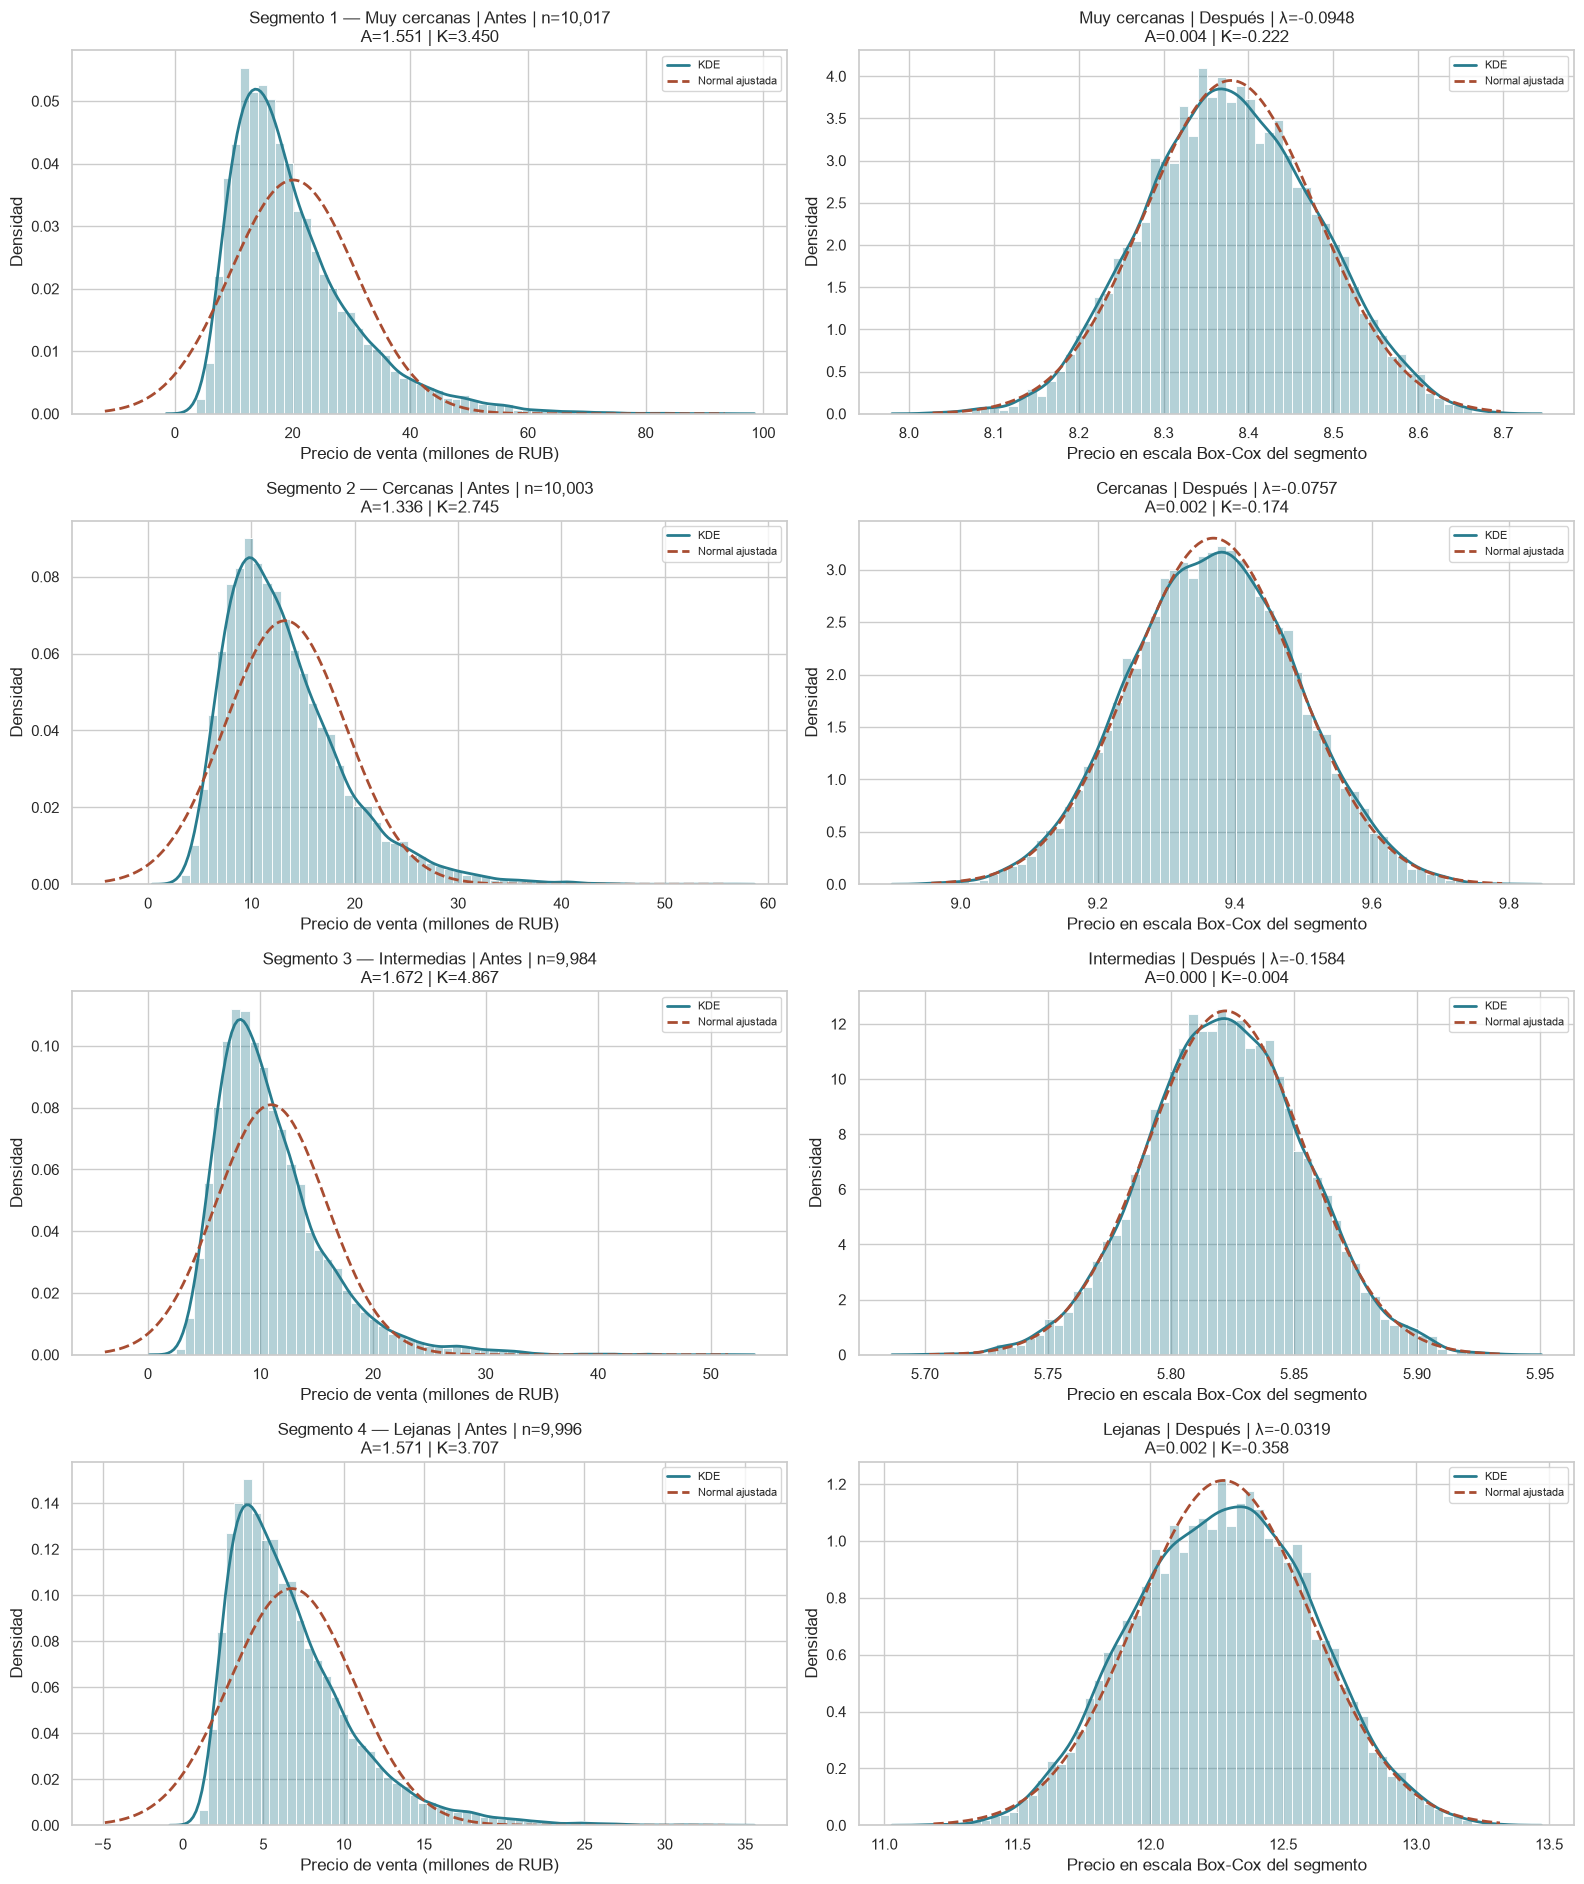

In [5]:
def graficar_densidad(ax, valores, titulo, etiqueta_x):
    valores = pd.Series(valores)
    media, desvio = valores.mean(), valores.std(ddof=1)
    x = np.linspace(min(valores.min(), media - 3 * desvio), max(valores.max(), media + 3 * desvio), 600)
    sns.histplot(x=valores, bins=60, stat="density", color=COLOR, alpha=0.35, ax=ax)
    sns.kdeplot(x=valores, color=COLOR, linewidth=2, label="KDE", ax=ax)
    ax.plot(x, norm.pdf(x, media, desvio), color="#A84D32", linestyle="--", linewidth=2, label="Normal ajustada")
    ax.set(title=titulo, xlabel=etiqueta_x, ylabel="Densidad")
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(4, 2, figsize=(16, 19), sharex=False)
for fila, segmento in enumerate(orden_segmentos):
    datos = segmentos_train_boxcox[segmento]
    original = datos.price_rub / 1e6
    transformado = datos.boxcox_price_rub
    titulo_original = (f"Segmento {fila + 1} — {segmento} | Antes | n={len(datos):,}\n"
                       f"A={original.skew():.3f} | K={original.kurt():.3f}")
    titulo_transformado = (f"{segmento} | Después | λ={lambdas_por_segmento[segmento]:.4f}\n"
                           f"A={transformado.skew():.3f} | K={transformado.kurt():.3f}")
    graficar_densidad(axes[fila, 0], original, titulo_original, "Precio de venta (millones de RUB)")
    graficar_densidad(axes[fila, 1], transformado, titulo_transformado, "Precio en escala Box-Cox del segmento")
plt.tight_layout()
plt.show()

## 6. Comparación de métricas

La tabla principal reúne λ, asimetría y curtosis excesiva antes y después. La segunda cuantifica la cercanía a cero con los valores absolutos. **Reducción = |métrica original| − |métrica transformada|**: un valor positivo indica acercamiento a cero; uno negativo, alejamiento. La máxima verosimilitud no minimiza por separado estas dos métricas y no demuestra normalidad.

In [6]:
filas_comparacion, filas_cambio = [], []
for segmento, datos in segmentos_train_boxcox.items():
    antes, despues = metricas_precio(datos.price_rub), metricas_precio(datos.boxcox_price_rub)
    filas_comparacion.append({"Segmento": segmento, "λ Box-Cox": lambdas_por_segmento[segmento],
        "Asimetría original": antes["Asimetría"], "Asimetría Box-Cox": despues["Asimetría"],
        "Curtosis original": antes["Curtosis excesiva"], "Curtosis Box-Cox": despues["Curtosis excesiva"]})
    filas_cambio.append({"Segmento": segmento,
        "Asimetría original (abs.)": abs(antes["Asimetría"]), "Asimetría Box-Cox (abs.)": abs(despues["Asimetría"]),
        "Reducción de asimetría absoluta": abs(antes["Asimetría"]) - abs(despues["Asimetría"]),
        "Curtosis original (abs.)": abs(antes["Curtosis excesiva"]), "Curtosis Box-Cox (abs.)": abs(despues["Curtosis excesiva"]),
        "Reducción de curtosis absoluta": abs(antes["Curtosis excesiva"]) - abs(despues["Curtosis excesiva"])})
tabla_comparacion = pd.DataFrame(filas_comparacion)
tabla_cambio_absoluto = pd.DataFrame(filas_cambio)

**Comparación de la forma antes y después de Box-Cox**

| Segmento | λ Box-Cox | Asimetría original | Asimetría Box-Cox | Curtosis original | Curtosis Box-Cox |
| --- | --- | --- | --- | --- | --- |
| Muy cercanas | -0,0948 | 1,5511 | 0,0036 | 3,4503 | -0,2225 |
| Cercanas | -0,0757 | 1,3362 | 0,0018 | 2,7450 | -0,1737 |
| Intermedias | -0,1584 | 1,6717 | 0,0002 | 4,8674 | -0,0041 |
| Lejanas | -0,0319 | 1,5709 | 0,0021 | 3,7067 | -0,3577 |

**Distancias respecto de cero y cambio absoluto**

| Segmento | Asimetría original (abs.) | Asimetría Box-Cox (abs.) | Reducción de asimetría absoluta | Curtosis original (abs.) | Curtosis Box-Cox (abs.) | Reducción de curtosis absoluta |
| --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 1,5511 | 0,0036 | 1,5475 | 3,4503 | 0,2225 | 3,2278 |
| Cercanas | 1,3362 | 0,0018 | 1,3344 | 2,7450 | 0,1737 | 2,5713 |
| Intermedias | 1,6717 | 0,0002 | 1,6716 | 4,8674 | 0,0041 | 4,8633 |
| Lejanas | 1,5709 | 0,0021 | 1,5689 | 3,7067 | 0,3577 | 3,3490 |

## 7. Registro de parámetros para test

La configuración se conserva únicamente en `data/modelos_ols_por_segmento.joblib` con los cuartiles de train, los cuatro λ, sus condiciones de asignación y el esquema de columnas. Ese objeto identifica que Box-Cox recibe RUB, no millones de RUB ni logaritmos.

Para procesar test posteriormente se asignará cada propiedad con estos mismos límites y se aplicará el λ guardado de su segmento, conservando `price_rub`. La función reutilizable siguiente implementa ese contrato sin ningún ajuste; en este notebook **no se aplica a test**. La comprobación utiliza únicamente train y verifica que reproduce las transformaciones ya calculadas.

In [7]:
condiciones_segmentos = ["to_center_km <= Q1", "Q1 < to_center_km <= Q2", "Q2 < to_center_km <= Q3", "to_center_km > Q3"]
parametros_boxcox = {
    "version": 1, "ajuste": "Exclusivamente train; sin ajustes con test",
    "versiones": {p: version(p) for p in ["numpy", "pandas", "scipy"]},
    "entradas": huellas_entrada, "columna_distancia": "to_center_km", "objetivo_original": "price_rub",
    "columna_segmento": "segmento_distancia", "columna_transformada": "boxcox_price_rub",
    "unidad_entrada_boxcox": "RUB", "metodo_lambda": "Máxima verosimilitud por segmento, scipy.stats.boxcox",
    "cuartiles_distancia_km": limites_distancia_train, "orden_segmentos": orden_segmentos,
    "lambda_por_segmento": lambdas_por_segmento,
    "segmentos": [{"codigo": i + 1, "nombre": s, "condicion": condiciones_segmentos[i],
                   "lambda": lambdas_por_segmento[s], "cantidad_train": len(segmentos_train_boxcox[s])}
                  for i, s in enumerate(orden_segmentos)],
    "columnas_entrada": train.columns.tolist(), "tipos_entrada": train.dtypes.astype(str).to_dict(),
    "columnas_predictoras_originales": [c for c in train if c != "price_rub"],
    "columnas_salida": train_boxcox.columns.tolist(),
    "tipos_salida": train_boxcox.dtypes.astype(str).to_dict(),
    "filas_train": len(train), "filas_test_reservadas": len(test)}
parametros_recargados = (cache_originales_ols["parametros_segmentacion_boxcox"]
                          if cache_originales_ols is not None else parametros_boxcox)
assert parametros_recargados == parametros_boxcox

def aplicar_parametros_boxcox(datos, parametros):
    if datos.columns.tolist() != parametros["columnas_entrada"]:
        raise ValueError("El esquema de entrada no coincide con el contrato guardado.")
    salida = datos.copy(deep=True)
    limites = parametros["cuartiles_distancia_km"]
    nombres = parametros["orden_segmentos"]
    distancias = salida[parametros["columna_distancia"]]
    if not (np.isfinite(distancias) & distancias.ge(0)).all():
        raise ValueError("Hay distancias inválidas; revisar antes de aplicar parámetros.")
    etiquetas = pd.Categorical(np.select(
        [distancias.le(limites["Q1"]), distancias.le(limites["Q2"]), distancias.le(limites["Q3"])],
        nombres[:3], default=nombres[3]), categories=nombres, ordered=True)
    salida[parametros["columna_segmento"]] = etiquetas
    salida[parametros["columna_transformada"]] = np.nan
    for nombre in nombres:
        mascara = salida[parametros["columna_segmento"]].eq(nombre)
        precios = salida.loc[mascara, parametros["objetivo_original"]]
        if not (np.isfinite(precios) & precios.gt(0)).all():
            raise ValueError("Box-Cox requiere precios estrictamente positivos y finitos.")
        if mascara.any():
            salida.loc[mascara, parametros["columna_transformada"]] = boxcox(
                precios.to_numpy(dtype=float), lmbda=parametros["lambda_por_segmento"][nombre])
    return salida[parametros["columnas_salida"]]

reproduccion_train = aplicar_parametros_boxcox(train, parametros_recargados)
pd.testing.assert_frame_equal(reproduccion_train, train_boxcox)
pd.testing.assert_frame_equal(train_boxcox[train.columns], train)
pd.testing.assert_frame_equal(test, test_referencia)
assert "segmento_distancia" not in test and "boxcox_price_rub" not in test
assert all(hashlib.sha256((carpeta_datos / nombre).read_bytes()).hexdigest() == huella
           for nombre, huella in huellas_entrada.items())
resumen_registro = pd.DataFrame([{"Archivo": "modelos_ols_por_segmento.joblib", "Segmentos": len(lambdas_por_segmento),
    "Train conservado": len(train_boxcox), "Test reservado sin transformar": len(test),
    "Columnas train original": train.shape[1], "Columnas train con segmento y Box-Cox": train_boxcox.shape[1]}])

**Parámetros centralizados y verificados**

| Archivo | Segmentos | Train conservado | Test reservado sin transformar | Columnas train original | Columnas train con segmento y Box-Cox |
| --- | --- | --- | --- | --- | --- |
| modelos_ols_por_segmento.joblib | 4 | 40.000 | 10.000 | 164 | 166 |

## 8. Modelo OLS — Muy cercanas

Los cuatro ajustes siguientes utilizan únicamente train. Test se asigna con los límites ya registrados; sus datos no intervienen en rango, VIF, selección de columnas ni estimación. Solo se excluyen constantes y dependencias exactas detectadas en cada train. No se realiza selección por significancia ni regularización.

Las funciones compartidas presentan el mismo conjunto de tablas para cada modelo. La comprobación de rango centra y reescala únicamente una matriz auxiliar para estabilizar el cálculo QR; el OLS utiliza las variables originales sin estandarizarlas. El VIF se calcula con intercepto mediante la diagonal de la inversa de la matriz de correlación de X, equivalente a las regresiones auxiliares. No se reemplazan VIF infinitos o no estimables ni se eliminan predictores por VIF.

In [8]:
import statsmodels.api as sm
from scipy.linalg import qr
from scipy.special import inv_boxcox
from statsmodels.stats.stattools import omni_normtest, jarque_bera, durbin_watson
import joblib

columnas_predictoras_ols = parametros_recargados["columnas_predictoras_originales"]
assert not {"price_rub", "boxcox_price_rub", "segmento_distancia", "id", "date_posted_dt"}.intersection(columnas_predictoras_ols)
test_segmentado_ols = test.copy(deep=True)
test_segmentado_ols["segmento_distancia"] = asignar_segmento_distancia(test.to_center_km, limites_distancia_train)
assert test_segmentado_ols.segmento_distancia.notna().all()
modelos_ols, tablas_ols, registros_ols, resumenes_ols, evaluaciones_ols = {}, {}, {}, {}, {}

def tabla_modelo_md(tabla):
    def formato(v):
        if isinstance(v, str): return v.replace("|", chr(92) + "|").replace("\n", " ")
        if v is None or pd.isna(v): return "No calculable"
        if isinstance(v, (bool, np.bool_)): return "Sí" if v else "No"
        if np.isinf(v): return "+∞" if v > 0 else "−∞"
        if isinstance(v, (int, np.integer)) or (isinstance(v, (float, np.floating)) and float(v).is_integer()): return f"{int(v):,}".replace(",", ".")
        if v != 0 and (abs(v) < 1e-4 or abs(v) >= 1e9): return f"{v:.6e}"
        return f"{v:,.6f}".translate(str.maketrans({",": ".", ".": ","}))
    lineas = ["| " + " | ".join(formato(c) for c in tabla.columns) + " |",
              "| " + " | ".join(["---"] * len(tabla.columns)) + " |"]
    for fila in tabla.itertuples(index=False, name=None): lineas.append("| " + " | ".join(formato(v) for v in fila) + " |")
    return "\n".join(lineas)

def errores_prediccion(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    error = real - pred
    mse = np.mean(error ** 2)
    return {"R²": 1 - np.sum(error ** 2) / np.sum((real - real.mean()) ** 2),
            "MAE": np.mean(np.abs(error)), "MSE": mse, "RMSE": np.sqrt(mse)}

def inversa_verificada(pred, lambda_segmento):
    pred = np.asarray(pred, dtype=float)
    valido = np.isfinite(pred)
    if lambda_segmento != 0: valido &= (1 + lambda_segmento * pred) > 0
    invertido = np.full(pred.shape, np.nan)
    with np.errstate(over="ignore", invalid="ignore"):
        invertido[valido] = inv_boxcox(pred[valido], lambda_segmento)
    valido &= np.isfinite(invertido) & (invertido > 0)
    invertido[~valido] = np.nan
    return invertido, valido

def ajustar_segmento_ols(segmento, columnas_predictoras=None, destino=None):
    # Sin argumentos adicionales se conserva el comportamiento de los modelos originales.
    if columnas_predictoras is None:
        columnas_predictoras = globals()["columnas_predictoras_ols"]
    if destino is None:
        destino = {k: globals()[v] for k, v in {
            "modelos": "modelos_ols", "tablas": "tablas_ols", "registros": "registros_ols",
            "resumenes": "resumenes_ols", "evaluaciones": "evaluaciones_ols"}.items()}
    columnas_predictoras_ols = list(columnas_predictoras)
    modelos_ols, tablas_ols, registros_ols = destino["modelos"], destino["tablas"], destino["registros"]
    resumenes_ols, evaluaciones_ols = destino["resumenes"], destino["evaluaciones"]
    datos = segmentos_train_boxcox[segmento]
    prueba = test_segmentado_ols.loc[test_segmentado_ols.segmento_distancia.eq(segmento)].copy()
    X = datos[columnas_predictoras_ols].astype(float)
    constantes = X.columns[X.nunique(dropna=False).le(1)].tolist()
    candidatas = [c for c in X if c not in constantes]
    medias = X[candidatas].mean()
    desvios = X[candidatas].std(ddof=0)
    Z = ((X[candidatas] - medias) / desvios).to_numpy()
    _, R, piv = qr(Z, mode="economic", pivoting=True, check_finite=False)
    tol = np.finfo(float).eps * max(Z.shape) * np.abs(np.diag(R)).max()
    rango = int((np.abs(np.diag(R)) > tol).sum())
    indices_independientes = sorted(piv[:rango].tolist())
    utilizadas = [candidatas[i] for i in indices_independientes]
    dependientes = [c for c in candidatas if c not in utilizadas]
    descartadas = [{"Variable": c, "Motivo": "Constante dentro del train del segmento", "Dependencia en matriz auxiliar": "No aplica"} for c in constantes]
    relaciones_dependencias = {}
    if dependientes:
        Z_ind = Z[:, indices_independientes]
        for c in dependientes:
            objetivo = Z[:, candidatas.index(c)]
            beta = np.linalg.lstsq(Z_ind, objetivo, rcond=None)[0]
            error_rel = np.linalg.norm(objetivo - Z_ind @ beta) / np.linalg.norm(objetivo)
            assert error_rel < 1e-8
            relacion = {col: float(b) for col, b in zip(utilizadas, beta) if abs(b) > 1e-8}
            relaciones_dependencias[c] = {"coeficientes_estandarizados": relacion, "error_relativo": float(error_rel)}
            descripcion_relacion = "; ".join(f"{b:+.6g} × {col}" for col, b in relacion.items())
            dummies_district = [col for col in candidatas if col.startswith("district_")]
            if c.startswith("district_") and all(col.startswith("district_") for col in relacion) and X[dummies_district].sum(axis=1).eq(1).all():
                descripcion_relacion = (f"Intercepto = suma de {len(dummies_district)} dummies district activas; "
                    f"se adopta {c} como referencia local. Columnas involucradas registradas en JSON y coeficientes.")
            descartadas.append({"Variable": c, "Motivo": "Dependencia lineal exacta en train",
                                "Dependencia en matriz auxiliar": descripcion_relacion})
    X_ajuste = sm.add_constant(X[utilizadas], has_constant="add")
    X_prueba = sm.add_constant(prueba[utilizadas].astype(float), has_constant="add").reindex(columns=X_ajuste.columns)
    assert np.isfinite(X_ajuste).all().all() and np.isfinite(X_prueba).all().all()
    assert np.linalg.matrix_rank(X_ajuste.to_numpy()) == X_ajuste.shape[1]
    cache = cache_originales_ols if "to_center_km" in columnas_predictoras_ols else cache_sin_centro_ols
    if cache is not None and segmento in cache["modelos"]:
        resultado = cache["modelos"][segmento]
        assert resultado.model.exog_names == X_ajuste.columns.tolist()
        np.testing.assert_array_equal(resultado.model.exog, X_ajuste.to_numpy())
        np.testing.assert_array_equal(resultado.model.endog, datos.boxcox_price_rub.to_numpy())
    else:
        resultado = sm.OLS(datos.boxcox_price_rub, X_ajuste, missing="raise").fit()
    modelos_ols[segmento] = resultado
    resumen = resultado.summary()
    resumenes_ols[segmento] = resumen
    intervalo = resultado.conf_int(alpha=0.05)
    coeficientes = pd.DataFrame({"Variable": resultado.params.index, "coef": resultado.params.to_numpy(),
        "std err": resultado.bse.to_numpy(), "t": resultado.tvalues.to_numpy(), "P>|t|": resultado.pvalues.to_numpy(),
        "IC 95 % inferior": intervalo.iloc[:, 0].to_numpy(), "IC 95 % superior": intervalo.iloc[:, 1].to_numpy()})
    coeficientes = pd.concat([coeficientes.loc[coeficientes.Variable.eq("const")],
        coeficientes.loc[~coeficientes.Variable.eq("const")].sort_values("P>|t|", kind="stable")], ignore_index=True)
    significativos = int(resultado.pvalues.drop("const").lt(0.05).sum())
    no_significativos = len(utilizadas) - significativos
    omni, omni_p = omni_normtest(resultado.resid)
    jb, jb_p, skew, kurtosis = jarque_bera(resultado.resid)
    dw = durbin_watson(resultado.resid)
    generales = {"Dependent Variable": resultado.model.endog_names, "Model": resultado.model.__class__.__name__,
        "Method": "Least Squares", "No. Observations": int(resultado.nobs), "Df Model": resultado.df_model,
        "Df Residuals": resultado.df_resid, "R-squared": resultado.rsquared, "Adj. R-squared": resultado.rsquared_adj,
        "F-statistic": resultado.fvalue, "Prob (F-statistic)": resultado.f_pvalue,
        "Log-Likelihood": resultado.llf, "AIC": resultado.aic, "BIC": resultado.bic, "Covariance Type": resultado.cov_type}
    for fila in resumen.tables[0].data:
        for j in [0, 2]:
            if fila[j].strip() in ["Date:", "Time:"]: generales[fila[j].strip(": ")] = fila[j + 1].strip()
    diagnosticos = {"Omnibus": omni, "Prob(Omnibus)": omni_p, "Jarque-Bera (JB)": jb, "Prob(JB)": jb_p,
        "Skew": skew, "Kurtosis convencional (normal=3)": kurtosis, "Durbin-Watson": dw, "Condition Number": resultado.condition_number}
    residuos = {"Media de residuos (Box-Cox)": resultado.resid.mean(), "Desvío muestral (Box-Cox)": resultado.resid.std(ddof=1),
        "MSE (Box-Cox², divisor n)": np.mean(resultado.resid ** 2), "RMSE (Box-Cox)": np.sqrt(np.mean(resultado.resid ** 2)),
        "MAE (Box-Cox)": np.mean(np.abs(resultado.resid))}
    correlacion = X[utilizadas].corr().to_numpy()
    try:
        vifs = np.diag(np.linalg.inv(correlacion))
    except np.linalg.LinAlgError:
        vifs = np.full(len(utilizadas), np.nan)
    tabla_vif = pd.DataFrame({"Predictor": utilizadas, "VIF": vifs}).sort_values("VIF", ascending=False, na_position="last")
    controles_vif = {"VIF > 5": int((vifs > 5).sum()), "VIF > 10": int((vifs > 10).sum()),
                    "VIF infinitos": int(np.isinf(vifs).sum()), "VIF no calculables": int(np.isnan(vifs).sum())}
    evaluacion = []
    lambda_segmento = lambdas_por_segmento[segmento]
    for nombre, d, M in [("Train", datos, X_ajuste), ("Test", prueba, X_prueba)]:
        pred_box = resultado.predict(M).to_numpy()
        real_box = d.boxcox_price_rub.to_numpy() if nombre == "Train" else boxcox(d.price_rub.to_numpy(dtype=float), lmbda=lambda_segmento)
        pred_rub, validos = inversa_verificada(pred_box, lambda_segmento)
        evaluacion.append({"Conjunto": nombre, "Escala": "Box-Cox", "N total": len(d), "N evaluado": len(d),
            "Inversas inválidas": int((~validos).sum()), **errores_prediccion(real_box, pred_box)})
        if validos.all():
            metricas_rub = errores_prediccion(d.price_rub, pred_rub)
            evaluacion.append({"Conjunto": nombre, "Escala": "RUB", "N total": len(d), "N evaluado": len(d),
                "Inversas inválidas": 0, **metricas_rub})
        else:
            evaluacion.append({"Conjunto": nombre, "Escala": "RUB: muestra completa no evaluable", "N total": len(d), "N evaluado": 0,
                "Inversas inválidas": int((~validos).sum()), **{k: np.nan for k in ["R²", "MAE", "MSE", "RMSE"]}})
            if validos.any(): evaluacion.append({"Conjunto": nombre, "Escala": "RUB: solo inversas válidas", "N total": len(d),
                "N evaluado": int(validos.sum()), "Inversas inválidas": int((~validos).sum()),
                **errores_prediccion(d.price_rub.to_numpy()[validos], pred_rub[validos])})
    tabla_evaluacion = pd.DataFrame(evaluacion)
    evaluaciones_ols[segmento] = tabla_evaluacion
    registros_ols[segmento] = {"predictoras": utilizadas, "orden_con_intercepto": X_ajuste.columns.tolist(),
        "constantes_excluidas": constantes, "dependencias_excluidas": dependientes,
        "relaciones_dependencias": relaciones_dependencias, "medias_auxiliar_rango": medias.to_dict(),
        "desvios_auxiliar_rango": desvios.to_dict(), "lambda": float(lambda_segmento),
        "n_train": len(datos), "n_test": len(prueba), "rango_con_intercepto": X_ajuste.shape[1],
        "rango_auxiliar_tolerancia": float(tol), "seleccion_estadistica": False}
    tablas_ols[segmento] = {
        "preparacion": pd.DataFrame([{"Observaciones train": len(datos), "Observaciones test": len(prueba),
            "Predictoras iniciales": len(columnas_predictoras_ols), "Constantes excluidas": len(constantes),
            "Dependencias excluidas": len(dependientes), "Predictoras utilizadas": len(utilizadas), "λ": lambda_segmento}]),
        "descartadas": pd.DataFrame(descartadas, columns=["Variable", "Motivo", "Dependencia en matriz auxiliar"]),
        "generales": pd.DataFrame(generales.items(), columns=["Métrica", "Valor"]),
        "coeficientes": coeficientes,
        "significancia": pd.DataFrame([{"Predictores con p < 0,05 (sin intercepto)": significativos,
                                         "Predictores con p ≥ 0,05": no_significativos}]),
        "diagnosticos": pd.DataFrame(diagnosticos.items(), columns=["Métrica", "Valor"]),
        "residuos": pd.DataFrame(residuos.items(), columns=["Métrica", "Valor"]),
        "vif": tabla_vif, "conteos_vif": pd.DataFrame([controles_vif]), "evaluacion": tabla_evaluacion}
    return resultado

**Unidad de análisis: características completas.** `district`, `building_type`, `renovation` y `metro_line` son bloques nominales. Las binarias y numéricas son características individuales; año y mes de publicación se conservan como dos características numéricas derivadas. Cantidad de características y cantidad de parámetros se presentan por separado; el intercepto cuenta como parámetro, no como característica.

La significancia nominal se evalúa con una F conjunta. Para GVIF se utiliza la matriz de correlaciones de los coeficientes sin intercepto: GVIF = det(R del bloque) × det(R del complemento) / det(R completo); se presenta GVIF^(1/(2 × df)), donde df es la cantidad de parámetros estimables del bloque. Este valor no se contrasta con el umbral tradicional de VIF = 5. Los coeficientes y VIF por dummy permanecen internos, sin desplegarse por defecto.

In [16]:
# Contrato de características: dummies internas, decisiones por bloques completos.
registro_preparacion_features = joblib.load(carpeta_datos / "transformadores_ols_usadas.joblib")["registro"]
esquema_features_ols = {}
for feature, columnas in registro_preparacion_features["dummies"].items():
    esquema_features_ols[feature] = {"tipo": "Nominal", "columnas_originales": columnas,
        "referencia_original": registro_preparacion_features["referencias"][feature]}
for feature in registro_preparacion_features["binarias"]:
    esquema_features_ols[feature] = {"tipo": "Binaria", "columnas_originales": [feature], "referencia_original": None}
columnas_agrupadas = {c for feature in esquema_features_ols.values() for c in feature["columnas_originales"]}
for columna in registro_preparacion_features["columnas_finales"]:
    if columna not in columnas_agrupadas:
        esquema_features_ols[columna] = {"tipo": "Numérica", "columnas_originales": [columna], "referencia_original": None}
assert {c for f in esquema_features_ols.values() for c in f["columnas_originales"]} == set(columnas_predictoras_ols)
assert sum(len(f["columnas_originales"]) for f in esquema_features_ols.values()) == len(columnas_predictoras_ols)

def analizar_por_features(modelo, registro):
    nombres = list(modelo.model.exog_names)
    activas = [c for c in nombres if c != "const"]
    X = modelo.model.exog[:, [nombres.index(c) for c in activas]]
    vif_interno = dict(zip(activas, np.diag(np.linalg.inv(np.corrcoef(X, rowvar=False)))))
    cov = np.asarray(modelo.cov_params())[1:, 1:]
    R = cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))
    signo_R, logdet_R = np.linalg.slogdet(R)
    contrato, estados, significancias, vifs = {}, [], [], []
    for feature, esquema in esquema_features_ols.items():
        columnas = [c for c in activas if c in esquema["columnas_originales"]]
        excluidas = [c for c in esquema["columnas_originales"] if c not in columnas]
        estado = "Incluida" if columnas else "Excluida"
        referencia_local = [c for c in registro.get("dependencias_excluidas", []) if c in esquema["columnas_originales"]]
        contrato[feature] = {**esquema, "columnas_modelo": columnas, "parametros": len(columnas), "estado": estado,
            "columnas_no_estimadas": excluidas, "restricciones_rango_locales": referencia_local}
        estados.append({"Característica": feature, "Tipo": esquema["tipo"], "Columnas de codificación": len(esquema["columnas_originales"]),
            "Parámetros estimados": len(columnas), "Estado": estado,
            "Referencia original": esquema["referencia_original"] or "No aplica",
            "Restricciones adicionales de rango": len(referencia_local)})
        if not columnas: continue
        posiciones = [nombres.index(c) for c in columnas]
        if esquema["tipo"] == "Nominal" or len(columnas) > 1:
            restriccion = np.zeros((len(columnas), len(nombres)))
            restriccion[np.arange(len(columnas)), posiciones] = 1
            prueba = modelo.f_test(restriccion)
            p_global = float(np.asarray(prueba.pvalue).item())
            metodo = f"F parcial conjunta ({len(columnas)} parámetros)"
        else:
            p_global = float(modelo.pvalues[columnas[0]])
            metodo = "t del coeficiente"
        significancias.append({"Característica": feature, "Tipo": esquema["tipo"], "Parámetros asociados": len(columnas),
            "Significancia global (p)": p_global, "Prueba": metodo})
        indices = [activas.index(c) for c in columnas]
        complemento = [i for i in range(len(activas)) if i not in indices]
        signo_a, logdet_a = np.linalg.slogdet(R[np.ix_(indices, indices)])
        signo_b, logdet_b = np.linalg.slogdet(R[np.ix_(complemento, complemento)]) if complemento else (1, 0.0)
        gvif = np.exp(logdet_a + logdet_b - logdet_R) if min(signo_R, signo_a, signo_b) > 0 else np.nan
        # Para 1 df, el GVIF sin ajustar coincide con el VIF tradicional.
        if len(columnas) == 1 and np.isfinite(gvif):
            np.testing.assert_allclose(gvif, vif_interno[columnas[0]], rtol=1e-6, atol=1e-6)
        gvif_ajustado = gvif ** (1 / (2 * len(columnas))) if esquema["tipo"] == "Nominal" else "No aplica"
        valores_vif = np.asarray([vif_interno[c] for c in columnas])
        vifs.append({"Característica": feature, "Tipo": esquema["tipo"], "Parámetros asociados": len(columnas),
            "VIF máximo": valores_vif.max(), "Columnas con VIF > 5": int((valores_vif > 5).sum()),
            "GVIF ajustado": gvif_ajustado})
    tabla_vif_features = pd.DataFrame(vifs).sort_values("VIF máximo", ascending=False)
    tabla_significancia = pd.DataFrame(significancias).sort_values("Significancia global (p)", kind="stable")
    assert sum(f["parametros"] for f in contrato.values()) == len(activas)
    cantidades = {tipo: sum(f["estado"] == "Incluida" and f["tipo"] == tipo for f in contrato.values())
                  for tipo in ["Numérica", "Binaria", "Nominal", "Ordinal"]}
    recuento = {"Características incluidas": sum(cantidades.values()), **cantidades,
        "Parámetros totales (con intercepto)": len(nombres),
        "Características con VIF > 5": int(tabla_vif_features["VIF máximo"].gt(5).sum()),
        "Características con VIF > 10": int(tabla_vif_features["VIF máximo"].gt(10).sum())}
    return {"contrato": contrato, "estados": pd.DataFrame(estados), "significancia": tabla_significancia,
        "vif": tabla_vif_features, "recuento": recuento, "vif_columnas_interno": vif_interno}

def columnas_por_caracteristicas(features, contrato):
    if len(features) != len(set(features)): raise ValueError("Características repetidas.")
    desconocidas = set(features) - set(contrato)
    if desconocidas: raise ValueError(f"Usar nombres de características completas, no dummies: {desconocidas}")
    if any(contrato[f]["estado"] != "Incluida" for f in features):
        raise ValueError("Una característica no estimable en este modelo no puede reincorporarse automáticamente.")
    return [c for f in features for c in contrato[f]["columnas_modelo"]]

def validar_bloques_features(columnas, contrato):
    seleccionadas = set(columnas) - {"const"}
    disponibles = {c for f in contrato.values() for c in f["columnas_modelo"]}
    if seleccionadas - disponibles: raise ValueError("Columnas ajenas al contrato del modelo.")
    for feature, info in contrato.items():
        bloque = set(info["columnas_modelo"])
        if seleccionadas & bloque and not bloque.issubset(seleccionadas):
            raise ValueError(f"No se permite seleccionar parcialmente la característica {feature}.")
    return True

def ampliar_comparacion_features(comparacion, analisis):
    tabla = comparacion.loc[~comparacion["Métrica"].isin(["Cantidad de VIF > 5", "Cantidad de VIF > 10"])].copy()
    tabla["Métrica"] = tabla["Métrica"].replace({"Cantidad de predictores": "Parámetros explicativos (sin intercepto)"})
    filas = [{"Métrica": metrica, **{s: analisis[s]["recuento"][clave] for s in orden_segmentos}}
             for metrica, clave in [("Características originales incluidas", "Características incluidas"),
                 ("Características numéricas", "Numérica"), ("Características binarias", "Binaria"),
                 ("Características categóricas nominales", "Nominal"), ("Características ordinales", "Ordinal"),
                 ("Parámetros totales estimados (con intercepto)", "Parámetros totales (con intercepto)"),
                 ("Características con VIF > 5", "Características con VIF > 5"),
                 ("Características con VIF > 10", "Características con VIF > 10")]]
    return pd.concat([tabla.iloc[:2], pd.DataFrame(filas), tabla.iloc[2:]], ignore_index=True)

analisis_features_ols = {}

In [9]:
modelo_muy_cercanas = ajustar_segmento_ols("Muy cercanas")
analisis_features_ols["Muy cercanas"] = analizar_por_features(modelos_ols["Muy cercanas"], registros_ols["Muy cercanas"])


**Dimensiones: características y parámetros del modelo**

| Observaciones train | Observaciones test | Características incluidas | Numérica | Binaria | Nominal | Ordinal | Parámetros totales (con intercepto) | Características con VIF > 5 | Características con VIF > 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 10.017 | 2.512 | 20 | 13 | 3 | 4 | 0 | 94 | 0 | 0 |

**Características: estado y codificación interna**

Las columnas excluidas por constancia o rango se conservan en el contrato en memoria, reconstruido desde los Joblib. Las restricciones locales ya existían en el ajuste; no se cambia la referencia original ni se modifica el modelo.

| Característica | Tipo | Columnas de codificación | Parámetros estimados | Estado | Referencia original | Restricciones adicionales de rango |
| --- | --- | --- | --- | --- | --- | --- |
| district | Nominal | 128 | 58 | Incluida | Aeroport | 0 |
| building_type | Nominal | 5 | 5 | Incluida | brick | 0 |
| renovation | Nominal | 3 | 3 | Incluida | cosmetic | 0 |
| metro_line | Nominal | 11 | 11 | Incluida | Arbatsko-Pokrovskaya | 0 |
| has_balcony | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| seller_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| total_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| kitchen_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| floor | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| total_floors | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| building_year | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| ceiling_height | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_min | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mortgage_key_rate_at_listing | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| secondary_mom_change_pct | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| anio_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mes_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |

**Métricas generales del modelo**

| Métrica | Valor |
| --- | --- |
| Dependent Variable | boxcox_price_rub |
| Model | OLS |
| Method | Least Squares |
| No. Observations | 10.017 |
| Df Model | 93 |
| Df Residuals | 9.923 |
| R-squared | 0,941272 |
| Adj. R-squared | 0,940722 |
| F-statistic | 1.710,136795 |
| Prob (F-statistic) | 0 |
| Log-Likelihood | 22.948,474294 |
| AIC | -45.708,948587 |
| BIC | -45.031,016928 |
| Covariance Type | nonrobust |
| Date | Wed, 28 Oct 2026 |
| Time | 13:41:02 |

**Significancia global por característica**

Para nominales se contrasta conjuntamente el bloque estimable mediante F parcial; para numéricas y binarias se utiliza el p-value del coeficiente. Los coeficientes individuales permanecen en `modelos_ols`, `tablas_ols` y el resumen completo desplegable.

| Característica | Tipo | Parámetros asociados | Significancia global (p) | Prueba |
| --- | --- | --- | --- | --- |
| district | Nominal | 58 | 0 | F parcial conjunta (58 parámetros) |
| building_type | Nominal | 5 | 0 | F parcial conjunta (5 parámetros) |
| renovation | Nominal | 3 | 0 | F parcial conjunta (3 parámetros) |
| total_area | Numérica | 1 | 0 | t del coeficiente |
| metro_distance_min | Numérica | 1 | 0 | t del coeficiente |
| anio_publicacion | Numérica | 1 | 0 | t del coeficiente |
| mes_publicacion | Numérica | 1 | 4.489504e-115 | t del coeficiente |
| metro_to_center_km | Numérica | 1 | 5.362495e-54 | t del coeficiente |
| metro_distance_type | Binaria | 1 | 1.412690e-53 | t del coeficiente |
| has_balcony | Binaria | 1 | 4.096758e-21 | t del coeficiente |
| ceiling_height | Numérica | 1 | 1.842376e-11 | t del coeficiente |
| to_center_km | Numérica | 1 | 1.205115e-10 | t del coeficiente |
| metro_line | Nominal | 11 | 3.778819e-08 | F parcial conjunta (11 parámetros) |
| kitchen_area | Numérica | 1 | 0,000811 | t del coeficiente |
| mortgage_key_rate_at_listing | Numérica | 1 | 0,006164 | t del coeficiente |
| floor | Numérica | 1 | 0,018045 | t del coeficiente |
| total_floors | Numérica | 1 | 0,061110 | t del coeficiente |
| seller_type | Binaria | 1 | 0,379868 | t del coeficiente |
| secondary_mom_change_pct | Numérica | 1 | 0,841007 | t del coeficiente |
| building_year | Numérica | 1 | 0,863691 | t del coeficiente |

**Significancia descriptiva por característica, sin selección**

| Características con p global < 0,05 | Características con p global ≥ 0,05 |
| --- | --- |
| 16 | 4 |

**Diagnóstico estadístico de los residuos**

La curtosis del resumen OLS es convencional: la referencia normal es 3, no 0.

| Métrica | Valor |
| --- | --- |
| Omnibus | 97,517416 |
| Prob(Omnibus) | 6.673631e-22 |
| Jarque-Bera (JB) | 120,332528 |
| Prob(JB) | 7.415213e-27 |
| Skew | -0,166738 |
| Kurtosis convencional (normal=3) | 3,420834 |
| Durbin-Watson | 1,772154 |
| Condition Number | 6.390.294,567508 |

**Errores residuales de entrenamiento en escala Box-Cox**

| Métrica | Valor |
| --- | --- |
| Media de residuos (Box-Cox) | -1.573380e-12 |
| Desvío muestral (Box-Cox) | 0,024481 |
| MSE (Box-Cox², divisor n) | 0,000599 |
| RMSE (Box-Cox) | 0,024480 |
| MAE (Box-Cox) | 0,019265 |

**Multicolinealidad por característica**

El máximo y el recuento se calculan con los VIF internos de las columnas; no equivalen a una medida única de inflación de toda una característica categórica. GVIF ajustado es complementario y no se compara con el umbral VIF = 5.

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| building_year | Numérica | 1 | 4,746473 | 0 | No aplica |
| to_center_km | Numérica | 1 | 4,601530 | 0 | No aplica |
| district | Nominal | 58 | 3,096583 | 0 | 1,025670 |
| building_type | Nominal | 5 | 3,001671 | 0 | 1,207661 |
| metro_line | Nominal | 11 | 2,983144 | 0 | 1,057446 |
| mortgage_key_rate_at_listing | Numérica | 1 | 2,602626 | 0 | No aplica |
| anio_publicacion | Numérica | 1 | 2,587783 | 0 | No aplica |
| metro_distance_min | Numérica | 1 | 1,603339 | 0 | No aplica |
| floor | Numérica | 1 | 1,557661 | 0 | No aplica |
| total_floors | Numérica | 1 | 1,556904 | 0 | No aplica |
| metro_to_center_km | Numérica | 1 | 1,526197 | 0 | No aplica |
| metro_distance_type | Binaria | 1 | 1,522318 | 0 | No aplica |
| ceiling_height | Numérica | 1 | 1,480066 | 0 | No aplica |
| kitchen_area | Numérica | 1 | 1,311476 | 0 | No aplica |
| total_area | Numérica | 1 | 1,310375 | 0 | No aplica |
| renovation | Nominal | 3 | 1,232936 | 0 | 1,004028 |
| secondary_mom_change_pct | Numérica | 1 | 1,038888 | 0 | No aplica |
| mes_publicacion | Numérica | 1 | 1,014239 | 0 | No aplica |
| seller_type | Binaria | 1 | 1,010548 | 0 | No aplica |
| has_balcony | Binaria | 1 | 1,009457 | 0 | No aplica |

**Características con multicolinealidad elevada**

| Características con VIF > 5 | Características con VIF > 10 |
| --- | --- |
| 0 | 0 |

**Evaluación diferenciada por conjunto y escala**

MAE/RMSE usan unidades de la escala indicada y MSE sus unidades al cuadrado. La inversión directa de Box-Cox no aplica una corrección del sesgo de retransfomación. Las inversas fuera de dominio no se recortan ni se usan para reajustar: se informa su cobertura y, si corresponde, la imposibilidad de evaluar la muestra completa.

| Conjunto | Escala | N total | N evaluado | Inversas inválidas | R² | MAE | MSE | RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Train | Box-Cox | 10.017 | 10.017 | 0 | 0,941272 | 0,019265 | 0,000599 | 0,024480 |
| Train | RUB | 10.017 | 10.017 | 0 | 0,930327 | 1.885.716,696416 | 7.935980e+12 | 2.817.087,227740 |
| Test | Box-Cox | 2.512 | 2.512 | 0 | 0,835566 | 0,032697 | 0,001518 | 0,038959 |
| Test | RUB | 2.512 | 2.512 | 0 | 0,724745 | 4.086.242,440011 | 3.624271e+13 | 6.020.192,172579 |

<details>
<summary>Resumen completo de statsmodels.OLS — Muy cercanas</summary>

<pre>                            OLS Regression Results                            
==============================================================================
Dep. Variable:       boxcox_price_rub   R-squared:                       0.941
Model:                            OLS   Adj. R-squared:                  0.941
Method:                 Least Squares   F-statistic:                     1710.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:41:02   Log-Likelihood:                 22948.
No. Observations:               10017   AIC:                        -4.571e+04
Df Residuals:                    9923   BIC:                        -4.503e+04
Df Model:                          93                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P&gt;|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                     -29.6142      0.554    -53.482      0.000     -30.700     -28.529
total_area                                  0.0030   1.64e-05    185.885      0.000       0.003       0.003
kitchen_area                               -0.0003   9.86e-05     -3.350      0.001      -0.001      -0.000
floor                                       0.0001   5.47e-05      2.365      0.018    2.21e-05       0.000
total_floors                             8.789e-05   4.69e-05      1.873      0.061    -4.1e-06       0.000
building_year                           -4.037e-06   2.35e-05     -0.172      0.864   -5.01e-05    4.21e-05
ceiling_height                              0.0090      0.001      6.726      0.000       0.006       0.012
metro_distance_min                         -0.0014   2.27e-05    -62.475      0.000      -0.001      -0.001
to_center_km                               -0.0015      0.000     -6.446      0.000      -0.002      -0.001
mortgage_key_rate_at_listing               -0.0002   7.62e-05     -2.740      0.006      -0.000   -5.94e-05
secondary_mom_change_pct                 1.394e-05   6.95e-05      0.201      0.841      -0.000       0.000
metro_to_center_km                          0.0014   8.95e-05     15.566      0.000       0.001       0.002
anio_publicacion                            0.0187      0.000     68.017      0.000       0.018       0.019
mes_publicacion                             0.0016   7.09e-05     23.103      0.000       0.001       0.002
has_balcony                                 0.0054      0.001      9.452      0.000       0.004       0.006
metro_distance_type                         0.0098      0.001     15.503      0.000       0.009       0.011
seller_type                                -0.0005      0.001     -0.878      0.380      -0.001       0.001
district_Akademichesky                      0.0348      0.002     15.678      0.000       0.030       0.039
district_Alekseevsky                       -0.0018      0.002     -0.832      0.406      -0.006       0.002
district_Arbat                              0.1562      0.002     62.879      0.000       0.151       0.161
district_Basmanny                           0.1001      0.002     43.742      0.000       0.096       0.105
district_Begovoy                            0.0232      0.002     11.019      0.000       0.019       0.027
district_Bogorodskoye                      -0.0448      0.003    -16.208      0.000      -0.050      -0.039
district_Butyrsky                          -0.0172      0.002     -7.927      0.000      -0.022      -0.013
district_Chertanovo Severnoye              -0.0428      0.007     -5.869      0.000      -0.057      -0.029
district_Cheryomushki                       0.0291      0.003      8.702      0.000       0.023       0.036
district_Danilovsky                         0.0002      0.002      0.084      0.933      -0.004       0.005
district_Donskoy                            0.0145      0.002      6.498      0.000       0.010       0.019
district_Dorogomilovo                       0.0951      0.002     42.673      0.000       0.091       0.099
district_Fili-Davydkovo                     0.0433      0.003     15.365      0.000       0.038       0.049
district_Filyovsky Park                     0.0448      0.002     18.296      0.000       0.040       0.050
district_Gagarinsky                         0.0652      0.002     29.993      0.000       0.061       0.069
district_Golovinsky                        -0.0578      0.025     -2.339      0.019      -0.106      -0.009
district_Izmaylovo                         -0.0305      0.004     -6.784      0.000      -0.039      -0.022
district_Khamovniki                         0.1606      0.002     70.085      0.000       0.156       0.165
district_Khoroshyovo-Mnyovniki              0.0259      0.003      8.557      0.000       0.020       0.032
district_Khoroshyovsky                      0.0298      0.002     13.983      0.000       0.026       0.034
district_Koptevo                           -0.0100      0.014     -0.696      0.486      -0.038       0.018
district_Kotlovka                           0.0137      0.003      5.097      0.000       0.008       0.019
district_Krasnoselsky                       0.0898      0.002     38.640      0.000       0.085       0.094
district_Kuntsevo                          -0.0135      0.014     -0.945      0.345      -0.042       0.015
district_Lomonosovsky                       0.0598      0.002     25.713      0.000       0.055       0.064
district_Marfino                           -0.0352      0.004     -9.614      0.000      -0.042      -0.028
district_Maryina Roshcha                   -0.0028      0.002     -1.235      0.217      -0.007       0.002
district_Meshchansky                        0.1001      0.002     42.423      0.000       0.095       0.105
district_Metrogorodok                      -0.0680      0.007     -9.320      0.000      -0.082      -0.054
district_Moskvorechye-Saburovo             -0.0745      0.014     -5.207      0.000      -0.103      -0.046
district_Nagatino-Sadovniki                -0.0260      0.002    -11.064      0.000      -0.031      -0.021
district_Nagatinsky Zaton                  -0.0146      0.003     -5.623      0.000      -0.020      -0.010
district_Nagorny                           -0.0256      0.003     -9.140      0.000      -0.031      -0.020
district_Novogireyevo                      -0.0377      0.009     -3.975      0.000      -0.056      -0.019
district_Obruchevsky                        0.0227      0.009      2.554      0.011       0.005       0.040
district_Ochakovo-Matveyevskoye            -0.0062      0.025     -0.250      0.803      -0.055       0.042
district_Ostankinsky                       -0.0043      0.002     -1.893      0.058      -0.009       0.000
district_Otradnoye                         -0.0082      0.018     -0.470      0.638      -0.043       0.026
district_Perovo                            -0.0393      0.005     -8.325      0.000      -0.049      -0.030
district_Preobrazhenskoye                  -0.0206      0.002     -9.021      0.000      -0.025      -0.016
district_Presnensky                         0.1435      0.002     60.429      0.000       0.139       0.148
district_Prospekt Vernadskogo               0.0698      0.011      6.274      0.000       0.048       0.092
district_Ramenki                            0.0649      0.003     25.068      0.000       0.060       0.070
district_Rostokino                         -0.0412      0.003    -12.904      0.000      -0.047      -0.035
district_Savyolovsky                        0.0118      0.002      5.395      0.000       0.008       0.016
district_Shchukino                          0.0299      0.008      3.918      0.000       0.015       0.045
district_Sokol                              0.0227      0.002      9.230      0.000       0.018       0.028
district_Sokolinaya Gora                   -0.0488      0.002    -21.673      0.000      -0.053      -0.044
district_Sokolniki                         -0.0019      0.002     -0.829      0.407      -0.006       0.003
district_Sviblovo                          -0.0406      0.006     -6.875      0.000      -0.052      -0.029
district_Tagansky                           0.0911      0.002     38.842      0.000       0.087       0.096
district_Timiryazevsky                     -0.0094      0.002     -4.335      0.000      -0.014      -0.005
district_Tverskoy                           0.1504      0.002     61.708      0.000       0.146       0.155
district_Veshnyaki                         -0.0746      0.025     -3.017      0.003      -0.123      -0.026
district_Voykovsky                         -0.0222      0.005     -4.650      0.000      -0.032      -0.013
district_Yakimanka                          0.1462      0.002     60.513      0.000       0.141       0.151
district_Zamoskvorechye                     0.1175      0.002     48.642      0.000       0.113       0.122
district_Zyuzino                            0.0087      0.006      1.360      0.174      -0.004       0.021
building_type_khrushchev                   -0.0438      0.001    -46.886      0.000      -0.046      -0.042
building_type_modern_panel                 -0.0102      0.001     -9.525      0.000      -0.012      -0.008
building_type_monolith                      0.0096      0.001      8.972      0.000       0.007       0.012
building_type_panel                        -0.0274      0.001    -34.209      0.000      -0.029      -0.026
building_type_stalin                        0.0272      0.002     18.075      0.000       0.024       0.030
renovation_designer                         0.0622      0.001     70.450      0.000       0.060       0.064
renovation_euro                             0.0294      0.001     49.669      0.000       0.028       0.031
renovation_no_renovation                   -0.0240      0.001    -35.329      0.000      -0.025      -0.023
metro_line_Bolshaya Koltsevaya             -0.0029      0.002     -1.439      0.150      -0.007       0.001
metro_line_Filyovskaya                     -0.0017      0.001     -1.314      0.189      -0.004       0.001
metro_line_Kalininskaya                     0.0034      0.002      1.963      0.050    4.15e-06       0.007
metro_line_Kaluzhsko-Rizhskaya             -0.0011      0.001     -0.933      0.351      -0.004       0.001
metro_line_Koltsevaya                       0.0022      0.001      1.814      0.070      -0.000       0.005
metro_line_Lyublinsko-Dmitrovskaya         -0.0016      0.001     -1.144      0.253      -0.004       0.001
metro_line_MCC                             -0.0016      0.002     -0.691      0.490      -0.006       0.003
metro_line_Serpukhovsko-Timiryazevskaya     0.0038      0.001      3.153      0.002       0.001       0.006
metro_line_Sokolnicheskaya                  0.0011      0.001      0.901      0.368      -0.001       0.003
metro_line_Tagansko-Krasnopresnenskaya      0.0023      0.001      1.682      0.093      -0.000       0.005
metro_line_Zamoskvoretskaya                 0.0013      0.001      0.967      0.334      -0.001       0.004
==============================================================================
Omnibus:                       97.517   Durbin-Watson:                   1.772
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              120.333
Skew:                          -0.167   Prob(JB):                     7.42e-27
Kurtosis:                       3.421   Cond. No.                     6.39e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.39e+06. This might indicate that there are
strong multicollinearity or other numerical problems.</pre>
</details>

## 9. Modelo OLS — Cercanas

In [10]:
modelo_cercanas = ajustar_segmento_ols("Cercanas")
analisis_features_ols["Cercanas"] = analizar_por_features(modelos_ols["Cercanas"], registros_ols["Cercanas"])


**Dimensiones: características y parámetros del modelo**

| Observaciones train | Observaciones test | Características incluidas | Numérica | Binaria | Nominal | Ordinal | Parámetros totales (con intercepto) | Características con VIF > 5 | Características con VIF > 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 10.003 | 2.496 | 20 | 13 | 3 | 4 | 0 | 114 | 1 | 0 |

**Características: estado y codificación interna**

Las columnas excluidas por constancia o rango se conservan en el contrato en memoria, reconstruido desde los Joblib. Las restricciones locales ya existían en el ajuste; no se cambia la referencia original ni se modifica el modelo.

| Característica | Tipo | Columnas de codificación | Parámetros estimados | Estado | Referencia original | Restricciones adicionales de rango |
| --- | --- | --- | --- | --- | --- | --- |
| district | Nominal | 128 | 78 | Incluida | Aeroport | 0 |
| building_type | Nominal | 5 | 5 | Incluida | brick | 0 |
| renovation | Nominal | 3 | 3 | Incluida | cosmetic | 0 |
| metro_line | Nominal | 11 | 11 | Incluida | Arbatsko-Pokrovskaya | 0 |
| has_balcony | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| seller_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| total_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| kitchen_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| floor | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| total_floors | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| building_year | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| ceiling_height | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_min | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mortgage_key_rate_at_listing | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| secondary_mom_change_pct | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| anio_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mes_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |

**Métricas generales del modelo**

| Métrica | Valor |
| --- | --- |
| Dependent Variable | boxcox_price_rub |
| Model | OLS |
| Method | Least Squares |
| No. Observations | 10.003 |
| Df Model | 113 |
| Df Residuals | 9.889 |
| R-squared | 0,917870 |
| Adj. R-squared | 0,916932 |
| F-statistic | 978,035804 |
| Prob (F-statistic) | 0 |
| Log-Likelihood | 19.442,960426 |
| AIC | -38.657,920852 |
| BIC | -37.835,907855 |
| Covariance Type | nonrobust |
| Date | Wed, 28 Oct 2026 |
| Time | 13:41:03 |

**Significancia global por característica**

Para nominales se contrasta conjuntamente el bloque estimable mediante F parcial; para numéricas y binarias se utiliza el p-value del coeficiente. Los coeficientes individuales permanecen en `modelos_ols`, `tablas_ols` y el resumen completo desplegable.

| Característica | Tipo | Parámetros asociados | Significancia global (p) | Prueba |
| --- | --- | --- | --- | --- |
| district | Nominal | 78 | 0 | F parcial conjunta (78 parámetros) |
| building_type | Nominal | 5 | 0 | F parcial conjunta (5 parámetros) |
| renovation | Nominal | 3 | 0 | F parcial conjunta (3 parámetros) |
| total_area | Numérica | 1 | 0 | t del coeficiente |
| anio_publicacion | Numérica | 1 | 0 | t del coeficiente |
| metro_distance_min | Numérica | 1 | 5.644914e-303 | t del coeficiente |
| metro_distance_type | Binaria | 1 | 9.222183e-124 | t del coeficiente |
| mes_publicacion | Numérica | 1 | 4.301096e-105 | t del coeficiente |
| has_balcony | Binaria | 1 | 1.460542e-28 | t del coeficiente |
| metro_to_center_km | Numérica | 1 | 2.961603e-17 | t del coeficiente |
| ceiling_height | Numérica | 1 | 2.263636e-14 | t del coeficiente |
| to_center_km | Numérica | 1 | 6.063906e-08 | t del coeficiente |
| metro_line | Nominal | 11 | 6.879755e-06 | F parcial conjunta (11 parámetros) |
| total_floors | Numérica | 1 | 0,002012 | t del coeficiente |
| mortgage_key_rate_at_listing | Numérica | 1 | 0,007202 | t del coeficiente |
| kitchen_area | Numérica | 1 | 0,022313 | t del coeficiente |
| building_year | Numérica | 1 | 0,121281 | t del coeficiente |
| secondary_mom_change_pct | Numérica | 1 | 0,132572 | t del coeficiente |
| floor | Numérica | 1 | 0,410883 | t del coeficiente |
| seller_type | Binaria | 1 | 0,763557 | t del coeficiente |

**Significancia descriptiva por característica, sin selección**

| Características con p global < 0,05 | Características con p global ≥ 0,05 |
| --- | --- |
| 16 | 4 |

**Diagnóstico estadístico de los residuos**

La curtosis del resumen OLS es convencional: la referencia normal es 3, no 0.

| Métrica | Valor |
| --- | --- |
| Omnibus | 68,986048 |
| Prob(Omnibus) | 1.046815e-15 |
| Jarque-Bera (JB) | 70,246281 |
| Prob(JB) | 5.574602e-16 |
| Skew | -0,203313 |
| Kurtosis convencional (normal=3) | 3,056535 |
| Durbin-Watson | 1,777019 |
| Condition Number | 6.538.379,327623 |

**Errores residuales de entrenamiento en escala Box-Cox**

| Métrica | Valor |
| --- | --- |
| Media de residuos (Box-Cox) | -2.766614e-12 |
| Desvío muestral (Box-Cox) | 0,034645 |
| MSE (Box-Cox², divisor n) | 0,001200 |
| RMSE (Box-Cox) | 0,034643 |
| MAE (Box-Cox) | 0,027720 |

**Multicolinealidad por característica**

El máximo y el recuento se calculan con los VIF internos de las columnas; no equivalen a una medida única de inflación de toda una característica categórica. GVIF ajustado es complementario y no se compara con el umbral VIF = 5.

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| district | Nominal | 78 | 6,107890 | 20 | 1,019720 |
| building_year | Numérica | 1 | 4,894229 | 0 | No aplica |
| building_type | Nominal | 5 | 3,116401 | 0 | 1,210981 |
| mortgage_key_rate_at_listing | Numérica | 1 | 2,683585 | 0 | No aplica |
| anio_publicacion | Numérica | 1 | 2,667176 | 0 | No aplica |
| metro_line | Nominal | 11 | 2,427301 | 0 | 1,099094 |
| to_center_km | Numérica | 1 | 2,054975 | 0 | No aplica |
| metro_distance_min | Numérica | 1 | 1,955828 | 0 | No aplica |
| metro_distance_type | Binaria | 1 | 1,840875 | 0 | No aplica |
| metro_to_center_km | Numérica | 1 | 1,652212 | 0 | No aplica |
| floor | Numérica | 1 | 1,577993 | 0 | No aplica |
| total_floors | Numérica | 1 | 1,575777 | 0 | No aplica |
| ceiling_height | Numérica | 1 | 1,454824 | 0 | No aplica |
| total_area | Numérica | 1 | 1,339982 | 0 | No aplica |
| kitchen_area | Numérica | 1 | 1,338339 | 0 | No aplica |
| renovation | Nominal | 3 | 1,240759 | 0 | 1,005149 |
| secondary_mom_change_pct | Numérica | 1 | 1,041819 | 0 | No aplica |
| mes_publicacion | Numérica | 1 | 1,013595 | 0 | No aplica |
| seller_type | Binaria | 1 | 1,011964 | 0 | No aplica |
| has_balcony | Binaria | 1 | 1,010908 | 0 | No aplica |

**Características con multicolinealidad elevada**

| Características con VIF > 5 | Características con VIF > 10 |
| --- | --- |
| 1 | 0 |

**Evaluación diferenciada por conjunto y escala**

MAE/RMSE usan unidades de la escala indicada y MSE sus unidades al cuadrado. La inversión directa de Box-Cox no aplica una corrección del sesgo de retransfomación. Las inversas fuera de dominio no se recortan ni se usan para reajustar: se informa su cobertura y, si corresponde, la imposibilidad de evaluar la muestra completa.

| Conjunto | Escala | N total | N evaluado | Inversas inválidas | R² | MAE | MSE | RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Train | Box-Cox | 10.003 | 10.003 | 0 | 0,917870 | 0,027720 | 0,001200 | 0,034643 |
| Train | RUB | 10.003 | 10.003 | 0 | 0,909733 | 1.266.822,049967 | 3.055673e+12 | 1.748.048,354067 |
| Test | Box-Cox | 2.496 | 2.496 | 0 | 0,793750 | 0,042882 | 0,002706 | 0,052016 |
| Test | RUB | 2.496 | 2.496 | 0 | 0,717601 | 2.419.906,147616 | 1.096056e+13 | 3.310.673,025888 |

<details>
<summary>Resumen completo de statsmodels.OLS — Cercanas</summary>

<pre>                            OLS Regression Results                            
==============================================================================
Dep. Variable:       boxcox_price_rub   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     978.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:41:03   Log-Likelihood:                 19443.
No. Observations:               10003   AIC:                        -3.866e+04
Df Residuals:                    9889   BIC:                        -3.784e+04
Df Model:                         113                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P&gt;|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                     -43.7608      0.803    -54.490      0.000     -45.335     -42.187
total_area                                  0.0043   2.29e-05    185.942      0.000       0.004       0.004
kitchen_area                               -0.0003      0.000     -2.285      0.022      -0.001   -4.56e-05
floor                                    6.581e-05      8e-05      0.822      0.411   -9.11e-05       0.000
total_floors                                0.0002   6.71e-05      3.089      0.002    7.57e-05       0.000
building_year                            5.252e-05   3.39e-05      1.550      0.121   -1.39e-05       0.000
ceiling_height                              0.0147      0.002      7.646      0.000       0.011       0.018
metro_distance_min                         -0.0009   2.39e-05    -38.547      0.000      -0.001      -0.001
to_center_km                               -0.0022      0.000     -5.421      0.000      -0.003      -0.001
mortgage_key_rate_at_listing               -0.0003      0.000     -2.688      0.007      -0.001   -8.04e-05
secondary_mom_change_pct                    0.0001    9.6e-05      1.504      0.133   -4.38e-05       0.000
metro_to_center_km                          0.0009      0.000      8.464      0.000       0.001       0.001
anio_publicacion                            0.0261      0.000     65.566      0.000       0.025       0.027
mes_publicacion                             0.0022      0.000     22.036      0.000       0.002       0.002
has_balcony                                 0.0090      0.001     11.121      0.000       0.007       0.011
metro_distance_type                         0.0256      0.001     24.000      0.000       0.024       0.028
seller_type                                 0.0002      0.001      0.301      0.764      -0.001       0.002
district_Akademichesky                      0.0628      0.006     10.344      0.000       0.051       0.075
district_Alekseevsky                        0.0204      0.013      1.627      0.104      -0.004       0.045
district_Altufyevsky                       -0.0575      0.009     -6.464      0.000      -0.075      -0.040
district_Babushkinsky                      -0.0456      0.005     -8.494      0.000      -0.056      -0.035
district_Begovoy                            0.0435      0.021      2.105      0.035       0.003       0.084
district_Beskudnikovsky                    -0.0638      0.006    -10.961      0.000      -0.075      -0.052
district_Bibirevo                          -0.0592      0.007     -8.702      0.000      -0.073      -0.046
district_Bogorodskoye                      -0.0540      0.005    -10.260      0.000      -0.064      -0.044
district_Brateyevo                         -0.0894      0.008    -10.841      0.000      -0.106      -0.073
district_Butyrsky                          -0.0139      0.007     -1.882      0.060      -0.028       0.001
district_Chertanovo Severnoye              -0.0506      0.005     -9.871      0.000      -0.061      -0.041
district_Chertanovo Tsentralnoye           -0.0778      0.006    -13.526      0.000      -0.089      -0.066
district_Cheryomushki                       0.0589      0.005     11.364      0.000       0.049       0.069
district_Dmitrovsky                        -0.0614      0.008     -7.446      0.000      -0.078      -0.045
district_Fili-Davydkovo                     0.0591      0.005     11.397      0.000       0.049       0.069
district_Filyovsky Park                     0.0809      0.005     14.774      0.000       0.070       0.092
district_Gagarinsky                         0.1070      0.011      9.972      0.000       0.086       0.128
district_Golovinsky                        -0.0456      0.005     -8.703      0.000      -0.056      -0.035
district_Golyanovo                         -0.0767      0.006    -13.884      0.000      -0.088      -0.066
district_Ivanovskoye                       -0.0671      0.005    -12.485      0.000      -0.078      -0.057
district_Izmaylovo                         -0.0229      0.005     -4.485      0.000      -0.033      -0.013
district_Khoroshyovo-Mnyovniki              0.0413      0.005      7.901      0.000       0.031       0.052
district_Khoroshyovsky                      0.0590      0.016      3.627      0.000       0.027       0.091
district_Khovrino                          -0.0797      0.015     -5.298      0.000      -0.109      -0.050
district_Konkovo                            0.0096      0.006      1.572      0.116      -0.002       0.022
district_Koptevo                           -0.0421      0.005     -8.100      0.000      -0.052      -0.032
district_Kosino-Ukhtomsky                  -0.0810      0.009     -8.830      0.000      -0.099      -0.063
district_Kotlovka                           0.0299      0.005      5.658      0.000       0.020       0.040
district_Krylatskoye                        0.0816      0.005     15.047      0.000       0.071       0.092
district_Kuntsevo                           0.0394      0.005      7.650      0.000       0.029       0.050
district_Levoberezhny                      -0.0373      0.008     -4.636      0.000      -0.053      -0.022
district_Lianozovo                         -0.0563      0.035     -1.600      0.110      -0.125       0.013
district_Lomonosovsky                       0.0951      0.006     16.548      0.000       0.084       0.106
district_Losinoostrovsky                   -0.0425      0.007     -6.182      0.000      -0.056      -0.029
district_Marfino                           -0.0523      0.005    -10.229      0.000      -0.062      -0.042
district_Metrogorodok                      -0.0724      0.005    -14.090      0.000      -0.082      -0.062
district_Moskvorechye-Saburovo             -0.0559      0.005    -10.791      0.000      -0.066      -0.046
district_Mozhaysky                          0.0180      0.006      3.224      0.001       0.007       0.029
district_Nagatino-Sadovniki                -0.0343      0.006     -5.611      0.000      -0.046      -0.022
district_Nagatinsky Zaton                  -0.0160      0.005     -2.982      0.003      -0.027      -0.005
district_Nagorny                           -0.0105      0.005     -1.972      0.049      -0.021   -6.27e-05
district_Novogireyevo                      -0.0454      0.005     -8.741      0.000      -0.056      -0.035
district_Novokosino                        -0.0648      0.011     -5.813      0.000      -0.087      -0.043
district_Obruchevsky                        0.0450      0.005      8.800      0.000       0.035       0.055
district_Ochakovo-Matveyevskoye             0.0128      0.005      2.462      0.014       0.003       0.023
district_Orekhovo-Borisovo Severnoye       -0.0733      0.010     -7.186      0.000      -0.093      -0.053
district_Orekhovo-Borisovo Yuzhnoye        -0.1107      0.025     -4.405      0.000      -0.160      -0.061
district_Ostankinsky                        0.0098      0.006      1.570      0.116      -0.002       0.022
district_Otradnoye                         -0.0449      0.005     -8.571      0.000      -0.055      -0.035
district_Perovo                            -0.0233      0.005     -4.424      0.000      -0.034      -0.013
district_Pokrovskoye-Streshnevo             0.0127      0.005      2.379      0.017       0.002       0.023
district_Preobrazhenskoye                  -0.0045      0.007     -0.669      0.503      -0.018       0.009
district_Prospekt Vernadskogo               0.0966      0.005     18.850      0.000       0.087       0.107
district_Ramenki                            0.0991      0.005     18.550      0.000       0.089       0.110
district_Rostokino                         -0.0498      0.005     -9.717      0.000      -0.060      -0.040
district_Severnoye Izmaylovo               -0.0351      0.006     -6.359      0.000      -0.046      -0.024
district_Severnoye Medvedkovo              -0.0393      0.007     -5.422      0.000      -0.053      -0.025
district_Severnoye Tushino                 -0.0168      0.014     -1.194      0.233      -0.044       0.011
district_Shchukino                          0.0630      0.005     12.217      0.000       0.053       0.073
district_Sokol                              0.0522      0.005      9.601      0.000       0.042       0.063
district_Sokolinaya Gora                   -0.0487      0.007     -7.365      0.000      -0.062      -0.036
district_Strogino                           0.0795      0.008     10.201      0.000       0.064       0.095
district_Sviblovo                          -0.0423      0.005     -8.286      0.000      -0.052      -0.032
district_Timiryazevsky                     -0.0068      0.006     -1.089      0.276      -0.019       0.005
district_Troparyovo-Nikulino                0.0732      0.007     11.039      0.000       0.060       0.086
district_Tsaritsyno                        -0.0750      0.010     -7.733      0.000      -0.094      -0.056
district_Tyoply Stan                        0.0455      0.035      1.290      0.197      -0.024       0.115
district_Veshnyaki                         -0.0935      0.005    -17.680      0.000      -0.104      -0.083
district_Vostochnoye Izmaylovo             -0.0505      0.006     -8.965      0.000      -0.062      -0.039
district_Vostochny                         -0.0657      0.035     -1.864      0.062      -0.135       0.003
district_Voykovsky                         -0.0106      0.005     -2.087      0.037      -0.021      -0.001
district_Yaroslavsky                       -0.0607      0.007     -8.786      0.000      -0.074      -0.047
district_Yasenevo                           0.0776      0.035      2.202      0.028       0.009       0.147
district_Yuzhnoye Medvedkovo               -0.0589      0.006    -10.109      0.000      -0.070      -0.047
district_Yuzhnoye Tushino                  -0.0042      0.008     -0.530      0.596      -0.020       0.011
district_Zapadnoye Degunino                -0.0742      0.006    -13.264      0.000      -0.085      -0.063
district_Zyablikovo                        -0.1519      0.035     -4.313      0.000      -0.221      -0.083
district_Zyuzino                            0.0196      0.005      3.826      0.000       0.010       0.030
building_type_khrushchev                   -0.0602      0.001    -45.883      0.000      -0.063      -0.058
building_type_modern_panel                 -0.0143      0.002     -9.364      0.000      -0.017      -0.011
building_type_monolith                      0.0140      0.002      9.115      0.000       0.011       0.017
building_type_panel                        -0.0382      0.001    -33.213      0.000      -0.040      -0.036
building_type_stalin                        0.0426      0.002     19.967      0.000       0.038       0.047
renovation_designer                         0.0889      0.001     71.552      0.000       0.086       0.091
renovation_euro                             0.0423      0.001     50.001      0.000       0.041       0.044
renovation_no_renovation                   -0.0319      0.001    -33.480      0.000      -0.034      -0.030
metro_line_Bolshaya Koltsevaya              0.0011      0.002      0.437      0.662      -0.004       0.006
metro_line_Filyovskaya                     -0.0020      0.002     -1.135      0.256      -0.005       0.001
metro_line_Kalininskaya                     0.0013      0.002      0.682      0.495      -0.003       0.005
metro_line_Kaluzhsko-Rizhskaya             -0.0025      0.002     -1.650      0.099      -0.006       0.000
metro_line_Koltsevaya                      -0.0019      0.002     -0.980      0.327      -0.006       0.002
metro_line_Lyublinsko-Dmitrovskaya         -0.0003      0.002     -0.163      0.871      -0.004       0.004
metro_line_MCC                             -0.0082      0.003     -2.439      0.015      -0.015      -0.002
metro_line_Serpukhovsko-Timiryazevskaya     0.0038      0.002      2.348      0.019       0.001       0.007
metro_line_Sokolnicheskaya                  0.0038      0.002      2.476      0.013       0.001       0.007
metro_line_Tagansko-Krasnopresnenskaya      0.0008      0.002      0.415      0.678      -0.003       0.004
metro_line_Zamoskvoretskaya                 0.0017      0.002      1.051      0.293      -0.001       0.005
==============================================================================
Omnibus:                       68.986   Durbin-Watson:                   1.777
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               70.246
Skew:                          -0.203   Prob(JB):                     5.57e-16
Kurtosis:                       3.057   Cond. No.                     6.54e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.54e+06. This might indicate that there are
strong multicollinearity or other numerical problems.</pre>
</details>

## 10. Modelo OLS — Intermedias

In [11]:
modelo_intermedias = ajustar_segmento_ols("Intermedias")
analisis_features_ols["Intermedias"] = analizar_por_features(modelos_ols["Intermedias"], registros_ols["Intermedias"])


**Dimensiones: características y parámetros del modelo**

| Observaciones train | Observaciones test | Características incluidas | Numérica | Binaria | Nominal | Ordinal | Parámetros totales (con intercepto) | Características con VIF > 5 | Características con VIF > 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 9.984 | 2.455 | 20 | 13 | 3 | 4 | 0 | 103 | 0 | 0 |

**Características: estado y codificación interna**

Las columnas excluidas por constancia o rango se conservan en el contrato en memoria, reconstruido desde los Joblib. Las restricciones locales ya existían en el ajuste; no se cambia la referencia original ni se modifica el modelo.

| Característica | Tipo | Columnas de codificación | Parámetros estimados | Estado | Referencia original | Restricciones adicionales de rango |
| --- | --- | --- | --- | --- | --- | --- |
| district | Nominal | 128 | 67 | Incluida | Aeroport | 1 |
| building_type | Nominal | 5 | 5 | Incluida | brick | 0 |
| renovation | Nominal | 3 | 3 | Incluida | cosmetic | 0 |
| metro_line | Nominal | 11 | 11 | Incluida | Arbatsko-Pokrovskaya | 0 |
| has_balcony | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| seller_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| total_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| kitchen_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| floor | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| total_floors | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| building_year | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| ceiling_height | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_min | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mortgage_key_rate_at_listing | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| secondary_mom_change_pct | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| anio_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mes_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |

**Métricas generales del modelo**

| Métrica | Valor |
| --- | --- |
| Dependent Variable | boxcox_price_rub |
| Model | OLS |
| Method | Least Squares |
| No. Observations | 9.984 |
| Df Model | 102 |
| Df Residuals | 9.881 |
| R-squared | 0,917249 |
| Adj. R-squared | 0,916395 |
| F-statistic | 1.073,783991 |
| Prob (F-statistic) | 0 |
| Log-Likelihood | 32.643,315265 |
| AIC | -65.080,630531 |
| BIC | -64.338,130404 |
| Covariance Type | nonrobust |
| Date | Wed, 28 Oct 2026 |
| Time | 13:41:03 |

**Significancia global por característica**

Para nominales se contrasta conjuntamente el bloque estimable mediante F parcial; para numéricas y binarias se utiliza el p-value del coeficiente. Los coeficientes individuales permanecen en `modelos_ols`, `tablas_ols` y el resumen completo desplegable.

| Característica | Tipo | Parámetros asociados | Significancia global (p) | Prueba |
| --- | --- | --- | --- | --- |
| district | Nominal | 67 | 0 | F parcial conjunta (67 parámetros) |
| building_type | Nominal | 5 | 0 | F parcial conjunta (5 parámetros) |
| renovation | Nominal | 3 | 0 | F parcial conjunta (3 parámetros) |
| total_area | Numérica | 1 | 0 | t del coeficiente |
| anio_publicacion | Numérica | 1 | 0 | t del coeficiente |
| mes_publicacion | Numérica | 1 | 7.775509e-106 | t del coeficiente |
| metro_distance_type | Binaria | 1 | 2.456928e-95 | t del coeficiente |
| metro_distance_min | Numérica | 1 | 8.257549e-89 | t del coeficiente |
| has_balcony | Binaria | 1 | 1.197779e-33 | t del coeficiente |
| to_center_km | Numérica | 1 | 4.815185e-20 | t del coeficiente |
| metro_to_center_km | Numérica | 1 | 6.695501e-18 | t del coeficiente |
| ceiling_height | Numérica | 1 | 2.164949e-13 | t del coeficiente |
| metro_line | Nominal | 11 | 0,004232 | F parcial conjunta (11 parámetros) |
| mortgage_key_rate_at_listing | Numérica | 1 | 0,015134 | t del coeficiente |
| floor | Numérica | 1 | 0,015517 | t del coeficiente |
| kitchen_area | Numérica | 1 | 0,045985 | t del coeficiente |
| total_floors | Numérica | 1 | 0,063405 | t del coeficiente |
| seller_type | Binaria | 1 | 0,307834 | t del coeficiente |
| secondary_mom_change_pct | Numérica | 1 | 0,829580 | t del coeficiente |
| building_year | Numérica | 1 | 0,919612 | t del coeficiente |

**Significancia descriptiva por característica, sin selección**

| Características con p global < 0,05 | Características con p global ≥ 0,05 |
| --- | --- |
| 16 | 4 |

**Diagnóstico estadístico de los residuos**

La curtosis del resumen OLS es convencional: la referencia normal es 3, no 0.

| Métrica | Valor |
| --- | --- |
| Omnibus | 193,252691 |
| Prob(Omnibus) | 1.085704e-42 |
| Jarque-Bera (JB) | 206,866653 |
| Prob(JB) | 1.200818e-45 |
| Skew | -0,330390 |
| Kurtosis convencional (normal=3) | 3,246262 |
| Durbin-Watson | 1,766389 |
| Condition Number | 6.488.874,692826 |

**Errores residuales de entrenamiento en escala Box-Cox**

| Métrica | Valor |
| --- | --- |
| Media de residuos (Box-Cox) | 1.164118e-12 |
| Desvío muestral (Box-Cox) | 0,009201 |
| MSE (Box-Cox², divisor n) | 8.464854e-05 |
| RMSE (Box-Cox) | 0,009200 |
| MAE (Box-Cox) | 0,007296 |

**Multicolinealidad por característica**

El máximo y el recuento se calculan con los VIF internos de las columnas; no equivalen a una medida única de inflación de toda una característica categórica. GVIF ajustado es complementario y no se compara con el umbral VIF = 5.

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| building_year | Numérica | 1 | 4,818647 | 0 | No aplica |
| building_type | Nominal | 5 | 3,005778 | 0 | 1,207988 |
| mortgage_key_rate_at_listing | Numérica | 1 | 2,649201 | 0 | No aplica |
| anio_publicacion | Numérica | 1 | 2,644142 | 0 | No aplica |
| metro_line | Nominal | 11 | 2,393879 | 0 | 1,067506 |
| district | Nominal | 67 | 2,256779 | 0 | 1,019940 |
| metro_distance_type | Binaria | 1 | 2,221554 | 0 | No aplica |
| metro_to_center_km | Numérica | 1 | 2,146310 | 0 | No aplica |
| metro_distance_min | Numérica | 1 | 2,117163 | 0 | No aplica |
| to_center_km | Numérica | 1 | 1,964678 | 0 | No aplica |
| floor | Numérica | 1 | 1,532897 | 0 | No aplica |
| total_floors | Numérica | 1 | 1,528464 | 0 | No aplica |
| ceiling_height | Numérica | 1 | 1,447042 | 0 | No aplica |
| total_area | Numérica | 1 | 1,311956 | 0 | No aplica |
| kitchen_area | Numérica | 1 | 1,308063 | 0 | No aplica |
| renovation | Nominal | 3 | 1,234825 | 0 | 1,005090 |
| secondary_mom_change_pct | Numérica | 1 | 1,033948 | 0 | No aplica |
| seller_type | Binaria | 1 | 1,011332 | 0 | No aplica |
| has_balcony | Binaria | 1 | 1,011210 | 0 | No aplica |
| mes_publicacion | Numérica | 1 | 1,009670 | 0 | No aplica |

**Características con multicolinealidad elevada**

| Características con VIF > 5 | Características con VIF > 10 |
| --- | --- |
| 0 | 0 |

**Evaluación diferenciada por conjunto y escala**

MAE/RMSE usan unidades de la escala indicada y MSE sus unidades al cuadrado. La inversión directa de Box-Cox no aplica una corrección del sesgo de retransfomación. Las inversas fuera de dominio no se recortan ni se usan para reajustar: se informa su cobertura y, si corresponde, la imposibilidad de evaluar la muestra completa.

| Conjunto | Escala | N total | N evaluado | Inversas inválidas | R² | MAE | MSE | RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Train | Box-Cox | 9.984 | 9.984 | 0 | 0,917249 | 0,007296 | 8.464854e-05 | 0,009200 |
| Train | RUB | 9.984 | 9.984 | 0 | 0,895781 | 1.061.557,170998 | 2.530203e+12 | 1.590.661,110732 |
| Test | Box-Cox | 2.455 | 2.455 | 0 | 0,775037 | 0,011814 | 0,000202 | 0,014202 |
| Test | RUB | 2.455 | 2.455 | 0 | 0,617157 | 2.186.735,454643 | 1.045285e+13 | 3.233.086,755809 |

<details>
<summary>Resumen completo de statsmodels.OLS — Intermedias</summary>

<pre>                            OLS Regression Results                            
==============================================================================
Dep. Variable:       boxcox_price_rub   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     1074.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:41:03   Log-Likelihood:                 32643.
No. Observations:                9984   AIC:                        -6.508e+04
Df Residuals:                    9881   BIC:                        -6.434e+04
Df Model:                         102                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P&gt;|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                      -8.4039      0.212    -39.691      0.000      -8.819      -7.989
total_area                                  0.0012   6.14e-06    187.525      0.000       0.001       0.001
kitchen_area                            -7.399e-05   3.71e-05     -1.996      0.046      -0.000   -1.32e-06
floor                                    5.034e-05   2.08e-05      2.421      0.016    9.57e-06    9.11e-05
total_floors                             3.232e-05   1.74e-05      1.857      0.063    -1.8e-06    6.64e-05
building_year                            9.046e-07   8.96e-06      0.101      0.920   -1.67e-05    1.85e-05
ceiling_height                              0.0037      0.001      7.348      0.000       0.003       0.005
metro_distance_min                         -0.0001   5.26e-06    -20.184      0.000      -0.000   -9.58e-05
to_center_km                               -0.0009   9.88e-05     -9.188      0.000      -0.001      -0.001
mortgage_key_rate_at_listing             -7.03e-05   2.89e-05     -2.430      0.015      -0.000   -1.36e-05
secondary_mom_change_pct                -5.483e-06   2.55e-05     -0.215      0.830   -5.54e-05    4.44e-05
metro_to_center_km                          0.0002   2.59e-05      8.636      0.000       0.000       0.000
anio_publicacion                            0.0070      0.000     66.600      0.000       0.007       0.007
mes_publicacion                             0.0006   2.68e-05     22.117      0.000       0.001       0.001
has_balcony                                 0.0026      0.000     12.135      0.000       0.002       0.003
metro_distance_type                         0.0081      0.000     20.944      0.000       0.007       0.009
seller_type                                -0.0002      0.000     -1.020      0.308      -0.001       0.000
district_Altufyevsky                        0.0006      0.001      0.866      0.387      -0.001       0.002
district_Babushkinsky                       0.0072      0.001      7.190      0.000       0.005       0.009
district_Beskudnikovsky                     0.0026      0.001      2.979      0.003       0.001       0.004
district_Bibirevo                           0.0036      0.001      4.651      0.000       0.002       0.005
district_Biryulyovo Vostochnoye            -0.0046      0.001     -3.602      0.000      -0.007      -0.002
district_Biryulyovo Zapadnoye              -0.0037      0.001     -4.037      0.000      -0.005      -0.002
district_Brateyevo                         -0.0042      0.001     -5.523      0.000      -0.006      -0.003
district_Chertanovo Severnoye               0.0095      0.002      5.298      0.000       0.006       0.013
district_Chertanovo Tsentralnoye            0.0012      0.001      1.330      0.183      -0.001       0.003
district_Chertanovo Yuzhnoye                0.0090      0.001     10.287      0.000       0.007       0.011
district_Dmitrovsky                        -0.0002      0.001     -0.319      0.750      -0.002       0.001
district_Golovinsky                         0.0078      0.001      6.662      0.000       0.005       0.010
district_Golyanovo                          0.0015      0.001      1.630      0.103      -0.000       0.003
district_Ivanovskoye                        0.0005      0.001      0.484      0.628      -0.002       0.003
district_Izmaylovo                          0.0170      0.005      3.159      0.002       0.006       0.028
district_Khovrino                           0.0011      0.001      1.495      0.135      -0.000       0.003
district_Konkovo                            0.0250      0.001     31.605      0.000       0.023       0.027
district_Koptevo                            0.0086      0.001      6.400      0.000       0.006       0.011
district_Kosino-Ukhtomsky                  -0.0050      0.001     -6.648      0.000      -0.007      -0.004
district_Krylatskoye                        0.0411      0.001     41.108      0.000       0.039       0.043
district_Kuntsevo                           0.0302      0.002     18.753      0.000       0.027       0.033
district_Kurkino                            0.0335      0.004      8.013      0.000       0.025       0.042
district_Levoberezhny                       0.0113      0.001     14.664      0.000       0.010       0.013
district_Lianozovo                          0.0013      0.001      1.644      0.100      -0.000       0.003
district_Losinoostrovsky                    0.0047      0.001      6.074      0.000       0.003       0.006
district_Marfino                            0.0090      0.007      1.370      0.171      -0.004       0.022
district_Metrogorodok                      -0.0010      0.002     -0.416      0.678      -0.006       0.004
district_Mitino                             0.0181      0.002      9.649      0.000       0.014       0.022
district_Moskvorechye-Saburovo              0.0051      0.001      4.247      0.000       0.003       0.007
district_Mosrentgen                        -0.0079      0.001     -9.233      0.000      -0.010      -0.006
district_Mozhaysky                          0.0241      0.001     25.798      0.000       0.022       0.026
district_Nagorny                            0.0096      0.007      1.453      0.146      -0.003       0.022
district_Novo-Peredelkino                   0.0131      0.003      4.970      0.000       0.008       0.018
district_Novogireyevo                       0.0136      0.003      4.304      0.000       0.007       0.020
district_Novokosino                         0.0033      0.001      4.310      0.000       0.002       0.005
district_Obruchevsky                        0.0292      0.002     12.586      0.000       0.025       0.034
district_Ochakovo-Matveyevskoye             0.0242      0.001     18.093      0.000       0.022       0.027
district_Orekhovo-Borisovo Severnoye       -0.0032      0.001     -4.272      0.000      -0.005      -0.002
district_Orekhovo-Borisovo Yuzhnoye        -0.0031      0.001     -4.128      0.000      -0.005      -0.002
district_Otradnoye                          0.0061      0.001      5.388      0.000       0.004       0.008
district_Perovo                             0.0153      0.004      3.641      0.000       0.007       0.024
district_Pokrovskoye-Streshnevo             0.0227      0.001     22.249      0.000       0.021       0.025
district_Prospekt Vernadskogo               0.0458      0.002     28.396      0.000       0.043       0.049
district_Rostokino                          0.0073      0.007      1.107      0.268      -0.006       0.020
district_Severnoye Butovo                   0.0132      0.001      9.120      0.000       0.010       0.016
district_Severnoye Izmaylovo                0.0111      0.001     11.563      0.000       0.009       0.013
district_Severnoye Medvedkovo               0.0058      0.001      7.580      0.000       0.004       0.007
district_Severnoye Tushino                  0.0146      0.001     19.466      0.000       0.013       0.016
district_Severny                           -0.0010      0.002     -0.516      0.606      -0.005       0.003
district_Shchukino                          0.0345      0.002     15.613      0.000       0.030       0.039
district_Sokol                              0.0368      0.009      3.968      0.000       0.019       0.055
district_Solntsevo                          0.0135      0.001     13.464      0.000       0.012       0.015
district_Strogino                           0.0431      0.001     50.780      0.000       0.041       0.045
district_Sviblovo                           0.0150      0.003      5.021      0.000       0.009       0.021
district_Troparyovo-Nikulino                0.0409      0.001     48.035      0.000       0.039       0.043
district_Tyoply Stan                        0.0203      0.001     25.629      0.000       0.019       0.022
district_Veshnyaki                         -0.0058      0.001     -4.873      0.000      -0.008      -0.003
district_Vostochnoye Izmaylovo              0.0056      0.001      6.114      0.000       0.004       0.007
district_Vostochny                         -0.0063      0.001     -7.956      0.000      -0.008      -0.005
district_Voykovsky                          0.0187      0.007      2.845      0.004       0.006       0.032
district_Yaroslavsky                        0.0040      0.001      5.004      0.000       0.002       0.006
district_Yasenevo                           0.0342      0.001     38.945      0.000       0.032       0.036
district_Yuzhnoye Medvedkovo                0.0032      0.001      3.766      0.000       0.002       0.005
district_Yuzhnoye Tushino                   0.0187      0.001     24.570      0.000       0.017       0.020
district_Zapadnoye Degunino                 0.0005      0.001      0.522      0.601      -0.001       0.002
district_Zyablikovo                        -0.0020      0.001     -2.393      0.017      -0.004      -0.000
district_Zyuzino                            0.0242      0.002     10.739      0.000       0.020       0.029
building_type_khrushchev                   -0.0166      0.000    -46.013      0.000      -0.017      -0.016
building_type_modern_panel                 -0.0037      0.000     -9.182      0.000      -0.004      -0.003
building_type_monolith                      0.0036      0.000      8.999      0.000       0.003       0.004
building_type_panel                        -0.0106      0.000    -35.077      0.000      -0.011      -0.010
building_type_stalin                        0.0096      0.001     17.168      0.000       0.009       0.011
renovation_designer                         0.0239      0.000     72.355      0.000       0.023       0.025
renovation_euro                             0.0117      0.000     52.142      0.000       0.011       0.012
renovation_no_renovation                   -0.0089      0.000    -34.884      0.000      -0.009      -0.008
metro_line_Bolshaya Koltsevaya             -0.0022      0.001     -3.096      0.002      -0.004      -0.001
metro_line_Filyovskaya                  -5.315e-05      0.000     -0.111      0.911      -0.001       0.001
metro_line_Kalininskaya                     0.0004      0.001      0.809      0.419      -0.001       0.001
metro_line_Kaluzhsko-Rizhskaya             -0.0003      0.000     -0.808      0.419      -0.001       0.000
metro_line_Koltsevaya                       0.0005      0.001      0.893      0.372      -0.001       0.001
metro_line_Lyublinsko-Dmitrovskaya         -0.0007      0.001     -1.431      0.152      -0.002       0.000
metro_line_MCC                             -0.0006      0.001     -0.766      0.444      -0.002       0.001
metro_line_Serpukhovsko-Timiryazevskaya    -0.0009      0.000     -2.264      0.024      -0.002      -0.000
metro_line_Sokolnicheskaya               2.905e-05      0.000      0.070      0.944      -0.001       0.001
metro_line_Tagansko-Krasnopresnenskaya     -0.0001      0.000     -0.246      0.806      -0.001       0.001
metro_line_Zamoskvoretskaya                -0.0009      0.000     -2.184      0.029      -0.002   -9.01e-05
==============================================================================
Omnibus:                      193.253   Durbin-Watson:                   1.766
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              206.867
Skew:                          -0.330   Prob(JB):                     1.20e-45
Kurtosis:                       3.246   Cond. No.                     6.49e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.49e+06. This might indicate that there are
strong multicollinearity or other numerical problems.</pre>
</details>

## 11. Modelo OLS — Lejanas

In [12]:
modelo_lejanas = ajustar_segmento_ols("Lejanas")
analisis_features_ols["Lejanas"] = analizar_por_features(modelos_ols["Lejanas"], registros_ols["Lejanas"])


**Dimensiones: características y parámetros del modelo**

| Observaciones train | Observaciones test | Características incluidas | Numérica | Binaria | Nominal | Ordinal | Parámetros totales (con intercepto) | Características con VIF > 5 | Características con VIF > 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 9.996 | 2.537 | 20 | 13 | 3 | 4 | 0 | 90 | 3 | 3 |

**Características: estado y codificación interna**

Las columnas excluidas por constancia o rango se conservan en el contrato en memoria, reconstruido desde los Joblib. Las restricciones locales ya existían en el ajuste; no se cambia la referencia original ni se modifica el modelo.

| Característica | Tipo | Columnas de codificación | Parámetros estimados | Estado | Referencia original | Restricciones adicionales de rango |
| --- | --- | --- | --- | --- | --- | --- |
| district | Nominal | 128 | 54 | Incluida | Aeroport | 1 |
| building_type | Nominal | 5 | 5 | Incluida | brick | 0 |
| renovation | Nominal | 3 | 3 | Incluida | cosmetic | 0 |
| metro_line | Nominal | 11 | 11 | Incluida | Arbatsko-Pokrovskaya | 0 |
| has_balcony | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| seller_type | Binaria | 1 | 1 | Incluida | No aplica | 0 |
| total_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| kitchen_area | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| floor | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| total_floors | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| building_year | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| ceiling_height | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_distance_min | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mortgage_key_rate_at_listing | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| secondary_mom_change_pct | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| metro_to_center_km | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| anio_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |
| mes_publicacion | Numérica | 1 | 1 | Incluida | No aplica | 0 |

**Métricas generales del modelo**

| Métrica | Valor |
| --- | --- |
| Dependent Variable | boxcox_price_rub |
| Model | OLS |
| Method | Least Squares |
| No. Observations | 9.996 |
| Df Model | 89 |
| Df Residuals | 9.906 |
| R-squared | 0,962624 |
| Adj. R-squared | 0,962289 |
| F-statistic | 2.866,667403 |
| Prob (F-statistic) | 0 |
| Log-Likelihood | 13.358,533988 |
| AIC | -26.537,067976 |
| BIC | -25.888,173349 |
| Covariance Type | nonrobust |
| Date | Wed, 28 Oct 2026 |
| Time | 13:41:04 |

**Significancia global por característica**

Para nominales se contrasta conjuntamente el bloque estimable mediante F parcial; para numéricas y binarias se utiliza el p-value del coeficiente. Los coeficientes individuales permanecen en `modelos_ols`, `tablas_ols` y el resumen completo desplegable.

| Característica | Tipo | Parámetros asociados | Significancia global (p) | Prueba |
| --- | --- | --- | --- | --- |
| district | Nominal | 54 | 0 | F parcial conjunta (54 parámetros) |
| building_type | Nominal | 5 | 0 | F parcial conjunta (5 parámetros) |
| renovation | Nominal | 3 | 0 | F parcial conjunta (3 parámetros) |
| total_area | Numérica | 1 | 0 | t del coeficiente |
| anio_publicacion | Numérica | 1 | 0 | t del coeficiente |
| mes_publicacion | Numérica | 1 | 2.437260e-144 | t del coeficiente |
| metro_distance_type | Binaria | 1 | 3.415694e-134 | t del coeficiente |
| has_balcony | Binaria | 1 | 2.828086e-44 | t del coeficiente |
| ceiling_height | Numérica | 1 | 1.389672e-12 | t del coeficiente |
| to_center_km | Numérica | 1 | 1.147348e-05 | t del coeficiente |
| metro_distance_min | Numérica | 1 | 2.920600e-05 | t del coeficiente |
| kitchen_area | Numérica | 1 | 5.377681e-05 | t del coeficiente |
| floor | Numérica | 1 | 0,001442 | t del coeficiente |
| secondary_mom_change_pct | Numérica | 1 | 0,001575 | t del coeficiente |
| mortgage_key_rate_at_listing | Numérica | 1 | 0,019844 | t del coeficiente |
| total_floors | Numérica | 1 | 0,050433 | t del coeficiente |
| metro_to_center_km | Numérica | 1 | 0,482688 | t del coeficiente |
| seller_type | Binaria | 1 | 0,623170 | t del coeficiente |
| metro_line | Nominal | 11 | 0,842995 | F parcial conjunta (11 parámetros) |
| building_year | Numérica | 1 | 0,950188 | t del coeficiente |

**Significancia descriptiva por característica, sin selección**

| Características con p global < 0,05 | Características con p global ≥ 0,05 |
| --- | --- |
| 15 | 5 |

**Diagnóstico estadístico de los residuos**

La curtosis del resumen OLS es convencional: la referencia normal es 3, no 0.

| Métrica | Valor |
| --- | --- |
| Omnibus | 202,156245 |
| Prob(Omnibus) | 1.265695e-44 |
| Jarque-Bera (JB) | 231,823912 |
| Prob(JB) | 4.571695e-51 |
| Skew | -0,305914 |
| Kurtosis convencional (normal=3) | 3,426927 |
| Durbin-Watson | 1,719256 |
| Condition Number | 6.477.781,139186 |

**Errores residuales de entrenamiento en escala Box-Cox**

| Métrica | Valor |
| --- | --- |
| Media de residuos (Box-Cox) | -2.309522e-12 |
| Desvío muestral (Box-Cox) | 0,063591 |
| MSE (Box-Cox², divisor n) | 0,004043 |
| RMSE (Box-Cox) | 0,063588 |
| MAE (Box-Cox) | 0,049969 |

**Multicolinealidad por característica**

El máximo y el recuento se calculan con los VIF internos de las columnas; no equivalen a una medida única de inflación de toda una característica categórica. GVIF ajustado es complementario y no se compara con el umbral VIF = 5.

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| to_center_km | Numérica | 1 | 151,757957 | 1 | No aplica |
| district | Nominal | 54 | 17,208576 | 29 | 1,062872 |
| metro_distance_min | Numérica | 1 | 14,693665 | 1 | No aplica |
| building_year | Numérica | 1 | 4,598342 | 0 | No aplica |
| metro_distance_type | Binaria | 1 | 3,302538 | 0 | No aplica |
| building_type | Nominal | 5 | 2,966716 | 0 | 1,202234 |
| mortgage_key_rate_at_listing | Numérica | 1 | 2,635403 | 0 | No aplica |
| anio_publicacion | Numérica | 1 | 2,616424 | 0 | No aplica |
| metro_line | Nominal | 11 | 2,414977 | 0 | 1,033751 |
| metro_to_center_km | Numérica | 1 | 2,252211 | 0 | No aplica |
| total_floors | Numérica | 1 | 1,519490 | 0 | No aplica |
| floor | Numérica | 1 | 1,518674 | 0 | No aplica |
| ceiling_height | Numérica | 1 | 1,434366 | 0 | No aplica |
| kitchen_area | Numérica | 1 | 1,249568 | 0 | No aplica |
| total_area | Numérica | 1 | 1,248615 | 0 | No aplica |
| renovation | Nominal | 3 | 1,236939 | 0 | 1,004327 |
| secondary_mom_change_pct | Numérica | 1 | 1,044366 | 0 | No aplica |
| mes_publicacion | Numérica | 1 | 1,011650 | 0 | No aplica |
| seller_type | Binaria | 1 | 1,009432 | 0 | No aplica |
| has_balcony | Binaria | 1 | 1,006878 | 0 | No aplica |

**Características con multicolinealidad elevada**

| Características con VIF > 5 | Características con VIF > 10 |
| --- | --- |
| 3 | 3 |

**Evaluación diferenciada por conjunto y escala**

MAE/RMSE usan unidades de la escala indicada y MSE sus unidades al cuadrado. La inversión directa de Box-Cox no aplica una corrección del sesgo de retransfomación. Las inversas fuera de dominio no se recortan ni se usan para reajustar: se informa su cobertura y, si corresponde, la imposibilidad de evaluar la muestra completa.

| Conjunto | Escala | N total | N evaluado | Inversas inválidas | R² | MAE | MSE | RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Train | Box-Cox | 9.996 | 9.996 | 0 | 0,962624 | 0,049969 | 0,004043 | 0,063588 |
| Train | RUB | 9.996 | 9.996 | 0 | 0,946157 | 571.706,393717 | 8.096109e+11 | 899.783,830003 |
| Test | Box-Cox | 2.537 | 2.537 | 0 | 0,882221 | 0,092884 | 0,011763 | 0,108459 |
| Test | RUB | 2.537 | 2.537 | 0 | 0,808993 | 1.297.060,924401 | 3.347970e+12 | 1.829.745,760338 |

<details>
<summary>Resumen completo de statsmodels.OLS — Lejanas</summary>

<pre>                            OLS Regression Results                            
==============================================================================
Dep. Variable:       boxcox_price_rub   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.962
Method:                 Least Squares   F-statistic:                     2867.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:41:04   Log-Likelihood:                 13359.
No. Observations:                9996   AIC:                        -2.654e+04
Df Residuals:                    9906   BIC:                        -2.589e+04
Df Model:                          89                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P&gt;|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                    -100.9732      1.458    -69.261      0.000    -103.831     -98.116
total_area                                  0.0091   4.17e-05    218.108      0.000       0.009       0.009
kitchen_area                               -0.0010      0.000     -4.040      0.000      -0.002      -0.001
floor                                       0.0005      0.000      3.187      0.001       0.000       0.001
total_floors                                0.0002      0.000      1.957      0.050   -4.44e-07       0.000
building_year                           -3.773e-06   6.04e-05     -0.062      0.950      -0.000       0.000
ceiling_height                              0.0247      0.003      7.094      0.000       0.018       0.032
metro_distance_min                         -0.0001   3.52e-05     -4.182      0.000      -0.000   -7.82e-05
to_center_km                               -0.0023      0.001     -4.390      0.000      -0.003      -0.001
mortgage_key_rate_at_listing               -0.0005      0.000     -2.330      0.020      -0.001   -7.45e-05
secondary_mom_change_pct                    0.0005      0.000      3.161      0.002       0.000       0.001
metro_to_center_km                         -0.0001      0.000     -0.702      0.483      -0.000       0.000
anio_publicacion                            0.0556      0.001     76.972      0.000       0.054       0.057
mes_publicacion                             0.0048      0.000     26.011      0.000       0.004       0.005
has_balcony                                 0.0209      0.001     14.027      0.000       0.018       0.024
metro_distance_type                         0.1466      0.006     25.037      0.000       0.135       0.158
seller_type                                 0.0007      0.001      0.491      0.623      -0.002       0.003
district_Altufyevsky                        0.4813      0.033     14.692      0.000       0.417       0.546
district_Bibirevo                           0.5198      0.066      7.893      0.000       0.391       0.649
district_Biryulyovo Vostochnoye             0.4156      0.016     26.741      0.000       0.385       0.446
district_Biryulyovo Zapadnoye               0.4419      0.016     27.236      0.000       0.410       0.474
district_Brateyevo                          0.4440      0.066      6.740      0.000       0.315       0.573
district_Chertanovo Yuzhnoye                0.5022      0.018     27.485      0.000       0.466       0.538
district_Desyonovskoye                      0.3035      0.011     26.608      0.000       0.281       0.326
district_Dmitrovsky                         0.4111      0.048      8.566      0.000       0.317       0.505
district_Filimonkovskoye                    0.2291      0.012     18.772      0.000       0.205       0.253
district_Khovrino                           0.4566      0.033     13.955      0.000       0.392       0.521
district_Kievsky                            0.0258      0.013      2.018      0.044       0.001       0.051
district_Klyonovskoye                      -0.0093      0.007     -1.332      0.183      -0.023       0.004
district_Kokoshkino                         0.2085      0.011     19.013      0.000       0.187       0.230
district_Konkovo                            0.6614      0.048     13.765      0.000       0.567       0.756
district_Kosino-Ukhtomsky                   0.4163      0.048      8.681      0.000       0.322       0.510
district_Krasnopakhorskoye                  0.0500      0.006      8.505      0.000       0.039       0.062
district_Kurkino                            0.6718      0.015     45.058      0.000       0.643       0.701
district_Levoberezhny                       0.5380      0.036     15.024      0.000       0.468       0.608
district_Lianozovo                          0.4508      0.018     24.763      0.000       0.415       0.486
district_Losinoostrovsky                    0.6250      0.066      9.486      0.000       0.496       0.754
district_Marushkinskoye                     0.1922      0.010     19.576      0.000       0.173       0.211
district_Mitino                             0.5824      0.016     36.194      0.000       0.551       0.614
district_Molzhaninovsky                     0.3790      0.012     30.739      0.000       0.355       0.403
district_Moskovsky                          0.3430      0.013     25.868      0.000       0.317       0.369
district_Mosrentgen                         0.3848      0.018     21.557      0.000       0.350       0.420
district_Novo-Peredelkino                   0.5301      0.015     34.593      0.000       0.500       0.560
district_Novofyodorovskoye                  0.0229      0.011      2.140      0.032       0.002       0.044
district_Novokosino                         0.4694      0.036     13.175      0.000       0.400       0.539
district_Orekhovo-Borisovo Severnoye        0.4173      0.031     13.663      0.000       0.357       0.477
district_Orekhovo-Borisovo Yuzhnoye         0.4412      0.018     24.401      0.000       0.406       0.477
district_Pervomayskoye                      0.0356      0.005      6.927      0.000       0.026       0.046
district_Rogovskoye                         0.0200      0.012      1.695      0.090      -0.003       0.043
district_Ryazanovskoye                      0.2231      0.009     24.073      0.000       0.205       0.241
district_Severnoye Butovo                   0.5700      0.016     36.494      0.000       0.539       0.601
district_Severnoye Tushino                  0.5591      0.022     25.626      0.000       0.516       0.602
district_Severny                            0.4102      0.015     27.021      0.000       0.380       0.440
district_Shchapovskoye                     -0.0123      0.005     -2.298      0.022      -0.023      -0.002
district_Shcherbinka                        0.3039      0.011     27.371      0.000       0.282       0.326
district_Solntsevo                          0.5820      0.016     36.447      0.000       0.551       0.613
district_Sosenskoye                         0.3437      0.013     26.998      0.000       0.319       0.369
district_Strogino                           0.8201      0.066     12.383      0.000       0.690       0.950
district_Troitsk                            0.1489      0.007     20.279      0.000       0.135       0.163
district_Tsaritsyno                         0.5012      0.028     18.096      0.000       0.447       0.556
district_Tyoply Stan                        0.6380      0.017     36.611      0.000       0.604       0.672
district_Vnukovo                            0.5009      0.013     39.854      0.000       0.476       0.525
district_Vnukovskoye                        0.3538      0.014     25.209      0.000       0.326       0.381
district_Voronovskoye                       0.0324      0.008      4.231      0.000       0.017       0.047
district_Voskresenskoye                     0.3007      0.013     22.380      0.000       0.274       0.327
district_Vostochny                          0.4049      0.021     19.232      0.000       0.364       0.446
district_Yaroslavsky                        0.3410      0.066      5.170      0.000       0.212       0.470
district_Yasenevo                           0.7162      0.018     40.879      0.000       0.682       0.751
district_Yuzhnoye Butovo                    0.5269      0.013     39.197      0.000       0.501       0.553
district_Zelenograd                         0.2581      0.007     35.947      0.000       0.244       0.272
district_Zyablikovo                         0.4366      0.017     25.327      0.000       0.403       0.470
building_type_khrushchev                   -0.1292      0.002    -53.480      0.000      -0.134      -0.124
building_type_modern_panel                 -0.0304      0.003    -11.006      0.000      -0.036      -0.025
building_type_monolith                      0.0246      0.003      8.972      0.000       0.019       0.030
building_type_panel                        -0.0802      0.002    -38.720      0.000      -0.084      -0.076
building_type_stalin                        0.0824      0.004     21.129      0.000       0.075       0.090
renovation_designer                         0.1908      0.002     83.930      0.000       0.186       0.195
renovation_euro                             0.0885      0.002     56.887      0.000       0.085       0.092
renovation_no_renovation                   -0.0673      0.002    -38.514      0.000      -0.071      -0.064
metro_line_Bolshaya Koltsevaya              0.0011      0.005      0.220      0.826      -0.009       0.011
metro_line_Filyovskaya                     -0.0008      0.003     -0.270      0.787      -0.007       0.005
metro_line_Kalininskaya                     0.0039      0.004      0.947      0.344      -0.004       0.012
metro_line_Kaluzhsko-Rizhskaya              0.0001      0.003      0.041      0.967      -0.005       0.005
metro_line_Koltsevaya                       0.0021      0.003      0.640      0.522      -0.004       0.009
metro_line_Lyublinsko-Dmitrovskaya          0.0035      0.003      1.031      0.303      -0.003       0.010
metro_line_MCC                             -0.0026      0.005     -0.488      0.626      -0.013       0.008
metro_line_Serpukhovsko-Timiryazevskaya     0.0026      0.003      0.945      0.345      -0.003       0.008
metro_line_Sokolnicheskaya                 -0.0005      0.003     -0.164      0.870      -0.006       0.005
metro_line_Tagansko-Krasnopresnenskaya      0.0033      0.003      1.012      0.312      -0.003       0.010
metro_line_Zamoskvoretskaya                -0.0008      0.003     -0.254      0.799      -0.007       0.005
==============================================================================
Omnibus:                      202.156   Durbin-Watson:                   1.719
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              231.824
Skew:                          -0.306   Prob(JB):                     4.57e-51
Kurtosis:                       3.427   Cond. No.                     6.48e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.48e+06. This might indicate that there are
strong multicollinearity or other numerical problems.</pre>
</details>

## 12. Comparación general de los cuatro modelos

AIC y BIC corresponden a respuestas transformadas con distintos λ y a diferentes muestras: no deben usarse directamente para decidir qué segmento tiene el mejor modelo. R² de entrenamiento se presenta en Box-Cox; las métricas de test se presentan en RUB. Sus escalas no se comparan directamente. Los valores p extremadamente pequeños pueden llegar a cero por precisión numérica.

Los modelos iniciales, sus columnas y descartes se conservan para etapas posteriores. Se guardan como artefacto reutilizable y registro estructural, sin selección por p-values ni por VIF.

In [13]:
filas_comparacion_ols = {}
for segmento in orden_segmentos:
    m = modelos_ols[segmento]
    t = tablas_ols[segmento]
    evaluacion_rub = evaluaciones_ols[segmento].loc[
        evaluaciones_ols[segmento].Conjunto.eq("Test") & evaluaciones_ols[segmento].Escala.eq("RUB")]
    e = evaluacion_rub.iloc[0] if len(evaluacion_rub) else {"R²": np.nan, "MAE": np.nan, "RMSE": np.nan}
    filas_comparacion_ols[segmento] = {
        "Observaciones train": registros_ols[segmento]["n_train"], "Observaciones test": registros_ols[segmento]["n_test"],
        "Cantidad de predictores": len(registros_ols[segmento]["predictoras"]),
        "R² train (Box-Cox)": m.rsquared, "R² ajustado train (Box-Cox)": m.rsquared_adj,
        "F-statistic": m.fvalue, "Prob(F-statistic)": m.f_pvalue, "AIC": m.aic, "BIC": m.bic,
        "Durbin-Watson": durbin_watson(m.resid), "Jarque-Bera": jarque_bera(m.resid)[0],
        "Condition Number": m.condition_number, "VIF máximo": t["vif"].VIF.max(),
        "Cantidad de VIF > 5": int(t["vif"].VIF.gt(5).sum()), "Cantidad de VIF > 10": int(t["vif"].VIF.gt(10).sum()),
        "R² test (RUB)": e["R²"], "MAE test (RUB)": e["MAE"], "RMSE test (RUB)": e["RMSE"]}
comparacion_modelos_ols = pd.DataFrame(filas_comparacion_ols).rename_axis("Métrica").reset_index()
assert sum(r["n_train"] for r in registros_ols.values()) == 40_000
assert sum(r["n_test"] for r in registros_ols.values()) == 10_000
pd.testing.assert_frame_equal(test, test_referencia)
pd.testing.assert_frame_equal(train_boxcox[train.columns], train)
if not ruta_modelos_originales.exists():
    joblib.dump({"modelos": modelos_ols, "registros": {s:{k:r[k] for k in ["predictoras","constantes_excluidas","dependencias_excluidas"]} for s,r in registros_ols.items()},
                 "parametros_segmentacion_boxcox": parametros_recargados}, ruta_modelos_originales, compress=3)
comparacion_modelos_features = ampliar_comparacion_features(comparacion_modelos_ols, analisis_features_ols)


Out[0]: 87385


| Métrica | Muy cercanas | Cercanas | Intermedias | Lejanas |
| --- | --- | --- | --- | --- |
| Observaciones train | 10.017 | 10.003 | 9.984 | 9.996 |
| Observaciones test | 2.512 | 2.496 | 2.455 | 2.537 |
| Características originales incluidas | 20 | 20 | 20 | 20 |
| Características numéricas | 13 | 13 | 13 | 13 |
| Características binarias | 3 | 3 | 3 | 3 |
| Características categóricas nominales | 4 | 4 | 4 | 4 |
| Características ordinales | 0 | 0 | 0 | 0 |
| Parámetros totales estimados (con intercepto) | 94 | 114 | 103 | 90 |
| Características con VIF > 5 | 0 | 1 | 0 | 3 |
| Características con VIF > 10 | 0 | 0 | 0 | 3 |
| Parámetros explicativos (sin intercepto) | 93 | 113 | 102 | 89 |
| R² train (Box-Cox) | 0,941272 | 0,917870 | 0,917249 | 0,962624 |
| R² ajustado train (Box-Cox) | 0,940722 | 0,916932 | 0,916395 | 0,962289 |
| F-statistic | 1.710,136795 | 978,035804 | 1.073,783991 | 2.866,667403 |
| Prob(F-statistic) | 0 | 0 | 0 | 0 |
| AIC | -45.708,948587 | -38.657,920852 | -65.080,630531 | -26.537,067976 |
| BIC | -45.031,016928 | -37.835,907855 | -64.338,130404 | -25.888,173349 |
| Durbin-Watson | 1,772154 | 1,777019 | 1,766389 | 1,719256 |
| Jarque-Bera | 120,332528 | 70,246281 | 206,866653 | 231,823912 |
| Condition Number | 6.390.294,567508 | 6.538.379,327623 | 6.488.874,692826 | 6.477.781,139186 |
| VIF máximo | 4,746473 | 6,107890 | 4,818647 | 151,757957 |
| R² test (RUB) | 0,724745 | 0,717601 | 0,617157 | 0,808993 |
| MAE test (RUB) | 4.086.242,440011 | 2.419.906,147616 | 2.186.735,454643 | 1.297.060,924401 |
| RMSE test (RUB) | 6.020.192,172579 | 3.310.673,025888 | 3.233.086,755809 | 1.829.745,760338 |

## 13. Evaluación de multicolinealidad — Exclusión de to_center_km

Se compara cada modelo original con un nuevo ajuste que excluye **únicamente `to_center_km` de su matriz predictora**. La distancia permanece en train y test y no cambia la segmentación. Se utilizan las mismas filas, respuesta Box-Cox, λ e intercepto. Se parte de las columnas ya utilizadas en cada modelo original para conservar las mismas referencias de dummies; se repiten los controles de constantes y rango sobre esa matriz reducida.

La función compartida admite ahora columnas y contenedores de resultados opcionales; sus llamadas anteriores conservan el comportamiento original. Los nuevos objetos se guardan por separado en `experimento_sin_centro`. No se reajusta Box-Cox, no se calculan cuartiles y no se utilizan valores p ni VIF para excluir otras variables. Los CSV de entrada permanecen intactos.

In [14]:
experimento_sin_centro = {"modelos": {}, "tablas": {}, "registros": {}, "resumenes": {}, "evaluaciones": {}}
coeficientes_originales_referencia = {s: m.params.copy(deep=True) for s, m in modelos_ols.items()}
residuos_originales_referencia = {s: m.resid.copy(deep=True) for s, m in modelos_ols.items()}
columnas_originales_referencia = {s: list(m.model.exog_names) for s, m in modelos_ols.items()}
filas_train_referencia = {s: list(m.model.data.row_labels) for s, m in modelos_ols.items()}
lambda_referencia_sin_centro = lambdas_por_segmento.copy()
limites_referencia_sin_centro = limites_distancia_train.copy()

for segmento in orden_segmentos:
    columnas_sin_centro = [c for c in registros_ols[segmento]["predictoras"] if c != "to_center_km"]
    assert len(columnas_sin_centro) == len(registros_ols[segmento]["predictoras"]) - 1
    ajustar_segmento_ols(segmento, columnas_predictoras=columnas_sin_centro, destino=experimento_sin_centro)
    nuevo = experimento_sin_centro["modelos"][segmento]
    assert nuevo.model.exog_names == [c for c in columnas_originales_referencia[segmento] if c != "to_center_km"]
    assert list(nuevo.model.data.row_labels) == filas_train_referencia[segmento]
    np.testing.assert_array_equal(nuevo.model.endog, modelos_ols[segmento].model.endog)
    assert experimento_sin_centro["registros"][segmento]["n_test"] == registros_ols[segmento]["n_test"]
    pd.testing.assert_series_equal(modelos_ols[segmento].params, coeficientes_originales_referencia[segmento])
    pd.testing.assert_series_equal(modelos_ols[segmento].resid, residuos_originales_referencia[segmento])
assert lambdas_por_segmento == lambda_referencia_sin_centro
assert limites_distancia_train == limites_referencia_sin_centro
assert "to_center_km" in train and "to_center_km" in test

def fila_evaluacion_rub(evaluaciones, segmento, conjunto):
    tabla = evaluaciones[segmento]
    fila = tabla.loc[tabla.Conjunto.eq(conjunto) & tabla.Escala.eq("RUB")]
    if len(fila) != 1:
        raise ValueError(f"{segmento}/{conjunto}: no es posible comparar la muestra completa en RUB.")
    assert fila.iloc[0]["N total"] == fila.iloc[0]["N evaluado"]
    return fila.iloc[0]

comparaciones_desempeno_sin_centro = {}
vif_altos_sin_centro = {}
filas_vif, filas_balance = [], []
for segmento in orden_segmentos:
    previo = modelos_ols[segmento]
    nuevo = experimento_sin_centro["modelos"][segmento]
    vif_previo = tablas_ols[segmento]["vif"]
    vif_nuevo = experimento_sin_centro["tablas"][segmento]["vif"]
    train_previo = fila_evaluacion_rub(evaluaciones_ols, segmento, "Train")
    test_previo = fila_evaluacion_rub(evaluaciones_ols, segmento, "Test")
    train_nuevo = fila_evaluacion_rub(experimento_sin_centro["evaluaciones"], segmento, "Train")
    test_nuevo = fila_evaluacion_rub(experimento_sin_centro["evaluaciones"], segmento, "Test")
    for conjunto, anterior, actual in [("Train", train_previo, train_nuevo), ("Test", test_previo, test_nuevo)]:
        assert anterior["N evaluado"] == actual["N evaluado"]
    filas_vif.append({"Segmento": segmento, "VIF máximo anterior": vif_previo.VIF.max(),
        "VIF máximo nuevo": vif_nuevo.VIF.max(), "Variables VIF > 5 antes": int(vif_previo.VIF.gt(5).sum()),
        "Variables VIF > 5 después": int(vif_nuevo.VIF.gt(5).sum()),
        "Variables VIF > 10 después": int(vif_nuevo.VIF.gt(10).sum()),
        "VIF no finitos nuevos": int((~np.isfinite(vif_nuevo.VIF)).sum())})
    vif_altos_sin_centro[segmento] = vif_nuevo.loc[vif_nuevo.VIF.ge(5) | ~np.isfinite(vif_nuevo.VIF)].copy()
    anteriores = {"Predictores (sin intercepto)": len(registros_ols[segmento]["predictoras"]),
        "R² train (Box-Cox)": previo.rsquared, "R² ajustado train (Box-Cox)": previo.rsquared_adj,
        "AIC": previo.aic, "BIC": previo.bic, "Condition Number": previo.condition_number,
        "R² train (RUB)": train_previo["R²"], "R² test (RUB)": test_previo["R²"],
        "MAE test (RUB)": test_previo["MAE"], "RMSE test (RUB)": test_previo["RMSE"],
        "Brecha R² train − test (RUB)": train_previo["R²"] - test_previo["R²"]}
    nuevos = {"Predictores (sin intercepto)": len(experimento_sin_centro["registros"][segmento]["predictoras"]),
        "R² train (Box-Cox)": nuevo.rsquared, "R² ajustado train (Box-Cox)": nuevo.rsquared_adj,
        "AIC": nuevo.aic, "BIC": nuevo.bic, "Condition Number": nuevo.condition_number,
        "R² train (RUB)": train_nuevo["R²"], "R² test (RUB)": test_nuevo["R²"],
        "MAE test (RUB)": test_nuevo["MAE"], "RMSE test (RUB)": test_nuevo["RMSE"],
        "Brecha R² train − test (RUB)": train_nuevo["R²"] - test_nuevo["R²"]}
    comparaciones_desempeno_sin_centro[segmento] = pd.DataFrame({"Anterior": anteriores, "Sin to_center_km": nuevos}).rename_axis("Métrica").reset_index()
    filas_balance.append({"Segmento": segmento,
        "Reducción absoluta VIF máximo": vif_previo.VIF.max() - vif_nuevo.VIF.max(),
        "VIF > 5 nuevo": int(vif_nuevo.VIF.gt(5).sum()), "Todos VIF < 5": bool(vif_nuevo.VIF.lt(5).all()),
        "Δ R² ajustado (Box-Cox)": nuevo.rsquared_adj - previo.rsquared_adj,
        "Δ R² test (RUB)": test_nuevo["R²"] - test_previo["R²"],
        "Δ MAE test (RUB)": test_nuevo["MAE"] - test_previo["MAE"],
        "Δ RMSE test (RUB)": test_nuevo["RMSE"] - test_previo["RMSE"],
        "Brecha anterior R² train − test (RUB)": anteriores["Brecha R² train − test (RUB)"],
        "Brecha nueva R² train − test (RUB)": nuevos["Brecha R² train − test (RUB)"]})
comparacion_vif_sin_centro = pd.DataFrame(filas_vif)
balance_sin_centro = pd.DataFrame(filas_balance)
analisis_features_sin_centro = {s: analizar_por_features(experimento_sin_centro["modelos"][s],
    experimento_sin_centro["registros"][s]) for s in orden_segmentos}
comparacion_vif_features_sin_centro = comparacion_vif_sin_centro.drop(columns=[
    "Variables VIF > 5 antes", "Variables VIF > 5 después", "Variables VIF > 10 después"]).copy()
comparacion_vif_features_sin_centro["Características VIF > 5 antes"] = [analisis_features_ols[s]["recuento"]["Características con VIF > 5"] for s in orden_segmentos]
comparacion_vif_features_sin_centro["Características VIF > 5 después"] = [analisis_features_sin_centro[s]["recuento"]["Características con VIF > 5"] for s in orden_segmentos]
comparacion_vif_features_sin_centro["Características VIF > 10 después"] = [analisis_features_sin_centro[s]["recuento"]["Características con VIF > 10"] for s in orden_segmentos]
balance_features_sin_centro = balance_sin_centro.drop(columns=["VIF > 5 nuevo"]).copy()
balance_features_sin_centro["Características VIF > 5 nuevas"] = [analisis_features_sin_centro[s]["recuento"]["Características con VIF > 5"] for s in orden_segmentos]
comparaciones_desempeno_features_sin_centro = {}
for s in orden_segmentos:
    tabla = comparaciones_desempeno_sin_centro[s].copy()
    tabla["Métrica"] = tabla["Métrica"].replace({"Predictores (sin intercepto)": "Parámetros explicativos (sin intercepto)"})
    fila = pd.DataFrame([{"Métrica": "Características originales incluidas", "Anterior": analisis_features_ols[s]["recuento"]["Características incluidas"],
        "Sin to_center_km": analisis_features_sin_centro[s]["recuento"]["Características incluidas"]}])
    comparaciones_desempeno_features_sin_centro[s] = pd.concat([fila, tabla], ignore_index=True)


**VIF: comparación por características antes y después**

| Segmento | VIF máximo anterior | VIF máximo nuevo | VIF no finitos nuevos | Características VIF > 5 antes | Características VIF > 5 después | Características VIF > 10 después |
| --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 4,746473 | 4,745929 | 0 | 0 | 0 | 0 |
| Cercanas | 6,107890 | 6,055374 | 0 | 1 | 1 | 0 |
| Intermedias | 4,818647 | 4,818413 | 0 | 0 | 0 | 0 |
| Lejanas | 151,757957 | 14,693602 | 0 | 3 | 1 | 1 |

**Muy cercanas: características con VIF máximo ≥ 5 o no finito**

Ninguna característica alcanza ese umbral.

**Cercanas: características con VIF máximo ≥ 5 o no finito**

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| district | Nominal | 78 | 6,055374 | 17 | 1,015612 |

**Intermedias: características con VIF máximo ≥ 5 o no finito**

Ninguna característica alcanza ese umbral.

**Lejanas: características con VIF máximo ≥ 5 o no finito**

| Característica | Tipo | Parámetros asociados | VIF máximo | Columnas con VIF > 5 | GVIF ajustado |
| --- | --- | --- | --- | --- | --- |
| metro_distance_min | Numérica | 1 | 14,693602 | 1 | No aplica |

**Comparación de capacidad predictiva.** Se utilizan las mismas observaciones en ambos ajustes. La brecha train–test se calcula comparando R² en RUB en ambos conjuntos, sin mezclar escalas. AIC y BIC son comparables dentro de cada pareja porque se conserva la respuesta transformada y la muestra; no deben usarse para clasificar modelos de segmentos con distintos λ.

Los cambios son descriptivos: no se define un umbral automático de deterioro “significativo”, ni se usan los resultados de test para volver a ajustar o retirar predictores.

**Muy cercanas: desempeño anterior y sin `to_center_km`**

| Métrica | Anterior | Sin to_center_km |
| --- | --- | --- |
| Características originales incluidas | 20 | 19 |
| Parámetros explicativos (sin intercepto) | 93 | 92 |
| R² train (Box-Cox) | 0,941272 | 0,941026 |
| R² ajustado train (Box-Cox) | 0,940722 | 0,940480 |
| AIC | -45.708,948587 | -45.669,097074 |
| BIC | -45.031,016928 | -44.998,377454 |
| Condition Number | 6.390.294,567508 | 6.390.163,720805 |
| R² train (RUB) | 0,930327 | 0,929915 |
| R² test (RUB) | 0,724745 | 0,724371 |
| MAE test (RUB) | 4.086.242,440011 | 4.088.037,691719 |
| RMSE test (RUB) | 6.020.192,172579 | 6.024.280,848282 |
| Brecha R² train − test (RUB) | 0,205581 | 0,205544 |

**Cercanas: desempeño anterior y sin `to_center_km`**

| Métrica | Anterior | Sin to_center_km |
| --- | --- | --- |
| Características originales incluidas | 20 | 19 |
| Parámetros explicativos (sin intercepto) | 113 | 112 |
| R² train (Box-Cox) | 0,917870 | 0,917626 |
| R² ajustado train (Box-Cox) | 0,916932 | 0,916693 |
| AIC | -38.657,920852 | -38.630,238213 |
| BIC | -37.835,907855 | -37.815,435856 |
| Condition Number | 6.538.379,327623 | 6.537.908,592666 |
| R² train (RUB) | 0,909733 | 0,909590 |
| R² test (RUB) | 0,717601 | 0,716522 |
| MAE test (RUB) | 2.419.906,147616 | 2.422.493,430648 |
| RMSE test (RUB) | 3.310.673,025888 | 3.316.995,278618 |
| Brecha R² train − test (RUB) | 0,192131 | 0,193068 |

**Intermedias: desempeño anterior y sin `to_center_km`**

| Métrica | Anterior | Sin to_center_km |
| --- | --- | --- |
| Características originales incluidas | 20 | 19 |
| Parámetros explicativos (sin intercepto) | 102 | 101 |
| R² train (Box-Cox) | 0,917249 | 0,916542 |
| R² ajustado train (Box-Cox) | 0,916395 | 0,915689 |
| AIC | -65.080,630531 | -64.997,696365 |
| BIC | -64.338,130404 | -64.262,404978 |
| Condition Number | 6.488.874,692826 | 6.487.415,036326 |
| R² train (RUB) | 0,895781 | 0,895160 |
| R² test (RUB) | 0,617157 | 0,615884 |
| MAE test (RUB) | 2.186.735,454643 | 2.188.779,347526 |
| RMSE test (RUB) | 3.233.086,755809 | 3.238.460,386463 |
| Brecha R² train − test (RUB) | 0,278624 | 0,279276 |

**Lejanas: desempeño anterior y sin `to_center_km`**

| Métrica | Anterior | Sin to_center_km |
| --- | --- | --- |
| Características originales incluidas | 20 | 19 |
| Parámetros explicativos (sin intercepto) | 89 | 88 |
| R² train (Box-Cox) | 0,962624 | 0,962552 |
| R² ajustado train (Box-Cox) | 0,962289 | 0,962219 |
| AIC | -26.537,067976 | -26.519,643183 |
| BIC | -25.888,173349 | -25.877,958497 |
| Condition Number | 6.477.781,139186 | 6.476.639,281370 |
| R² train (RUB) | 0,946157 | 0,945920 |
| R² test (RUB) | 0,808993 | 0,808972 |
| MAE test (RUB) | 1.297.060,924401 | 1.296.355,078748 |
| RMSE test (RUB) | 1.829.745,760338 | 1.829.847,196729 |
| Brecha R² train − test (RUB) | 0,137164 | 0,136948 |

**Balance del experimento.** Las variaciones Δ se calculan como nuevo − anterior: un Δ positivo de MAE/RMSE indica mayor error. La reducción de VIF se calcula como anterior − nuevo. Se informa si todos los VIF son estrictamente menores que 5, sin asumir que cada VIF necesariamente se reducirá. Las características que no cumplen el objetivo quedan identificadas para análisis posteriores, sin nuevas eliminaciones.

| Segmento | Reducción absoluta VIF máximo | Todos VIF < 5 | Δ R² ajustado (Box-Cox) | Δ R² test (RUB) | Δ MAE test (RUB) | Δ RMSE test (RUB) | Brecha anterior R² train − test (RUB) | Brecha nueva R² train − test (RUB) | Características VIF > 5 nuevas |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 0,000545 | Sí | -0,000242 | -0,000374 | 1.795,251708 | 4.088,675703 | 0,205581 | 0,205544 | 0 |
| Cercanas | 0,052515 | No | -0,000238 | -0,001080 | 2.587,283032 | 6.322,252730 | 0,192131 | 0,193068 | 1 |
| Intermedias | 0,000234 | Sí | -0,000706 | -0,001274 | 2.043,892883 | 5.373,630654 | 0,278624 | 0,279276 | 0 |
| Lejanas | 137,064355 | No | -6.954018e-05 | -2.117844e-05 | -705,845653 | 101,436391 | 0,137164 | 0,136948 | 1 |

In [15]:
if not ruta_modelos_sin_centro.exists():
    joblib.dump({"modelos": experimento_sin_centro["modelos"], "registros": {s:{k:r[k] for k in ["predictoras","constantes_excluidas","dependencias_excluidas"]} for s,r in experimento_sin_centro["registros"].items()},
                 "predictor_excluido": "to_center_km"}, ruta_modelos_sin_centro, compress=3)
assert sum(m.nobs for m in experimento_sin_centro["modelos"].values()) == 40_000
assert sum(r["n_test"] for r in experimento_sin_centro["registros"].values()) == 10_000
assert all(hashlib.sha256((carpeta_datos / nombre).read_bytes()).hexdigest() == huella
           for nombre, huella in huellas_entrada.items())

## 14. Reglas para seleccionar características completas

Las próximas selecciones Best Subset, Forward o Backward deberán proponer nombres de características a `columnas_por_caracteristicas` y validar sus bloques con `validar_bloques_features`. Incluir o quitar una nominal implica todas sus columnas estimables: no se permite elegir dummies aisladas. Las categorías de referencia globales se conservan; las columnas vacías o las restricciones de rango locales del ajuste previo quedan documentadas como estructura, no como selección de categorías.

`analisis_features_ols` y `analisis_features_sin_centro` conservan el mapeo completo, estados y resultados. El contrato se calcula desde los transformadores y modelos guardados; permanece en memoria y en las tablas, sin exportar un JSON redundante. Aquí no se ejecuta ningún algoritmo de selección ni se reajustan modelos por reorganizar su presentación.

In [17]:
contratos_features_ols = {"originales": {s: a["contrato"] for s, a in analisis_features_ols.items()},
    "sin_to_center_km": {s: a["contrato"] for s, a in analisis_features_sin_centro.items()},
    "regla_seleccion": "Incluir o eliminar características completas; todas sus columnas estimables forman una unidad",
    "referencias_globales": registro_preparacion_features["referencias"],
    "gvif": "Correlación de coeficientes sin intercepto; ajuste GVIF^(1/(2*df)); no umbral 5"}
for conjunto in [analisis_features_ols, analisis_features_sin_centro]:
    for s, analisis in conjunto.items():
        contrato = analisis["contrato"]
        incluidas = [f for f, info in contrato.items() if info["estado"] == "Incluida"]
        columnas = columnas_por_caracteristicas(incluidas, contrato)
        assert validar_bloques_features(columnas, contrato)
        assert len(columnas) == sum(contrato[f]["parametros"] for f in incluidas)
        bloque = contrato["district"]["columnas_modelo"]
        if len(bloque) > 1:
            try:
                validar_bloques_features([bloque[0]], contrato)
            except ValueError:
                pass
            else:
                raise AssertionError("La selección parcial de district debe rechazarse.")

## 15. Selección de características mediante Best Subset Selection (BSS)

Se consideran **todas las características estimables** del OLS sin `to_center_km`, sin cribado por ranking ni máximo de características seleccionadas. Con 19 candidatas hay 524.288 subconjuntos por segmento, incluido el modelo nulo. Las nominales son bloques indivisibles y mantienen sus referencias y controles estructurales.

**Búsqueda exacta y memoria acotada.** Se reutilizan productos matriciales, actualizaciones de inversas por bloques y predicciones por lotes. Se podan únicamente supersets de un subconjunto cuyo VIF ya incumple el límite: añadir columnas con las mismas filas y codificación no puede reducir el VIF de sus columnas existentes. Una base completa independiente implica que todos sus subconjuntos también tienen rango completo. Los contadores distinguen modelos calculados y subconjuntos cubiertos por esta poda exacta. Se retiene el menor RMSE por pareja (cantidad de features, parámetros), suficiente para la regla de selección; no se almacenan cientos de miles de filas.

**Validación temporal y elección.** Se conservan las primeras 32.000 filas como subtrain y las últimas 8.000 como validación interna; imputaciones, codificaciones y λ internos se ajustan exclusivamente con subtrain. Los límites externos y λ finales siguen iguales. Se exigen diseños válidos, inversa válida y VIF individuales < 5. Entre modelos dentro del 1 % del menor RMSE admisible se priorizan menos características, menos parámetros y menor RMSE. Test se utiliza solo después de congelar la selección.

El ranking por R² parcial es exclusivamente diagnóstico. Las firmas de datos, candidatas, algoritmo y regla invalidan automáticamente la caché; una búsqueda anterior limitada a ocho características nunca se presenta como exhaustiva.

In [23]:
import sys
import hashlib
import json
import joblib
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
if str(raiz / "Fase_2") not in sys.path:
    sys.path.insert(0, str(raiz / "Fase_2"))
from bss_features_usadas import preparar_interno, buscar_segmento, importancia_permutacion, vif_features, inversa, errores, entrada_codificador, recuperar_busqueda, cache_busqueda_valida, VERSION_BUSQUEDA

TOLERANCIA_RMSE_BSS = 0.01
REPETICIONES_PERMUTACION_BSS = 30
SEMILLA_BSS = 20261028
salidas_bss = carpeta_datos / "bss_features"
salidas_bss.mkdir(exist_ok=True)
# La firma cambia ante datos, candidatas, algoritmo o regla diferentes.
firma_contexto_bss = hashlib.sha256(json.dumps({
    "version":VERSION_BUSQUEDA,"tol":TOLERANCIA_RMSE_BSS,"vif":5,"corte":32000,
    "archivos":{ruta.name:hashlib.sha256(ruta.read_bytes()).hexdigest() for ruta in [
        raiz / "Fase_2/data/train_ols_usadas.csv", raiz / "Fase_2/data/metadatos_train_ols_usadas.csv",
        raiz / "Ventas/Propiedades_Usadas/data/PropUsadas_Integrado.csv", raiz / "Fase_2/data/transformadores_ols_usadas.joblib",
        raiz / "Fase_2/bss_features_usadas.py"]}},sort_keys=True).encode()).hexdigest()
registro_preparacion_bss = joblib.load(carpeta_datos / "transformadores_ols_usadas.joblib")["registro"]
contratos_bss = {s: a["contrato"] for s,a in analisis_features_sin_centro.items()}
referencia_bss = {"modelos":experimento_sin_centro["modelos"], "tablas":experimento_sin_centro["tablas"], "evaluaciones":experimento_sin_centro["evaluaciones"]}
meta_train_bss = pd.read_csv(carpeta_datos / "metadatos_train_ols_usadas.csv")
meta_train_bss["date_posted_dt"] = pd.to_datetime(meta_train_bss.date_posted_dt)
assert len(meta_train_bss) == len(train) == 40_000
assert meta_train_bss.date_posted_dt.is_monotonic_increasing
crudo_bss = pd.read_csv(raiz / "Ventas/Propiedades_Usadas/data/PropUsadas_Integrado.csv")
assert crudo_bss.id.is_unique and meta_train_bss.id.is_unique
crudo_train_bss = crudo_bss.set_index("id", drop=False).loc[meta_train_bss.id].reset_index(drop=True)
assert crudo_train_bss.id.tolist() == meta_train_bss.id.tolist()
np.testing.assert_array_equal(crudo_train_bss.price_rub, train.price_rub)
corte_bss = 32_000
ids_subtrain_bss = train.index[:corte_bss]
ids_validacion_bss = train.index[corte_bss:]
ruta_bss = salidas_bss / "modelos_bss_features.joblib"
cache_bss = joblib.load(ruta_bss) if ruta_bss.exists() else None
if not cache_busqueda_valida(cache_bss, firma_contexto_bss):
    cache_bss = None
if cache_bss is None:
    X_sub_bss, X_val_bss, y_sub_bss, y_val_bss, preparador_bss = preparar_interno(
        crudo_train_bss.iloc[:corte_bss], crudo_train_bss.iloc[corte_bss:], registro_preparacion_bss)
else:
    preparador_bss = {**cache_bss["preparador_validacion"], "registro":registro_preparacion_bss}
    preparador_bss["columnas"] = preparador_bss["encoder"].get_feature_names_out().tolist()
    preparador_bss["referencias"] = {columnas[0]: enc.categories_[0][0] for nombre,enc,columnas in preparador_bss["encoder"].transformers_ if nombre.startswith("cat")}
    A, y_sub_bss = entrada_codificador(crudo_train_bss.iloc[:corte_bss], preparador_bss)
    B, y_val_bss = entrada_codificador(crudo_train_bss.iloc[corte_bss:], preparador_bss)
    X_sub_bss = pd.DataFrame(preparador_bss["encoder"].transform(A), index=A.index, columns=preparador_bss["columnas"])
    X_val_bss = pd.DataFrame(preparador_bss["encoder"].transform(B), index=B.index, columns=preparador_bss["columnas"])
for f, ref in preparador_bss["referencias"].items():
    assert ref == registro_preparacion_bss["referencias"][f], "Cambió una referencia: revisar sin usar test."
segmentos_fijos_bss = asignar_segmento_distancia(train.to_center_km, limites_distancia_train)
segmentos_fijos_bss = pd.Series(segmentos_fijos_bss, index=train.index)
resumen_temporal_bss = pd.DataFrame([{"Conjunto interno": nombre, "Observaciones": len(indices),
    "Fecha mínima": meta_train_bss.loc[indices,"date_posted_dt"].min().strftime("%Y-%m-%d"),
    "Fecha máxima": meta_train_bss.loc[indices,"date_posted_dt"].max().strftime("%Y-%m-%d")}
    for nombre, indices in [("Subtrain", ids_subtrain_bss), ("Validación", ids_validacion_bss)]])
busquedas_bss = {}
permutaciones_bss = {}
importancias_bss = {}
datos_inner_bss = {}
for numero, segmento in enumerate(orden_segmentos):
    i = ids_subtrain_bss[segmentos_fijos_bss.loc[ids_subtrain_bss].eq(segmento)]
    j = ids_validacion_bss[segmentos_fijos_bss.loc[ids_validacion_bss].eq(segmento)]
    if cache_bss is None:
        busqueda = buscar_segmento(X_sub_bss.loc[i], X_val_bss.loc[j], y_sub_bss.loc[i], y_val_bss.loc[j],
            preparador_bss["mapa"], segmento, tolerancia_rmse=TOLERANCIA_RMSE_BSS, progreso=globals().get("progreso_bss"))
    else:
        try:
            busqueda = recuperar_busqueda(cache_bss, X_sub_bss.loc[i], X_val_bss.loc[j], y_sub_bss.loc[i], y_val_bss.loc[j], segmento, TOLERANCIA_RMSE_BSS)
        except (ValueError, AssertionError):
            # Cambiaron matrices o candidatas: invalidar, no reutilizar ni detenerse con resultados antiguos.
            cache_bss = None
            busqueda = buscar_segmento(X_sub_bss.loc[i], X_val_bss.loc[j], y_sub_bss.loc[i], y_val_bss.loc[j],
                preparador_bss["mapa"], segmento, tolerancia_rmse=TOLERANCIA_RMSE_BSS, progreso=globals().get("progreso_bss"))
    busquedas_bss[segmento] = busqueda
    detalle, resumen, rmse = importancia_permutacion(busqueda, X_val_bss.loc[j], y_val_bss.loc[j],
        SEMILLA_BSS + numero, REPETICIONES_PERMUTACION_BSS)
    assert len(detalle) == REPETICIONES_PERMUTACION_BSS * len(busqueda["seleccionadas"])
    assert detalle["Inversas inválidas"].eq(0).all(), "Permutación fuera de dominio: revisar sin ocultar repeticiones."
    permutaciones_bss[segmento], importancias_bss[segmento] = detalle, resumen
    datos_inner_bss[segmento] = {"indices_subtrain": i.tolist(), "indices_validacion": j.tolist(), "RMSE referencia RUB": rmse}
    slug = segmento.lower().replace(" ", "_")
selecciones_congeladas_bss = {s: list(b["seleccionadas"]) for s,b in busquedas_bss.items()}
huella_seleccion_bss = hashlib.sha256(json.dumps(selecciones_congeladas_bss,sort_keys=True).encode()).hexdigest()
resumen_busqueda_bss = pd.DataFrame([{"Segmento":s,
    "Candidatas":len(b["candidatas_totales"]), "Subconjuntos considerados":b["estadisticas"]["subconjuntos_considerados"],
    "Calculados explícitamente":b["estadisticas"]["evaluados_explicitamente"], "Podados por VIF":b["estadisticas"]["podados_vif"],
    "Diseños de rango completo":b["estadisticas"]["disenos_validos"], "Modelos VIF < 5":b["estadisticas"]["modelos_cumplen_vif"],
    "Modelos con inversa válida":b["estadisticas"]["modelos_inversa_valida"], "RMSE mínimo validación RUB":b["minimo_rmse_factible"],
    "RMSE elegido validación RUB":b["ganador"]["RMSE validación RUB"], "Features elegidas":len(b["seleccionadas"]),
    "Parámetros elegidos":int(b["ganador"]["n_parámetros"]), "Subtrain":b["n_subtrain"],"Validación":b["n_validacion"],
    "λ interno":b["lambda_interno"]} for s,b in busquedas_bss.items()])


**Partición temporal interna, sin test**

| Conjunto interno | Observaciones | Fecha mínima | Fecha máxima |
| --- | --- | --- | --- |
| Subtrain | 32.000 | 2020-01-01 | 2024-01-16 |
| Validación | 8.000 | 2024-01-16 | 2025-01-17 |

**Viabilidad y alcance de la búsqueda**

| Segmento | Candidatas | Subconjuntos considerados | Calculados explícitamente | Podados por VIF | Diseños de rango completo | Modelos VIF < 5 | Modelos con inversa válida | RMSE mínimo validación RUB | RMSE elegido validación RUB | Features elegidas | Parámetros elegidos | Subtrain | Validación | λ interno |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 19 | 524.288 | 524.288 | 0 | 524.288 | 524.288 | 524.288 | 3.598.994,751581 | 3.623.923,525452 | 9 | 73 | 7.982 | 2.035 | -0,098576 |
| Cercanas | 19 | 524.288 | 262.145 | 262.143 | 524.288 | 262.144 | 262.144 | 3.500.696,508047 | 3.511.462,641173 | 7 | 24 | 8.059 | 1.944 | -0,084746 |
| Intermedias | 19 | 524.288 | 524.288 | 0 | 524.288 | 524.288 | 524.288 | 1.979.534,777777 | 1.992.364,925276 | 8 | 81 | 7.962 | 2.022 | -0,164947 |
| Lejanas | 19 | 524.288 | 394.240 | 130.048 | 524.288 | 393.216 | 393.216 | 1.097.297,641707 | 1.105.653,767645 | 7 | 66 | 7.997 | 1.999 | -0,031946 |

**Resultados de selección y validación.** El ranking por R² parcial no restringe la búsqueda. AIC, BIC y R² ajustado se calculan en Box-Cox sobre subtrain; RMSE y R² de validación se calculan en RUB. El GVIF ajustado es complementario y no se compara con VIF = 5. En el modelo nulo el VIF no aplica.

La poda VIF solo evita cálculos explícitos de combinaciones inadmisibles y no excluye ningún posible ganador. No se poda por un fallo numérico de actualización: se recurre al cálculo directo. La frontera de menor RMSE por complejidad domina al resto de modelos de la misma complejidad para la regla de parsimonia. Los subconjuntos considerados cubren el espacio completo; no corresponden solamente a los modelos explícitamente calculados.

**Muy cercanas: ranking de candidatas calculado solo con subtrain**

| Característica | R2 parcial subtrain | Parámetros |
| --- | --- | --- |
| district | 0,856531 | 58 |
| total_area | 0,782720 | 1 |
| renovation | 0,527511 | 3 |
| building_type | 0,370840 | 5 |
| anio_publicacion | 0,366927 | 1 |
| metro_distance_min | 0,287972 | 1 |
| mes_publicacion | 0,080429 | 1 |
| metro_to_center_km | 0,025180 | 1 |
| metro_distance_type | 0,024443 | 1 |
| has_balcony | 0,008264 | 1 |
| mortgage_key_rate_at_listing | 0,007013 | 1 |
| metro_line | 0,005369 | 11 |
| ceiling_height | 0,003229 | 1 |
| kitchen_area | 0,001038 | 1 |
| floor | 0,000494 | 1 |
| total_floors | 0,000401 | 1 |
| seller_type | 9.458305e-05 | 1 |
| building_year | 2.093934e-05 | 1 |
| secondary_mom_change_pct | 1.252962e-06 | 1 |

**Cercanas: ranking de candidatas calculado solo con subtrain**

| Característica | R2 parcial subtrain | Parámetros |
| --- | --- | --- |
| total_area | 0,785697 | 1 |
| district | 0,686351 | 78 |
| renovation | 0,523783 | 3 |
| building_type | 0,375644 | 5 |
| anio_publicacion | 0,348948 | 1 |
| metro_distance_min | 0,134888 | 1 |
| mes_publicacion | 0,075677 | 1 |
| metro_distance_type | 0,056288 | 1 |
| has_balcony | 0,013257 | 1 |
| metro_to_center_km | 0,009769 | 1 |
| mortgage_key_rate_at_listing | 0,007060 | 1 |
| ceiling_height | 0,006489 | 1 |
| metro_line | 0,004185 | 11 |
| total_floors | 0,001224 | 1 |
| secondary_mom_change_pct | 0,000494 | 1 |
| kitchen_area | 0,000405 | 1 |
| building_year | 0,000146 | 1 |
| floor | 6.505973e-05 | 1 |
| seller_type | 4.909720e-06 | 1 |

**Intermedias: ranking de candidatas calculado solo con subtrain**

| Característica | R2 parcial subtrain | Parámetros |
| --- | --- | --- |
| total_area | 0,786286 | 1 |
| district | 0,627091 | 67 |
| renovation | 0,538612 | 3 |
| building_type | 0,374635 | 5 |
| anio_publicacion | 0,364243 | 1 |
| mes_publicacion | 0,076994 | 1 |
| metro_distance_type | 0,046865 | 1 |
| metro_distance_min | 0,040593 | 1 |
| has_balcony | 0,014580 | 1 |
| mortgage_key_rate_at_listing | 0,008560 | 1 |
| ceiling_height | 0,006397 | 1 |
| metro_to_center_km | 0,006285 | 1 |
| metro_line | 0,002181 | 11 |
| total_floors | 0,000419 | 1 |
| floor | 0,000287 | 1 |
| seller_type | 0,000263 | 1 |
| kitchen_area | 7.172368e-05 | 1 |
| secondary_mom_change_pct | 1.211197e-05 | 1 |
| building_year | 9.512390e-07 | 1 |

**Lejanas: ranking de candidatas calculado solo con subtrain**

| Característica | R2 parcial subtrain | Parámetros |
| --- | --- | --- |
| total_area | 0,835214 | 1 |
| district | 0,791909 | 53 |
| renovation | 0,609308 | 3 |
| building_type | 0,448026 | 5 |
| anio_publicacion | 0,434775 | 1 |
| mes_publicacion | 0,098992 | 1 |
| metro_distance_type | 0,063830 | 1 |
| has_balcony | 0,019797 | 1 |
| mortgage_key_rate_at_listing | 0,012002 | 1 |
| ceiling_height | 0,005136 | 1 |
| metro_distance_min | 0,001985 | 1 |
| floor | 0,001662 | 1 |
| kitchen_area | 0,001537 | 1 |
| metro_line | 0,001375 | 11 |
| secondary_mom_change_pct | 0,000339 | 1 |
| seller_type | 1.438458e-05 | 1 |
| total_floors | 1.358065e-05 | 1 |
| metro_to_center_km | 2.650754e-06 | 1 |
| building_year | 1.305525e-07 | 1 |

In [24]:
tablas_seleccion_bss = {}
tablas_detalle_bss = {}
tablas_multicol_bss = {}
filas_validacion_bss = []
for segmento, b in busquedas_bss.items():
    contrato = contratos_bss[segmento]
    tablas_seleccion_bss[segmento] = pd.DataFrame([{"Característica": f,
        "OLS referencia sin to_center_km": info["estado"], "BSS": "Incluida" if f in b["seleccionadas"] else "Excluida"}
        for f,info in contrato.items()])
    tablas_detalle_bss[segmento] = pd.DataFrame([{"Indicador": nombre, "Valor": valor} for nombre,valor in {
        "Características antes": sum(v["estado"]=="Incluida" for v in contrato.values()),
        "Características después": len(b["seleccionadas"]),
        "Parámetros originales (intercepto incluido)": len(referencia_bss["modelos"][segmento].params),
        "Parámetros internos BSS (intercepto incluido)": len(b["modelo_interno"].params),
        "Candidatas evaluadas sin cribado": ", ".join(b["candidatas_evaluadas"]),
        "Conservadas": ", ".join(b["seleccionadas"]),
        "Eliminadas": ", ".join(f for f,v in contrato.items() if v["estado"]=="Incluida" and f not in b["seleccionadas"])}.items()])
    filas_validacion_bss.append({"Segmento":segmento, **{k:b["ganador"][k] for k in
        ["n_features","n_parámetros","R2 ajustado","AIC","BIC","RMSE validación RUB","R2 validación RUB","VIF máximo"]}})
    tablas_multicol_bss[segmento] = vif_features(b["modelo_interno"], {f:b["bloques"][f] for f in b["seleccionadas"]})
tabla_validacion_bss = pd.DataFrame(filas_validacion_bss)

**Modelos elegidos por validación interna**

| Segmento | n_features | n_parámetros | R2 ajustado | AIC | BIC | RMSE validación RUB | R2 validación RUB | VIF máximo |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Muy cercanas | 9 | 73 | 0,902974 | -33.556,077927 | -33.046,176994 | 3.623.923,525452 | 0,907921 | 2,411583 |
| Cercanas | 7 | 24 | 0,690193 | -23.043,055961 | -22.875,186887 | 3.511.462,641173 | 0,689218 | 1,831632 |
| Intermedias | 8 | 81 | 0,862917 | -49.701,998187 | -49.136,420911 | 1.992.364,925276 | 0,866658 | 2,182490 |
| Lejanas | 7 | 66 | 0,932481 | -16.573,064256 | -16.111,934021 | 1.105.653,767645 | 0,932598 | 3,061712 |

### BSS — Muy cercanas

**Muy cercanas: Características completas**

| Característica | OLS referencia sin to_center_km | BSS |
| --- | --- | --- |
| district | Incluida | Incluida |
| building_type | Incluida | Incluida |
| renovation | Incluida | Incluida |
| metro_line | Incluida | Excluida |
| total_area | Incluida | Incluida |
| kitchen_area | Incluida | Excluida |
| floor | Incluida | Excluida |
| total_floors | Incluida | Excluida |
| building_year | Incluida | Excluida |
| ceiling_height | Incluida | Excluida |
| metro_distance_min | Incluida | Incluida |
| to_center_km | Excluida | Excluida |
| mortgage_key_rate_at_listing | Incluida | Incluida |
| secondary_mom_change_pct | Incluida | Excluida |
| metro_to_center_km | Incluida | Incluida |
| anio_publicacion | Incluida | Excluida |
| mes_publicacion | Incluida | Excluida |
| has_balcony | Incluida | Incluida |
| metro_distance_type | Incluida | Incluida |
| seller_type | Incluida | Excluida |

**Muy cercanas: Complejidad y selección**

| Indicador | Valor |
| --- | --- |
| Características antes | 19 |
| Características después | 9 |
| Parámetros originales (intercepto incluido) | 93 |
| Parámetros internos BSS (intercepto incluido) | 73 |
| Candidatas evaluadas sin cribado | total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, mortgage_key_rate_at_listing, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, metro_distance_type, seller_type, district, building_type, renovation, metro_line |
| Conservadas | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_to_center_km, has_balcony, metro_distance_type, district, building_type, renovation |
| Eliminadas | metro_line, kitchen_area, floor, total_floors, building_year, ceiling_height, secondary_mom_change_pct, anio_publicacion, mes_publicacion, seller_type |

**Muy cercanas: Multicolinealidad del modelo interno**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| district | 2,411583 | 0 | 1,005103 |
| building_type | 1,713831 | 0 | 1,004068 |
| metro_distance_min | 1,573877 | 0 | No aplica |
| metro_distance_type | 1,509485 | 0 | No aplica |
| metro_to_center_km | 1,415200 | 0 | No aplica |
| renovation | 1,234125 | 0 | 1,003754 |
| has_balcony | 1,010844 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,008823 | 0 | No aplica |
| total_area | 1,006926 | 0 | No aplica |

### BSS — Cercanas

**Cercanas: Características completas**

| Característica | OLS referencia sin to_center_km | BSS |
| --- | --- | --- |
| district | Incluida | Excluida |
| building_type | Incluida | Incluida |
| renovation | Incluida | Incluida |
| metro_line | Incluida | Incluida |
| total_area | Incluida | Incluida |
| kitchen_area | Incluida | Excluida |
| floor | Incluida | Excluida |
| total_floors | Incluida | Excluida |
| building_year | Incluida | Excluida |
| ceiling_height | Incluida | Excluida |
| metro_distance_min | Incluida | Incluida |
| to_center_km | Excluida | Excluida |
| mortgage_key_rate_at_listing | Incluida | Incluida |
| secondary_mom_change_pct | Incluida | Excluida |
| metro_to_center_km | Incluida | Excluida |
| anio_publicacion | Incluida | Excluida |
| mes_publicacion | Incluida | Excluida |
| has_balcony | Incluida | Excluida |
| metro_distance_type | Incluida | Incluida |
| seller_type | Incluida | Excluida |

**Cercanas: Complejidad y selección**

| Indicador | Valor |
| --- | --- |
| Características antes | 19 |
| Características después | 7 |
| Parámetros originales (intercepto incluido) | 113 |
| Parámetros internos BSS (intercepto incluido) | 24 |
| Candidatas evaluadas sin cribado | total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, mortgage_key_rate_at_listing, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, metro_distance_type, seller_type, district, building_type, renovation, metro_line |
| Conservadas | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_distance_type, building_type, renovation, metro_line |
| Eliminadas | district, kitchen_area, floor, total_floors, building_year, ceiling_height, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, seller_type |

**Cercanas: Multicolinealidad del modelo interno**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_line | 1,831632 | 0 | 1,006199 |
| building_type | 1,733355 | 0 | 1,000983 |
| metro_distance_type | 1,597423 | 0 | No aplica |
| metro_distance_min | 1,561362 | 0 | No aplica |
| renovation | 1,229210 | 0 | 1,001208 |
| total_area | 1,002557 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,002051 | 0 | No aplica |

### BSS — Intermedias

**Intermedias: Características completas**

| Característica | OLS referencia sin to_center_km | BSS |
| --- | --- | --- |
| district | Incluida | Incluida |
| building_type | Incluida | Incluida |
| renovation | Incluida | Incluida |
| metro_line | Incluida | Excluida |
| total_area | Incluida | Incluida |
| kitchen_area | Incluida | Excluida |
| floor | Incluida | Excluida |
| total_floors | Incluida | Excluida |
| building_year | Incluida | Excluida |
| ceiling_height | Incluida | Excluida |
| metro_distance_min | Incluida | Incluida |
| to_center_km | Excluida | Excluida |
| mortgage_key_rate_at_listing | Incluida | Incluida |
| secondary_mom_change_pct | Incluida | Excluida |
| metro_to_center_km | Incluida | Incluida |
| anio_publicacion | Incluida | Excluida |
| mes_publicacion | Incluida | Excluida |
| has_balcony | Incluida | Excluida |
| metro_distance_type | Incluida | Incluida |
| seller_type | Incluida | Excluida |

**Intermedias: Complejidad y selección**

| Indicador | Valor |
| --- | --- |
| Características antes | 19 |
| Características después | 8 |
| Parámetros originales (intercepto incluido) | 102 |
| Parámetros internos BSS (intercepto incluido) | 81 |
| Candidatas evaluadas sin cribado | total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, mortgage_key_rate_at_listing, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, metro_distance_type, seller_type, district, building_type, renovation, metro_line |
| Conservadas | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_to_center_km, metro_distance_type, district, building_type, renovation |
| Eliminadas | metro_line, kitchen_area, floor, total_floors, building_year, ceiling_height, secondary_mom_change_pct, anio_publicacion, mes_publicacion, has_balcony, seller_type |

**Intermedias: Multicolinealidad del modelo interno**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_distance_type | 2,182490 | 0 | No aplica |
| district | 2,085342 | 0 | 1,006927 |
| metro_distance_min | 2,051623 | 0 | No aplica |
| metro_to_center_km | 1,789019 | 0 | No aplica |
| building_type | 1,734413 | 0 | 1,004517 |
| renovation | 1,232405 | 0 | 1,005125 |
| total_area | 1,011268 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,009127 | 0 | No aplica |

### BSS — Lejanas

**Lejanas: Características completas**

| Característica | OLS referencia sin to_center_km | BSS |
| --- | --- | --- |
| district | Incluida | Incluida |
| building_type | Incluida | Incluida |
| renovation | Incluida | Incluida |
| metro_line | Incluida | Excluida |
| total_area | Incluida | Incluida |
| kitchen_area | Incluida | Excluida |
| floor | Incluida | Excluida |
| total_floors | Incluida | Excluida |
| building_year | Incluida | Excluida |
| ceiling_height | Incluida | Incluida |
| metro_distance_min | Incluida | Excluida |
| to_center_km | Excluida | Excluida |
| mortgage_key_rate_at_listing | Incluida | Incluida |
| secondary_mom_change_pct | Incluida | Excluida |
| metro_to_center_km | Incluida | Excluida |
| anio_publicacion | Incluida | Excluida |
| mes_publicacion | Incluida | Excluida |
| has_balcony | Incluida | Excluida |
| metro_distance_type | Incluida | Incluida |
| seller_type | Incluida | Excluida |

**Lejanas: Complejidad y selección**

| Indicador | Valor |
| --- | --- |
| Características antes | 19 |
| Características después | 7 |
| Parámetros originales (intercepto incluido) | 89 |
| Parámetros internos BSS (intercepto incluido) | 66 |
| Candidatas evaluadas sin cribado | total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, mortgage_key_rate_at_listing, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, metro_distance_type, seller_type, district, building_type, renovation, metro_line |
| Conservadas | total_area, ceiling_height, mortgage_key_rate_at_listing, metro_distance_type, district, building_type, renovation |
| Eliminadas | metro_line, kitchen_area, floor, total_floors, building_year, metro_distance_min, secondary_mom_change_pct, metro_to_center_km, anio_publicacion, mes_publicacion, has_balcony, seller_type |

**Lejanas: Multicolinealidad del modelo interno**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_distance_type | 3,061712 | 0 | No aplica |
| district | 2,695153 | 0 | 1,011249 |
| building_type | 1,715206 | 0 | 1,039928 |
| ceiling_height | 1,434357 | 0 | No aplica |
| renovation | 1,235714 | 0 | 1,003691 |
| total_area | 1,006046 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,006016 | 0 | No aplica |

**Importancia por permutación agrupada — solo validación.** Para cada característica seleccionada se permutan conjuntamente sus columnas con la misma reordenación de filas. Se realizan 30 repeticiones por característica con semillas reproducibles. La importancia es RMSE permutado − RMSE de referencia, ambos en RUB. No se usan coeficientes como importancia ni se eliminan características según estas cajas. Las correlaciones pueden compartir o enmascarar importancia; no representa causalidad.

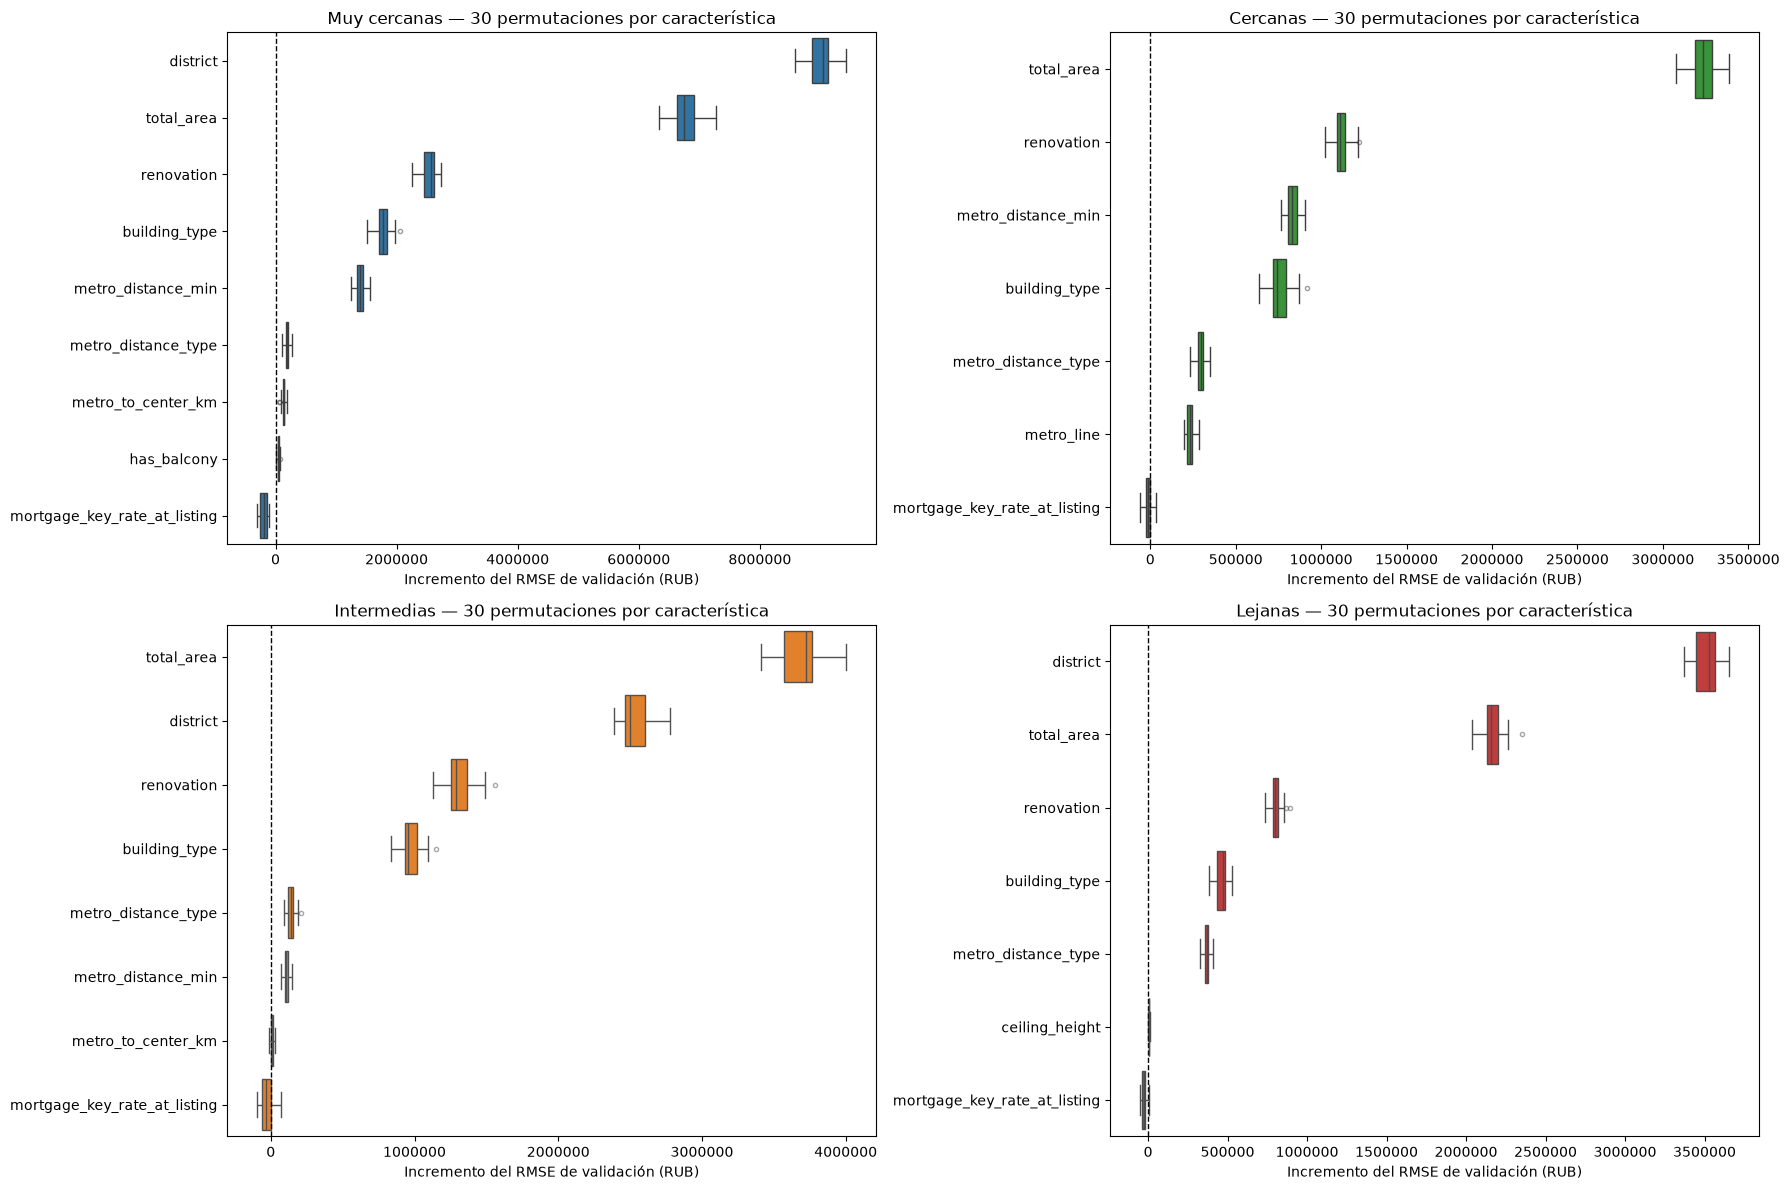

In [25]:
colores_bss = {"Muy cercanas":"#1f77b4", "Cercanas":"#2ca02c", "Intermedias":"#ff7f0e", "Lejanas":"#d62728"}
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for ax, segmento in zip(axes.flat, orden_segmentos):
    orden_importancia = importancias_bss[segmento]["Característica"].tolist()
    sns.boxplot(data=permutaciones_bss[segmento], y="Característica", x="ΔRMSE RUB", order=orden_importancia,
                color=colores_bss[segmento], ax=ax, flierprops={"markersize":3,"alpha":0.5})
    ax.axvline(0,color="black",linestyle="--",linewidth=1)
    ax.set(title=f"{segmento} — 30 permutaciones por característica", xlabel="Incremento del RMSE de validación (RUB)",ylabel="")
    ax.ticklabel_format(axis="x",style="plain",useOffset=False)
plt.tight_layout()
plt.show()

**Muy cercanas: importancia agrupada sobre validación**

| Característica | Importancia media (ΔRMSE RUB) | Importancia mediana (ΔRMSE RUB) | Desviación estándar | Repeticiones válidas | Posición |
| --- | --- | --- | --- | --- | --- |
| district | 8.995.146,203490 | 9.043.298,982121 | 215.391,271396 | 30 | 1 |
| total_area | 6.769.033,236845 | 6.748.611,240177 | 203.088,305112 | 30 | 2 |
| renovation | 2.543.548,505827 | 2.563.987,309753 | 124.121,065382 | 30 | 3 |
| building_type | 1.774.087,525264 | 1.779.026,756480 | 129.882,836000 | 30 | 4 |
| metro_distance_min | 1.391.270,314796 | 1.397.904,879101 | 77.142,867255 | 30 | 5 |
| metro_distance_type | 191.286,662693 | 192.565,117877 | 32.274,521177 | 30 | 6 |
| metro_to_center_km | 132.356,828666 | 143.180,289255 | 29.547,042665 | 30 | 7 |
| has_balcony | 42.520,225395 | 43.908,500543 | 13.057,977544 | 30 | 8 |
| mortgage_key_rate_at_listing | -199.705,666686 | -191.437,821967 | 58.697,704637 | 30 | 9 |

**Cercanas: importancia agrupada sobre validación**

| Característica | Importancia media (ΔRMSE RUB) | Importancia mediana (ΔRMSE RUB) | Desviación estándar | Repeticiones válidas | Posición |
| --- | --- | --- | --- | --- | --- |
| total_area | 3.238.248,580699 | 3.237.027,498456 | 78.455,150428 | 30 | 1 |
| renovation | 1.114.465,554776 | 1.109.610,740691 | 48.875,051076 | 30 | 2 |
| metro_distance_min | 831.073,678407 | 826.935,368143 | 38.019,489636 | 30 | 3 |
| building_type | 758.211,751246 | 742.145,950215 | 65.796,973848 | 30 | 4 |
| metro_distance_type | 295.614,686199 | 298.096,778887 | 29.280,995660 | 30 | 5 |
| metro_line | 231.176,032413 | 230.193,658443 | 21.730,699688 | 30 | 6 |
| mortgage_key_rate_at_listing | -11.962,793298 | -14.198,712976 | 20.772,792902 | 30 | 7 |

**Intermedias: importancia agrupada sobre validación**

| Característica | Importancia media (ΔRMSE RUB) | Importancia mediana (ΔRMSE RUB) | Desviación estándar | Repeticiones válidas | Posición |
| --- | --- | --- | --- | --- | --- |
| total_area | 3.691.639,168064 | 3.723.661,708240 | 152.710,417416 | 30 | 1 |
| district | 2.533.127,880288 | 2.499.815,333034 | 99.432,714684 | 30 | 2 |
| renovation | 1.314.870,351889 | 1.285.511,439826 | 102.973,633305 | 30 | 3 |
| building_type | 972.101,142830 | 953.571,892883 | 66.640,754724 | 30 | 4 |
| metro_distance_type | 139.100,620793 | 139.718,760497 | 26.511,932366 | 30 | 5 |
| metro_distance_min | 108.403,962970 | 107.638,832538 | 19.273,649970 | 30 | 6 |
| metro_to_center_km | 9.734,446091 | 10.971,800711 | 9.770,731539 | 30 | 7 |
| mortgage_key_rate_at_listing | -29.427,808306 | -33.498,041405 | 42.170,007406 | 30 | 8 |

**Lejanas: importancia agrupada sobre validación**

| Característica | Importancia media (ΔRMSE RUB) | Importancia mediana (ΔRMSE RUB) | Desviación estándar | Repeticiones válidas | Posición |
| --- | --- | --- | --- | --- | --- |
| district | 3.511.982,764227 | 3.530.436,715389 | 76.611,561753 | 30 | 1 |
| total_area | 2.169.287,641295 | 2.156.657,115006 | 64.664,462126 | 30 | 2 |
| renovation | 802.590,871006 | 799.070,452102 | 33.576,655517 | 30 | 3 |
| building_type | 462.073,580632 | 469.029,190271 | 36.825,051142 | 30 | 4 |
| metro_distance_type | 369.320,250992 | 368.743,103356 | 19.531,394393 | 30 | 5 |
| ceiling_height | 6.118,788248 | 6.558,555812 | 3.841,933174 | 30 | 6 |
| mortgage_key_rate_at_listing | -25.677,334584 | -28.319,169343 | 14.023,550020 | 30 | 7 |

**Reajuste final y evaluación única sobre test.** Los subconjuntos ya están congelados. Se reajusta cada BSS con las mismas filas completas de train del OLS de referencia, utilizando su respuesta Box-Cox y su λ originales. Las características nominales incorporan todas sus columnas estimables del contrato original. Test recibe una única predicción BSS por segmento; no se utiliza para cambiar el subconjunto.

El OLS de referencia es el experimento sin `to_center_km`. Sus métricas se recuperan de los resultados guardados, sin evaluarlo nuevamente para decidir selecciones. Las tablas diferencian RUB y Box-Cox y muestran tanto cambios con signo (BSS − referencia) como su magnitud absoluta. El VIF final puede variar respecto del subtrain; si supera 5 se registra sin reajustar retrospectivamente la selección. AIC/BIC no se comparan entre segmentos con λ diferentes.

In [26]:
modelos_bss = {}
evaluacion_final_bss = {}
comparaciones_finales_bss = {}
multicolinealidad_final_bss = {}
registro_final_bss = {}
for segmento in orden_segmentos:
    base = referencia_bss["modelos"][segmento]
    indices = base.model.data.row_labels
    elegidas = selecciones_congeladas_bss[segmento]
    contrato = contratos_bss[segmento]
    columnas = [c for f in elegidas for c in contrato[f]["columnas_modelo"]]
    assert "to_center_km" not in columnas
    assert validar_bloques_features(columnas, contrato)
    A = sm.add_constant(train.loc[indices,columnas],has_constant="add")
    assert np.linalg.matrix_rank(A.to_numpy()) == A.shape[1]
    y = pd.Series(base.model.endog,index=indices,name="boxcox_price_rub")
    if cache_bss is None:
        modelo = sm.OLS(y,A,missing="raise").fit()
    else:
        modelo = cache_bss["modelos_finales"][segmento]
        assert modelo.model.exog_names == A.columns.tolist()
        np.testing.assert_array_equal(modelo.model.exog, A.to_numpy())
        np.testing.assert_array_equal(modelo.model.endog, y.to_numpy())
    modelos_bss[segmento] = modelo
    lam = parametros_recargados["lambda_por_segmento"][segmento]
    pt,ok = inversa(modelo.predict(A),lam)
    assert ok.all()
    met_train = errores(train.loc[indices,"price_rub"],pt)
    # Acceso a test solo después de congelar todas las selecciones.
    mascara_test = test_segmentado_ols.segmento_distancia.eq(segmento)
    B = sm.add_constant(test.loc[mascara_test,columnas],has_constant="add").reindex(columns=A.columns)
    pred_test,ok = inversa(modelo.predict(B),lam)
    assert ok.all(), "Inversa inválida: no recortar ni modificar la selección con test."
    met_test = errores(test.loc[mascara_test,"price_rub"],pred_test)
    evaluacion_final_bss[segmento] = {"train_RUB":met_train,"test_RUB":met_test}
    bloques_finales = {f:contrato[f]["columnas_modelo"] for f in elegidas}
    vif_bss = vif_features(modelo,bloques_finales)
    multicolinealidad_final_bss[segmento] = vif_bss
    anterior_vif = referencia_bss["tablas"][segmento]["vif"]
    anteriores_por_feature = {f:anterior_vif.loc[anterior_vif.Predictor.isin(v["columnas_modelo"]),"VIF"].max()
                              for f,v in contrato.items() if v["estado"]=="Incluida"}
    eval_base = referencia_bss["evaluaciones"][segmento]
    e_train = eval_base.loc[eval_base.Conjunto.eq("Train") & eval_base.Escala.eq("RUB")].iloc[0]
    e_test = eval_base.loc[eval_base.Conjunto.eq("Test") & eval_base.Escala.eq("RUB")].iloc[0]
    assert int(e_train["N total"])==len(indices) and int(e_test["N total"])==int(mascara_test.sum())
    antes = {"Características":sum(v["estado"]=="Incluida" for v in contrato.values()),"Parámetros (con intercepto)":len(base.params),
        "R² train (RUB)":e_train["R²"],"R² ajustado train (Box-Cox)":base.rsquared_adj,"R² test (RUB)":e_test["R²"],
        "MAE test (RUB)":e_test["MAE"],"RMSE test (RUB)":e_test["RMSE"],"VIF máximo":anterior_vif.VIF.max(),
        "Características con VIF > 5":sum(v>5 for v in anteriores_por_feature.values())}
    despues = {"Características":len(elegidas),"Parámetros (con intercepto)":len(modelo.params),
        "R² train (RUB)":met_train["R2"],"R² ajustado train (Box-Cox)":modelo.rsquared_adj,"R² test (RUB)":met_test["R2"],
        "MAE test (RUB)":met_test["MAE"],"RMSE test (RUB)":met_test["RMSE"],"VIF máximo":vif_bss["VIF máximo"].max(),
        "Características con VIF > 5":int(vif_bss["VIF máximo"].gt(5).sum())}
    comparacion = pd.DataFrame({"OLS referencia":antes,"OLS BSS":despues})
    comparacion["Cambio BSS − referencia"] = comparacion["OLS BSS"]-comparacion["OLS referencia"]
    comparacion["Diferencia absoluta"] = comparacion["Cambio BSS − referencia"].abs()
    comparaciones_finales_bss[segmento] = comparacion.rename_axis("Métrica").reset_index()
    registro_final_bss[segmento] = {"features":elegidas,"columnas":columnas,"lambda_final":lam,
        "lambda_interno":busquedas_bss[segmento]["lambda_interno"],"n_train":len(indices),"n_test":int(mascara_test.sum()),
        "r2_test_rub":met_test["R2"],"rmse_test_rub":met_test["RMSE"],"VIF_maximo_final":float(vif_bss["VIF máximo"].max())}
assert hashlib.sha256(json.dumps(selecciones_congeladas_bss,sort_keys=True).encode()).hexdigest()==huella_seleccion_bss
assert sum(r["n_train"] for r in registro_final_bss.values())==40_000
assert sum(r["n_test"] for r in registro_final_bss.values())==10_000

**Muy cercanas: OLS referencia frente a BSS, mismas observaciones**

| Métrica | OLS referencia | OLS BSS | Cambio BSS − referencia | Diferencia absoluta |
| --- | --- | --- | --- | --- |
| Características | 19 | 9 | -10 | 10 |
| Parámetros (con intercepto) | 93 | 73 | -20 | 20 |
| R² train (RUB) | 0,929915 | 0,899122 | -0,030794 | 0,030794 |
| R² ajustado train (Box-Cox) | 0,940480 | 0,909787 | -0,030693 | 0,030693 |
| R² test (RUB) | 0,724371 | 0,903018 | 0,178647 | 0,178647 |
| MAE test (RUB) | 4.088.037,691719 | 2.324.408,974683 | -1.763.628,717036 | 1.763.628,717036 |
| RMSE test (RUB) | 6.024.280,848282 | 3.573.451,175506 | -2.450.829,672776 | 2.450.829,672776 |
| VIF máximo | 4,745929 | 2,363073 | -2,382856 | 2,382856 |
| Características con VIF > 5 | 0 | 0 | 0 | 0 |

**Muy cercanas: multicolinealidad final por característica**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| district | 2,363073 | 0 | 1,004889 |
| building_type | 1,728042 | 0 | 1,003079 |
| metro_distance_min | 1,570886 | 0 | No aplica |
| metro_distance_type | 1,505756 | 0 | No aplica |
| metro_to_center_km | 1,409629 | 0 | No aplica |
| renovation | 1,230410 | 0 | 1,002953 |
| has_balcony | 1,008290 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,008270 | 0 | No aplica |
| total_area | 1,005049 | 0 | No aplica |

**Cercanas: OLS referencia frente a BSS, mismas observaciones**

| Métrica | OLS referencia | OLS BSS | Cambio BSS − referencia | Diferencia absoluta |
| --- | --- | --- | --- | --- |
| Características | 19 | 7 | -12 | 12 |
| Parámetros (con intercepto) | 113 | 24 | -89 | 89 |
| R² train (RUB) | 0,909590 | 0,680667 | -0,228923 | 0,228923 |
| R² ajustado train (Box-Cox) | 0,916693 | 0,702660 | -0,214033 | 0,214033 |
| R² test (RUB) | 0,716522 | 0,700016 | -0,016505 | 0,016505 |
| MAE test (RUB) | 2.422.493,430648 | 2.546.880,006790 | 124.386,576142 | 124.386,576142 |
| RMSE test (RUB) | 3.316.995,278618 | 3.412.193,437155 | 95.198,158537 | 95.198,158537 |
| VIF máximo | 6,055374 | 1,851006 | -4,204369 | 4,204369 |
| Características con VIF > 5 | 1 | 0 | -1 | 1 |

**Cercanas: multicolinealidad final por característica**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_line | 1,851006 | 0 | 1,006039 |
| building_type | 1,723047 | 0 | 1,000817 |
| metro_distance_type | 1,595124 | 0 | No aplica |
| metro_distance_min | 1,571506 | 0 | No aplica |
| renovation | 1,231180 | 0 | 1,000952 |
| mortgage_key_rate_at_listing | 1,002866 | 0 | No aplica |
| total_area | 1,002366 | 0 | No aplica |

**Intermedias: OLS referencia frente a BSS, mismas observaciones**

| Métrica | OLS referencia | OLS BSS | Cambio BSS − referencia | Diferencia absoluta |
| --- | --- | --- | --- | --- |
| Características | 19 | 8 | -11 | 11 |
| Parámetros (con intercepto) | 102 | 81 | -21 | 21 |
| R² train (RUB) | 0,895160 | 0,857870 | -0,037290 | 0,037290 |
| R² ajustado train (Box-Cox) | 0,915689 | 0,873186 | -0,042503 | 0,042503 |
| R² test (RUB) | 0,615884 | 0,871011 | 0,255128 | 0,255128 |
| MAE test (RUB) | 2.188.779,347526 | 1.237.872,753144 | -950.906,594383 | 950.906,594383 |
| RMSE test (RUB) | 3.238.460,386463 | 1.876.647,462759 | -1.361.812,923704 | 1.361.812,923704 |
| VIF máximo | 4,818413 | 2,200392 | -2,618020 | 2,618020 |
| Características con VIF > 5 | 0 | 0 | 0 | 0 |

**Intermedias: multicolinealidad final por característica**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_distance_type | 2,200392 | 0 | No aplica |
| metro_distance_min | 2,054090 | 0 | No aplica |
| district | 2,049898 | 0 | 1,006709 |
| metro_to_center_km | 1,800745 | 0 | No aplica |
| building_type | 1,751087 | 0 | 1,003406 |
| renovation | 1,232894 | 0 | 1,003959 |
| total_area | 1,007456 | 0 | No aplica |
| mortgage_key_rate_at_listing | 1,007308 | 0 | No aplica |

**Lejanas: OLS referencia frente a BSS, mismas observaciones**

| Métrica | OLS referencia | OLS BSS | Cambio BSS − referencia | Diferencia absoluta |
| --- | --- | --- | --- | --- |
| Características | 19 | 7 | -12 | 12 |
| Parámetros (con intercepto) | 89 | 67 | -22 | 22 |
| R² train (RUB) | 0,945920 | 0,919392 | -0,026528 | 0,026528 |
| R² ajustado train (Box-Cox) | 0,962219 | 0,936850 | -0,025369 | 0,025369 |
| R² test (RUB) | 0,808972 | 0,928259 | 0,119287 | 0,119287 |
| MAE test (RUB) | 1.296.355,078748 | 697.562,443332 | -598.792,635416 | 598.792,635416 |
| RMSE test (RUB) | 1.829.847,196729 | 1.121.374,036739 | -708.473,159990 | 708.473,159990 |
| VIF máximo | 14,693602 | 3,043131 | -11,650471 | 11,650471 |
| Características con VIF > 5 | 1 | 0 | -1 | 1 |

**Lejanas: multicolinealidad final por característica**

| Característica | VIF máximo | Columnas VIF >5 | GVIF ajustado |
| --- | --- | --- | --- |
| metro_distance_type | 3,043131 | 0 | No aplica |
| district | 2,667481 | 0 | 1,010909 |
| building_type | 1,713940 | 0 | 1,039329 |
| ceiling_height | 1,431091 | 0 | No aplica |
| renovation | 1,233715 | 0 | 1,003068 |
| mortgage_key_rate_at_listing | 1,006553 | 0 | No aplica |
| total_area | 1,004879 | 0 | No aplica |

In [27]:
if cache_bss is None:
    configuracion_bss = {s:{"features":list(b["seleccionadas"]), "lambda_interno":b["lambda_interno"],
        "candidatas_totales":b["candidatas_totales"], "candidatas_evaluadas":b["candidatas_evaluadas"]}
        for s,b in busquedas_bss.items()}
    preparador_validacion = {k:preparador_bss[k] for k in ["imputacion","binarias","encoder","mapa"]}
    joblib.dump({"modelos_finales":modelos_bss,
        "modelos_validacion":{s:b["modelo_interno"] for s,b in busquedas_bss.items()},
        "seleccion":configuracion_bss,"preparador_validacion":preparador_validacion,
        "busqueda":{s:{k:b[k] for k in ["version","firma","completa","estadisticas","ganador","minimo_rmse_factible"]} for s,b in busquedas_bss.items()},
        "configuracion":{"corte":corte_bss,"version_busqueda":VERSION_BUSQUEDA,"firma_contexto":firma_contexto_bss,"tolerancia_rmse":TOLERANCIA_RMSE_BSS,
                          "semilla":SEMILLA_BSS,"repeticiones":REPETICIONES_PERMUTACION_BSS},
        "dependencias":{"preparacion":"../transformadores_ols_usadas.joblib","segmentacion":"../modelos_ols_por_segmento.joblib"}},
        ruta_bss, compress=3)
assert sum(r["n_train"] for r in registro_final_bss.values())==40_000
assert sum(r["n_test"] for r in registro_final_bss.values())==10_000
assert all(hashlib.sha256((carpeta_datos / nombre).read_bytes()).hexdigest()==huella for nombre,huella in huellas_entrada.items())
resumen_final_bss = pd.DataFrame([{"Segmento":s, "Candidatas":len(busquedas_bss[s]["candidatas_totales"]),
    "Subconjuntos considerados":busquedas_bss[s]["estadisticas"]["subconjuntos_considerados"],
    "Seleccionadas":", ".join(selecciones_congeladas_bss[s]),
    "Features":len(selecciones_congeladas_bss[s]), "Parámetros":len(modelos_bss[s].params),
    "R² train RUB":evaluacion_final_bss[s]["train_RUB"]["R2"],
    "R² ajustado train Box-Cox":modelos_bss[s].rsquared_adj,
    "R² test RUB":evaluacion_final_bss[s]["test_RUB"]["R2"],
    "MAE test RUB":evaluacion_final_bss[s]["test_RUB"]["MAE"],
    "RMSE test RUB":evaluacion_final_bss[s]["test_RUB"]["RMSE"],
    "VIF máximo":registro_final_bss[s]["VIF_maximo_final"],
    "Features VIF > 5":int(multicolinealidad_final_bss[s]["VIF máximo"].gt(5).sum()),
    "Δ R² test RUB":float(comparaciones_finales_bss[s].set_index("Métrica").loc["R² test (RUB)","Cambio BSS − referencia"]),
    "Δ RMSE test RUB":float(comparaciones_finales_bss[s].set_index("Métrica").loc["RMSE test (RUB)","Cambio BSS − referencia"]),
    "Reducción de parámetros":len(referencia_bss["modelos"][s].params)-len(modelos_bss[s].params),
    "Reducción VIF máximo":float(referencia_bss["tablas"][s]["vif"].VIF.max()-registro_final_bss[s]["VIF_maximo_final"])}
    for s in orden_segmentos])

resumen_final_bss_markdown = resumen_final_bss.set_index("Segmento").T.rename_axis("Métrica").reset_index()


**Comparación general de los cuatro modelos BSS exhaustivos**

| Métrica | Muy cercanas | Cercanas | Intermedias | Lejanas |
| --- | --- | --- | --- | --- |
| Candidatas | 19 | 19 | 19 | 19 |
| Subconjuntos considerados | 524.288 | 524.288 | 524.288 | 524.288 |
| Seleccionadas | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_to_center_km, has_balcony, metro_distance_type, district, building_type, renovation | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_distance_type, building_type, renovation, metro_line | total_area, metro_distance_min, mortgage_key_rate_at_listing, metro_to_center_km, metro_distance_type, district, building_type, renovation | total_area, ceiling_height, mortgage_key_rate_at_listing, metro_distance_type, district, building_type, renovation |
| Features | 9 | 7 | 8 | 7 |
| Parámetros | 73 | 24 | 81 | 67 |
| R² train RUB | 0,899122 | 0,680667 | 0,857870 | 0,919392 |
| R² ajustado train Box-Cox | 0,909787 | 0,702660 | 0,873186 | 0,936850 |
| R² test RUB | 0,903018 | 0,700016 | 0,871011 | 0,928259 |
| MAE test RUB | 2.324.408,974683 | 2.546.880,006790 | 1.237.872,753144 | 697.562,443332 |
| RMSE test RUB | 3.573.451,175506 | 3.412.193,437155 | 1.876.647,462759 | 1.121.374,036739 |
| VIF máximo | 2,363073 | 1,851006 | 2,200392 | 3,043131 |
| Features VIF > 5 | 0 | 0 | 0 | 0 |
| Δ R² test RUB | 0,178647 | -0,016505 | 0,255128 | 0,119287 |
| Δ RMSE test RUB | -2.450.829,672776 | 95.198,158537 | -1.361.812,923704 | -708.473,159990 |
| Reducción de parámetros | 20 | 89 | 21 | 22 |
| Reducción VIF máximo | 2,382856 | 4,204369 | 2,618020 | 11,650471 |

## 16. Archivos necesarios y política de persistencia

Auditoría realizada antes de retirar archivos. Se conservan cuatro CSV necesarios y cuatro Joblib. Los parámetros de preparación tienen una única fuente en el transformador; los cuartiles y λ externos viven en el OLS original. Los demás modelos no duplican esa configuración. Los modelos internos BSS se conservan porque permiten reproducir la validación y sus permutaciones sin entrenar nuevamente; los λ internos y el preparador de subtrain se mantienen separados de la preparación final.

La ejecución recupera y valida las matrices de los modelos existentes. Si no existen artefactos, el flujo permite construirlos; durante esta reorganización se reutilizan todos los entrenados, sin cambiar coeficientes. Recuperar BSS no repite su búsqueda: las selecciones permanecen congeladas, los diagnósticos se recalculan desde los modelos y los resultados históricos siguen en las celdas Markdown.

**Regla para próximas etapas:** no generar archivos de auditoría, métricas, rankings o resultados intermedios salvo que sean indispensables para una etapa posterior. Notebooks para análisis y documentación; CSV para datasets necesarios; Joblib para modelos y transformadores. JSON solo si una configuración indispensable no está ya en un Joblib.

| Archivo (data/) | Función | Dependencias resueltas | Decisión |
| --- | --- | --- | --- |
| bss_features/modelos_bss_features.joblib | Modelos finales y de validación, selección congelada y preparación interna aprendida. | Modelo_OLS/BSS | Conservar; retirar métricas, rankings y permutaciones persistidas |
| bss_features/permutaciones_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/permutaciones_intermedias.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/permutaciones_lejanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/permutaciones_muy_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/ranking_subtrain_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/ranking_subtrain_intermedias.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/ranking_subtrain_lejanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/ranking_subtrain_muy_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/registro_bss_features.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| bss_features/selecciones_congeladas.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| bss_features/subconjuntos_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/subconjuntos_intermedias.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/subconjuntos_lejanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| bss_features/subconjuntos_muy_cercanas.csv | Resultados BSS intermedios (subconjuntos, rankings o permutaciones); regenerables. | Modelo_OLS; resultados relevantes conservados en Markdown y gráficos | Eliminar y desactivar exportación |
| contratos_features_ols.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| metadatos_test_ols_usadas.csv | ID y fecha por fila: correspondencia y validación temporal interna. | Preparacion_OLS_Usadas; Modelo_OLS/BSS | Conservar |
| metadatos_train_ols_usadas.csv | ID y fecha por fila: correspondencia y validación temporal interna. | Preparacion_OLS_Usadas; Modelo_OLS/BSS | Conservar |
| modelos_ols_por_segmento.joblib | OLS originales y única configuración externa de segmentación y Box-Cox. | Modelo_OLS y etapas posteriores | Conservar, comprimir sin pérdida |
| modelos_ols_sin_to_center_km.joblib | OLS del experimento y columnas necesarias para recuperar predicciones. | Modelo_OLS/BSS | Conservar modelos; retirar tablas y configuración duplicadas |
| parametros_boxcox_usadas.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| registro_modelos_ols_usadas.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| registro_ols_sin_to_center_km.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| registro_transformaciones_ols_usadas.json | Auditoría o configuración ya disponible en transformadores/modelos Joblib o derivable de ellos. | Lecturas migradas a Joblib o contratos en memoria | Eliminar después de resolver dependencias |
| test_ols_usadas.csv | Dataset numérico de modelado; no se sobrescribe si ya existe. | Preparacion_OLS_Usadas; Modelo_OLS | Conservar |
| train_ols_usadas.csv | Dataset numérico de modelado; no se sobrescribe si ya existe. | Preparacion_OLS_Usadas; Modelo_OLS | Conservar |
| transformadores_ols_usadas.joblib | Codificador y parámetros de preparación; única fuente de imputación y esquema. | Preparacion_OLS_Usadas; Modelo_OLS/BSS | Conservar y retirar auditoría redundante interna |

## 17. Registro de experimentos en DagsHub — Fase 2

Se recuperan los resultados guardados de análisis, preparación, OLS y BSS, incluidos los modelos limitados conservados en Git. El registro no ajusta coeficientes ni ejecuta búsquedas. Las identidades combinan configuración, código y huellas de datos; los runs finalizados equivalentes se verifican y reutilizan, las versiones nuevas reciben otro nombre y las coincidencias ambiguas se informan.

El preprocesador compartido se registra una sola vez. Cada run contiene únicamente su modelo y una referencia a los transformadores y límites adecuados. Los temporales se crean fuera del repositorio y se eliminan al terminar. El mínimo de validación y el número de modelos admisibles del BSS limitado no se conservaron: se informa esa ausencia, sin reconstruir la búsqueda.

In [ ]:
from registro_experimentos import (preparar_registro, conectar, pendientes, registrar_experimentos)

plan_registro_fase2 = preparar_registro(raiz)
cliente_fase2 = conectar(raiz)
pendientes_fase2 = pendientes(plan_registro_fase2, cliente_fase2)


In [ ]:
PUBLICAR_EN_DAGSHUB = True  # Publicación autorizada explícitamente por el usuario.
seguimiento_fase2 = (registrar_experimentos(plan_registro_fase2, cliente_fase2)
                     if PUBLICAR_EN_DAGSHUB else pendientes_fase2.copy())
# La tabla Markdown siguiente conserva el seguimiento de la última verificación.


**Seguimiento del registro remoto**

| Run | Estado | Run ID | Enlace |
| --- | --- | --- | --- |
| F2_00_Analisis_Outliers | Registrado y verificado | 09d44a7be1124eee8abee2ebb2219894 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/09d44a7be1124eee8abee2ebb2219894 |
| F2_01_Preparacion_Datos | Registrado y verificado | a0a7474fafd3479db8b2e9a209ee5993 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/a0a7474fafd3479db8b2e9a209ee5993 |
| F2_02_Segmentacion_BoxCox | Registrado y verificado | 55221b3ffc6f437db62496e1c1d7862c | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/55221b3ffc6f437db62496e1c1d7862c |
| F2_03_OLS_Muy_Cercanas | Registrado y verificado | 5c2a626101d24398a5b2d1e4139eefd2 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/5c2a626101d24398a5b2d1e4139eefd2 |
| F2_03_OLS_Cercanas | Registrado y verificado | 8aa224e97987443b8ee703e4b2805f92 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/8aa224e97987443b8ee703e4b2805f92 |
| F2_03_OLS_Intermedias | Registrado y verificado | 571074c97b444213bd563159f1f833ac | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/571074c97b444213bd563159f1f833ac |
| F2_03_OLS_Lejanas | Registrado y verificado | 3bd7afdfd01d4d3cb9d953645222c6fe | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/3bd7afdfd01d4d3cb9d953645222c6fe |
| F2_04_OLS_SinCentro_Muy_Cercanas | Registrado y verificado | eea468f20f1b47168167e925b43495db | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/eea468f20f1b47168167e925b43495db |
| F2_04_OLS_SinCentro_Cercanas | Registrado y verificado | 84adeec6d87946a4ade6e0254f6aa6a8 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/84adeec6d87946a4ade6e0254f6aa6a8 |
| F2_04_OLS_SinCentro_Intermedias | Registrado y verificado | 8ef21faff5fc4b0eb8683c07fbe24992 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/8ef21faff5fc4b0eb8683c07fbe24992 |
| F2_04_OLS_SinCentro_Lejanas | Registrado y verificado | 18fe8fdeaf5c4fb6b8c6c4d52bfda563 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/18fe8fdeaf5c4fb6b8c6c4d52bfda563 |
| F2_05_BSS_Limitado_Muy_Cercanas | Registrado y verificado | cbac3b56433e4c14b54add1f478a8dbe | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/cbac3b56433e4c14b54add1f478a8dbe |
| F2_05_BSS_Limitado_Cercanas | Registrado y verificado | 4292b21108704659ac29cb17bc0e8bc0 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/4292b21108704659ac29cb17bc0e8bc0 |
| F2_05_BSS_Limitado_Intermedias | Registrado y verificado | b02b11bb1ace4eb6b35d34e459c856c6 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/b02b11bb1ace4eb6b35d34e459c856c6 |
| F2_05_BSS_Limitado_Lejanas | Registrado y verificado | eceebd267b7a4469b4336c2d05ccc71a | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/eceebd267b7a4469b4336c2d05ccc71a |
| F2_06_BSS_Exhaustivo_Muy_Cercanas | Registrado y verificado | b07fa123198643ff8011eeb0239c6167 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/b07fa123198643ff8011eeb0239c6167 |
| F2_06_BSS_Exhaustivo_Cercanas | Registrado y verificado | 58e5d08bf8f9491ab07fa26c14260ad9 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/58e5d08bf8f9491ab07fa26c14260ad9 |
| F2_06_BSS_Exhaustivo_Intermedias | Registrado y verificado | b5b162d1248b42a985a6858a59d47bfe | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/b5b162d1248b42a985a6858a59d47bfe |
| F2_06_BSS_Exhaustivo_Lejanas | Registrado y verificado | fe8461e4b30740b88ec9c6e4e12a4275 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/fe8461e4b30740b88ec9c6e4e12a4275 |
| F2_07_Comparacion_General | Registrado y verificado | edf076e934834e49aa29c08b45a306c0 | https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/7/runs/edf076e934834e49aa29c08b45a306c0 |

Se verificaron las métricas y las huellas de cada artefacto descargado. No se reentrenaron modelos ni se repitió BSS. Los parámetros y resultados del BSS limitado proceden del historial de Git; su mínimo de validación y conteo de admisibles no estaban persistidos. No se publicaron CSV ni matrices de observaciones.